# ESC-50: Model Improvement and Comparative Evaluation

CNN, BiGRU, attention, audio augmentation and frozen PANNs features.

## Summary

The completed scratch-model study gives **72.61%** mean accuracy for the research CNN, **73.87%** for BiGRU and **74.37%** for channel attention. The earlier frozen PANNs + linear-head fit reached **91.21% accuracy / 91.10% macro-F1**. The original fixed PANNs fit was executed and reproduced on Colab. The current notebook defaults to recomputing its saved evidence; optional extraction/refitting is controlled explicitly. The completed transfer follow-up adds a matched noise evaluation and six fixed-budget head fits.

This notebook contains the full metric tables, paired source-bootstrap comparisons, class-level error analysis, experiment ledgers, literature review and **all 22 original scientific figures plus four new follow-up figures**. Saved scratch-model results are presented as existing experiments; running this notebook does not retrain their 60 neural fits.

All main comparisons use **398 development-validation clips from 295 sources**. All official folds have historical exposure. These results are not untouched-test confirmation or a standard five-fold benchmark.

The Gaussian-to-recorded-noise extension adds two matched linear head fits: primary recorded-panel difference **+1.05 pp [-0.54, +2.59]**, with a **+0.75 pp** clean change. All **36** scientific figures are retained.

## 1. Context and methods

| Checkpoint requirement | Work included |
| --- | --- |
| Analyse the baseline | Architecture, per-class errors, noise sensitivity and persistent failures |
| Implement improvements | BiGRU, temporal/channel attention, Gaussian noise, masking and Mixup |
| Compare an alternative | Frozen AudioSet-pretrained Cnn14_16k + linear classifier |
| Evaluate appropriately | Accuracy, macro-F1, all-class confusion, paired source-cluster intervals |
| Discuss findings | Clean accuracy, robustness, cost, limitations and the next experiment |

### Key assumptions

- Train: folds 1–3, 1,200 clips. Validation: fold 4 after metadata source exclusions, 398 clips. Fold 5 is used only to define exclusions in the new run; its WAVs are not evaluated.
- Source isolation uses ESC-50 `src_file` identifiers. It does not establish perceptual deduplication or exclude pretraining overlap.
- Three scratch-model training seeds are repeated fits of the same recordings. Their sample SD is not a confidence interval over new audio.
- PANNs differs in external pretraining, capacity, frontend and classifier; its gain cannot be attributed to pretraining alone.
- The 49,058-parameter research CNN is different from the 1,368,386-parameter CNN in the team's original `esc50-baseline/`. No unmeasured score is assigned to that implementation.

### Locate the project

Use a GPU runtime in Colab for the new PANNs extraction. The default workflow reads and recomputes the completed original fit. Set `RUN_TRANSFER = True` only to repeat its extraction and single linear fit. The separate transfer-follow-up notebook executes the new fixed inference and head experiment, without fine-tuning or hyperparameter search.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, platform, time
from datetime import datetime, timezone

RUN_TRANSFER = False
configured_root = os.environ.get("ESC50_PROJECT_ROOT")
candidates = ([Path(configured_root)] if configured_root else []) + [Path.cwd(), Path.cwd().parent, Path.cwd()/"research/esc50_improvements",
              Path("/content/esc50_external"), Path("/content/esc50_followup")]
ROOT = next((p for p in candidates if (p/"src/esc50_sound").is_dir()), None)
if ROOT is None:
    ROOT = Path("/content/esc50_followup")
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Richardafcs/esc-50-sound-classification.git", str(ROOT)],
                   check=True, capture_output=True, text=True, timeout=180)
os.chdir(ROOT)
sys.path.insert(0, str(ROOT/"src"))
print("Project:", ROOT.name)
print("Execution started (UTC):", datetime.now(timezone.utc).isoformat())

Project: esc50_project
Execution started (UTC): 2026-11-05T23:14:56.544564+00:00


In [2]:
# Install notebook and transfer dependencies before importing the numerical stack.
packages = ["numpy>=2,<3", "pandas>=2.2,<3", "matplotlib>=3.9,<4",
            "scikit-learn==1.6.1", "torchlibrosa==0.1.0", "librosa==0.11.0",
            "soundfile>=0.13,<1", "joblib>=1.4,<2"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages],
               check=True, capture_output=True, text=True, timeout=360)
print("Notebook dependencies are ready.")

Notebook dependencies are ready.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown, Image
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from esc50_sound.data import read_metadata, split_rows
from esc50_sound.models import build_model
from esc50_sound.prediction_errors import SourceBootstrap, read_predictions, paired_correctness

plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 70)
pd.set_option("display.max_columns", 12)
def table(frame, precision=3):
    display(frame.style.format(precision=precision, na_rep="—").hide(axis="index")
            .set_properties(**{"white-space": "normal", "text-align": "left", "max-width": "230px"}))

def load_csv(relative):
    return pd.read_csv(ROOT/relative)

runtime = {"python": platform.python_version(), "torch": torch.__version__,
           "numpy": np.__version__, "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
           "platform": platform.platform()}
table(pd.DataFrame(list(runtime.items()), columns=["Component", "Value"]))

Component,Value
python,3.13.16
torch,2.11.0+cu130
numpy,2.4.6
gpu,Tesla T4
platform,Linux-6.6.159+-x86_64-with-glibc2.39


## 2. Data and baseline implementation

The frontend resamples to 16 kHz and computes a 64-band natural-log Mel representation with a 512-point FFT and 256-sample hop. The main CNN retains frequency structure: three convolution blocks with 16/32/64 channels produce `[64, 8, 39]` features, then temporal averaging leaves 512 classifier inputs. BiGRU processes 39 tokens of width 512 with 64 units per direction. Models use cross-entropy, AdamW, a cosine schedule, 60 epochs and minimum validation cross-entropy checkpoint selection.

In [4]:
metadata = read_metadata(ROOT/"data/ESC-50")
roles = split_rows(metadata)
validation = sorted([metadata[i] for i in roles["validation"]], key=lambda row: row["filename"])
targets = np.array([int(row["target"]) for row in validation])
class_names = {int(row["target"]): row["category"] for row in metadata}
source_ids = [row["src_file"] for row in validation]
table(pd.DataFrame([{"Split": name, "Clips": len(indices),
                     "Sources": len({metadata[i]["src_file"] for i in indices})}
                    for name, indices in roles.items()]))
print("Validation classes:", len(np.unique(targets)))
print("Validation class support:", np.unique(np.bincount(targets)).tolist())

Split,Clips,Sources
train,1200,919
validation,398,295
test,400,310


Validation classes: 50
Validation class support: [7, 8]


In [5]:
architectures = ["cnn_freq", "crnn_freq", "crnn_freq_ta", "crnn_freq_ca", "crnn_freq_tca", "cnn_freq_matched", "cnn_freq_token"]
table(pd.DataFrame([{"Model": name, "Parameters": sum(p.numel() for p in build_model(name).parameters())}
                    for name in architectures]), precision=0)
print(build_model("crnn_freq_ca"))

Model,Parameters
cnn_freq,49058
crnn_freq,251810
crnn_freq_ta,251939
crnn_freq_ca,252906
crnn_freq_tca,253035
cnn_freq_matched,252036
cnn_freq_token,252036


RecurrentClassifier(
  (encoder): ConvolutionalEncoder(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (gru): GRU(512, 64, batch_first=True, bidirectional=True)
  (head): Sequential(
    (0): Dropout(p=0.2, inpla

## 3. New Colab run: frozen PANNs + linear classifier

The official later-code-version **Cnn14_16k** checkpoint supplies 2, 048-dimensional embeddings. All encoder parameters are frozen. The head is a training-only `StandardScaler` followed by L2 logistic regression (`C=1`, L-BFGS, `max_iter=3000`, `tol=1e-6`). No nominal three-seed repeats are created for a deterministic fixed head. The loaded backbone has 81, 033, 231 parameters, including the unused original AudioSet classifier; the ESC-50 linear head has 102, 450 parameters.

Sources: [PANNs repository](https://github.com/qiuqiangkong/audioset_tagging_cnn), [official checkpoint](https://zenodo.org/records/3987831), [PANNs paper](https://arxiv.org/abs/1912.10211). The 2020 paper's original 32 kHz five-fold recipe differs from this experiment.

In [6]:
import urllib.request, zipfile
ASSETS = Path("/content/esc50_panns") if Path("/content").exists() else ROOT/"results/panns_assets"
ASSETS.mkdir(parents=True, exist_ok=True)
PANN_REPO = ASSETS/"audioset_tagging_cnn"
CHECKPOINT = ASSETS/"Cnn14_16k_mAP=0.438.pth"
AUDIO_DATA = ASSETS/"ESC-50"
RUN_DIR = ROOT/"results/panns_notebook_run"

if RUN_TRANSFER:
    if not torch.cuda.is_available():
        raise RuntimeError("Select a GPU runtime in Colab for the new extraction, or use RUN_TRANSFER=False for saved results.")
    if not PANN_REPO.exists():
        subprocess.run(["git", "clone", "https://github.com/qiuqiangkong/audioset_tagging_cnn.git", str(PANN_REPO)],
                       check=True, capture_output=True, timeout=180)
    if not CHECKPOINT.exists():
        urllib.request.urlretrieve("https://zenodo.org/records/3987831/files/Cnn14_16k_mAP%3D0.438.pth?download=1", CHECKPOINT)
    if not (AUDIO_DATA/"audio").exists():
        archive = ASSETS/"esc50.zip"
        urllib.request.urlretrieve("https://codeload.github.com/karolpiczak/ESC-50/zip/refs/heads/master", archive)
        with zipfile.ZipFile(archive) as zipped:
            for member in zipped.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if relative.parts and relative.parts[0] in ("audio", "meta") and not member.is_dir():
                    destination = AUDIO_DATA/relative
                    destination.parent.mkdir(parents=True, exist_ok=True)
                    destination.write_bytes(zipped.read(member))
    print("Official model source, checkpoint and audio are ready.")
else:
    print("Saved-result mode: no extraction or fitting.")

Saved-result mode: no extraction or fitting.


In [7]:
if RUN_TRANSFER:
    if not (RUN_DIR/"summary.json").exists():
        command = [sys.executable, "-u", str(ROOT/"scripts/run_panns_linear_probe.py"),
                   "--audio-root", str(AUDIO_DATA/"audio"), "--metadata", str(AUDIO_DATA/"meta/esc50.csv"),
                   "--panns-repo", str(PANN_REPO), "--checkpoint", str(CHECKPOINT),
                   "--output", str(RUN_DIR), "--device", "cuda"]
        run_environment = os.environ.copy()
        run_environment.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")
        completed = subprocess.run(command, text=True, capture_output=True,
                                   env=run_environment, timeout=2700)
        RUN_DIR.mkdir(parents=True, exist_ok=True)
        (RUN_DIR/"execution.log").write_text(completed.stdout + completed.stderr)
        if completed.returncode:
            print((completed.stdout + completed.stderr)[-5000:])
            completed.check_returncode()
        print(completed.stdout[-1200:])
    else:
        print("Using the completed extraction and fit from this notebook session.")
    transfer_summary = json.loads((RUN_DIR/"summary.json").read_text())
    predictions = read_predictions(RUN_DIR/"validation_predictions.csv", validation)
else:
    RUN_DIR = ROOT/"reports/panns_20261105"
    transfer_summary = json.loads((RUN_DIR/"run_summary.json").read_text())
    predictions = read_predictions(RUN_DIR/"validation_predictions.csv", validation)

panns_accuracy = accuracy_score(targets, predictions)
panns_f1 = f1_score(targets, predictions, labels=range(50), average="macro", zero_division=0)
table(pd.DataFrame([{"Run": "New extraction and fit" if RUN_TRANSFER else "Earlier saved fit",
                     "Correct": int((predictions == targets).sum()), "Clips": len(targets),
                     "Accuracy (%)": 100*panns_accuracy, "Macro-F1 (%)": 100*panns_f1,
                     "Converged": transfer_summary["converged"]}]))
table(pd.DataFrame(list(transfer_summary["timing_seconds"].items()), columns=["Stage", "Seconds"]))
print("Test WAVs evaluated:", transfer_summary["test_waveforms_read"])
print("L-BFGS iterations:", transfer_summary["n_iter"])
print("Timing excludes downloads, installation and original external pretraining.")

Run,Correct,Clips,Accuracy (%),Macro-F1 (%),Converged
Earlier saved fit,363,398,91.206,91.103,True


Stage,Seconds
train_features,23.380
val_features,7.002
linear_fit,4.410
total,38.046


Test WAVs evaluated: 0
L-BFGS iterations: [137]
Timing excludes downloads, installation and original external pretraining.


### Paired comparisons from predictions

Accuracy is clip-weighted; macro-F1 averages 50 class F1 values with zero-division handled as zero. Source intervals resample 295 recording sources 4,000 times, retaining all clips from each sampled source and using the resulting clip count as denominator. The same draws are used for paired models. These intervals condition on the single PANNs fit and the three existing reference fits; they do not represent uncertainty over future training seeds.

In [8]:
reference_frame = load_csv("reports/panns_20261105/reference_predictions.csv").set_index("filename")
reference_frame = reference_frame.loc[[row["filename"] for row in validation]]
reference_specs = {"CNN": "B_cnn_freq_s{}", "BiGRU": "B_crnn_freq_s{}",
                   "Channel Attention": "B_crnn_freq_ca_s{}"}
reference_predictions = {name: np.column_stack([reference_frame[pattern.format(seed)].to_numpy(int)
                                               for seed in (101, 202, 303)])
                         for name, pattern in reference_specs.items()}
source_bootstrap = SourceBootstrap(source_ids, 4000, 20261105)
new_correct = predictions == targets
paired_rows, per_fit_rows = [], []
for name, pred in reference_predictions.items():
    old_correct = pred == targets[:, None]
    effect = source_bootstrap.summarize(new_correct[:, None].astype(float) - old_correct.astype(float))
    paired_rows.append({"Reference": name, "Gain (pp)": effect["delta_accuracy_pp"],
                        "95% lower (pp)": effect["source_bootstrap_low_pp"],
                        "95% upper (pp)": effect["source_bootstrap_high_pp"]})
    for column, seed in enumerate((101, 202, 303)):
        result = paired_correctness(old_correct[:, column], new_correct)
        per_fit_rows.append({"Reference": name, "Seed": seed, "Repaired": result["b_only_correct"],
                            "New errors": result["a_only_correct"], "Net correct": result["net_correct"]})
paired_results = pd.DataFrame(paired_rows)
table(paired_results)
table(pd.DataFrame(per_fit_rows), precision=0)

Reference,Gain (pp),95% lower (pp),95% upper (pp)
CNN,18.593,13.830,23.570
BiGRU,17.337,13.268,21.675
Channel Attention,16.834,12.613,21.347


Reference,Seed,Repaired,New errors,Net correct
CNN,101,87,13,74
CNN,202,87,12,75
CNN,303,86,13,73
BiGRU,101,79,15,64
BiGRU,202,81,12,69
BiGRU,303,88,14,74
Channel Attention,101,78,15,63
Channel Attention,202,77,11,66
Channel Attention,303,86,14,72


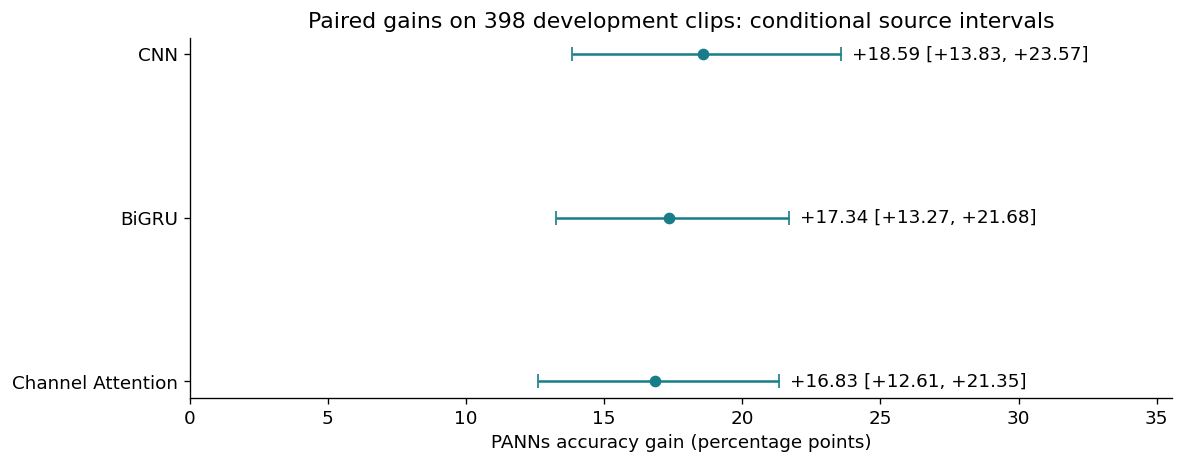

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for index, row in paired_results.iterrows():
    value, low, high = row["Gain (pp)"], row["95% lower (pp)"], row["95% upper (pp)"]
    ax.errorbar(value, index, xerr=[[value-low], [high-value]], fmt="o", capsize=4, color="#177e89")
    ax.text(high+0.4, index, f"{value:+.2f} [{low:+.2f}, {high:+.2f}]", va="center")
ax.set_yticks(range(len(paired_results)), paired_results["Reference"])
ax.set_xlim(0, paired_results["95% upper (pp)"].max()+12)
ax.set_xlabel("PANNs accuracy gain (percentage points)")
ax.set_title("Paired gains on 398 development clips: conditional source intervals")
ax.invert_yaxis()
fig.tight_layout(); plt.show()

### Class-level results and errors

There are only seven or eight validation recordings per class. Per-class differences are exploratory leads, not independent evidence from 24 recordings simply because three model fits were used.

In [10]:
report = classification_report(targets, predictions, labels=range(50),
                               target_names=[class_names[k] for k in range(50)],
                               output_dict=True, zero_division=0)
class_report = pd.DataFrame(report).T.iloc[:50].reset_index(names="Class")
table(class_report)
error_rows = [{"Filename": row["filename"], "Source": row["src_file"],
               "True class": row["category"], "Predicted class": class_names[int(pred)]}
              for row, pred in zip(validation, predictions) if int(row["target"]) != int(pred)]
table(pd.DataFrame(error_rows))

Class,precision,recall,f1-score,support
dog,1.000,1.000,1.000,8.000
rooster,1.000,1.000,1.000,8.000
pig,1.000,1.000,1.000,8.000
cow,1.000,1.000,1.000,8.000
frog,1.000,1.000,1.000,8.000
cat,0.889,1.000,0.941,8.000
hen,1.000,0.857,0.923,7.000
insects,1.000,0.875,0.933,8.000
sheep,1.000,1.000,1.000,8.000
crow,1.000,0.875,0.933,8.000


Filename,Source,True class,Predicted class
4-107122-A-33.wav,107122,door_wood_creaks,cat
4-125825-B-46.wav,125825,church_bells,door_wood_creaks
4-132816-A-26.wav,132816,laughing,crying_baby
4-143118-B-7.wav,143118,insects,airplane
4-144083-C-16.wav,144083,wind,siren
4-144085-A-16.wav,144085,wind,siren
4-156843-A-21.wav,156843,sneezing,coughing
4-157611-A-41.wav,157611,chainsaw,engine
4-157611-B-41.wav,157611,chainsaw,engine
4-161105-B-47.wav,161105,airplane,helicopter


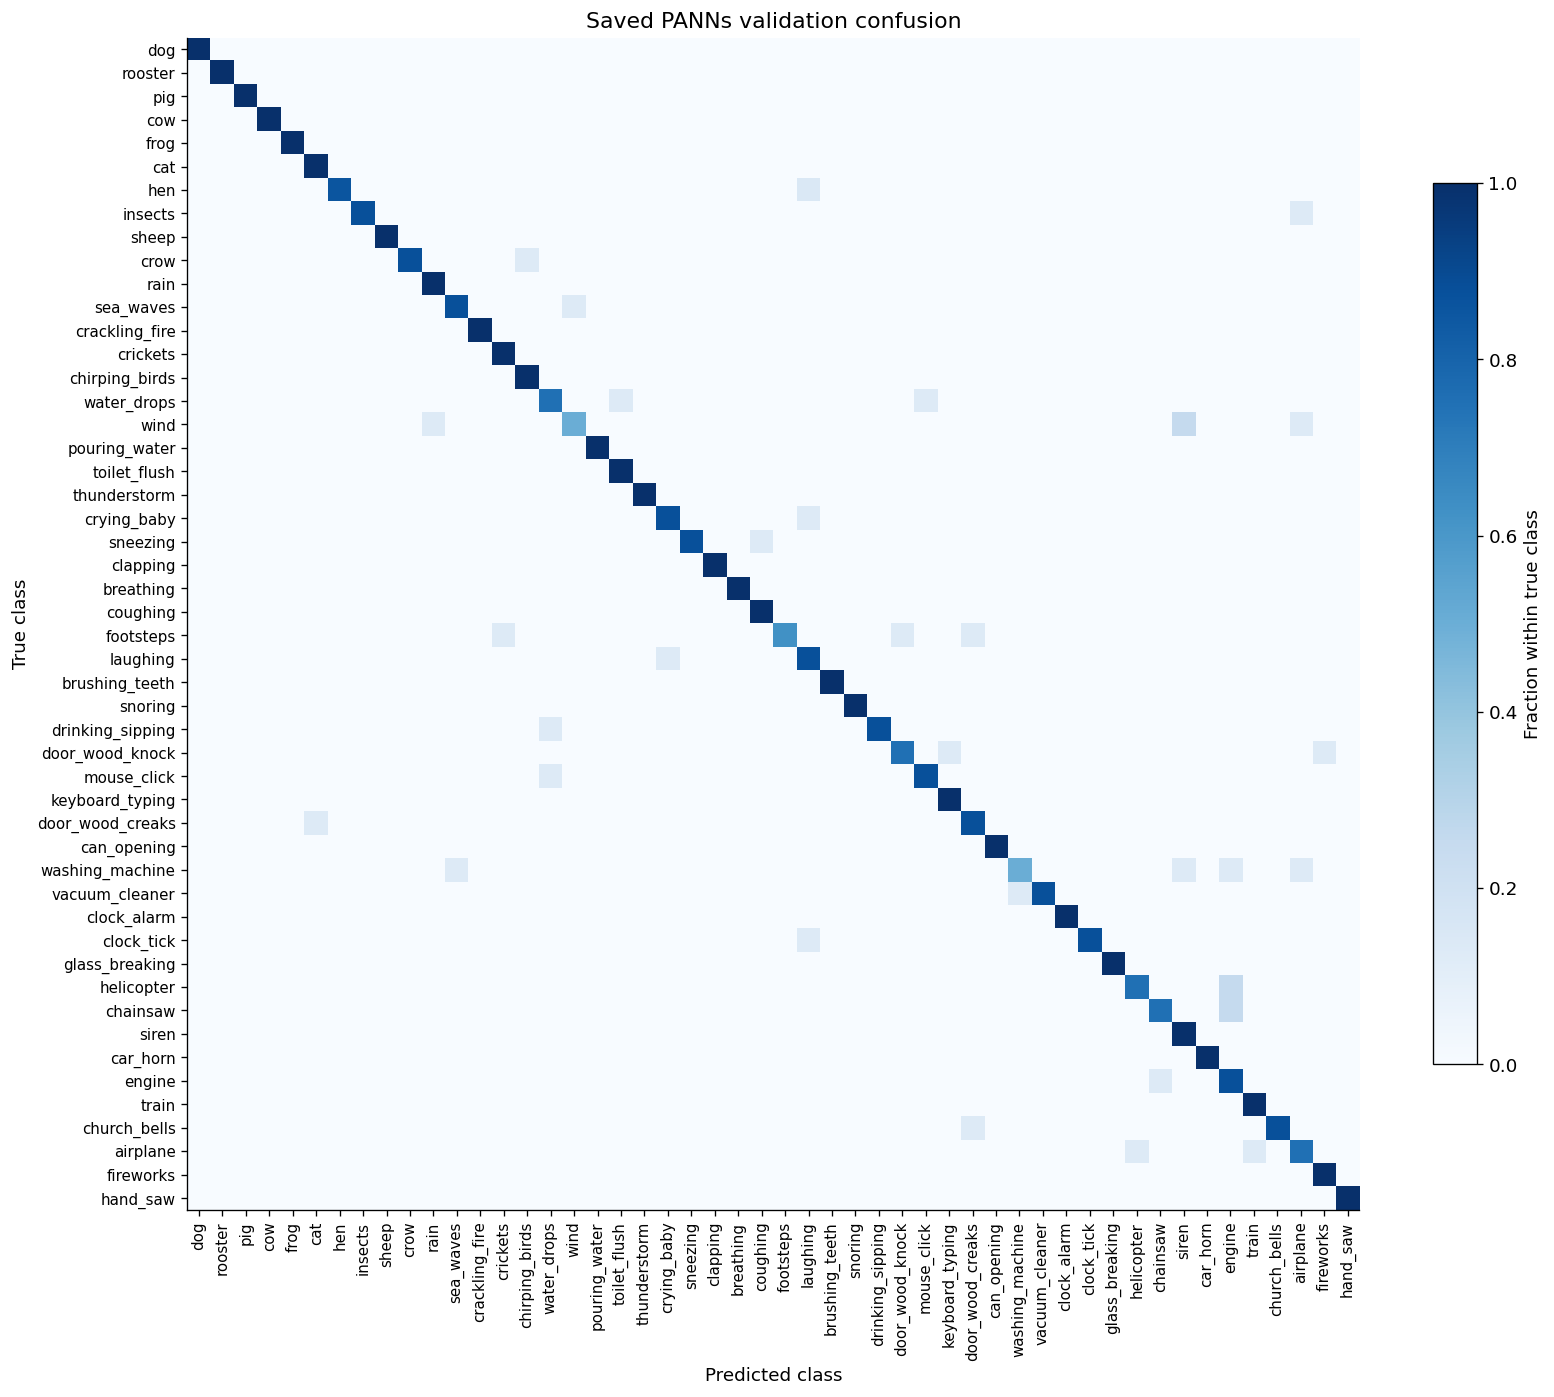

In [11]:
cm = confusion_matrix(targets, predictions, labels=range(50))
fig, ax = plt.subplots(figsize=(14, 12))
image = ax.imshow(cm/cm.sum(axis=1, keepdims=True), vmin=0, vmax=1, cmap="Blues")
labels = [class_names[k] for k in range(50)]
ax.set_xticks(range(50), labels, rotation=90, fontsize=9)
ax.set_yticks(range(50), labels, fontsize=9)
ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_title("New PANNs fit: row-normalized validation confusion" if RUN_TRANSFER else "Saved PANNs validation confusion")
fig.colorbar(image, ax=ax, shrink=0.7, label="Fraction within true class")
fig.tight_layout(); plt.show()

In [12]:
earlier_correctness = [pred == targets[:, None] for pred in reference_predictions.values()]
noise_predictions = np.column_stack([reference_frame[f"C_noise_s{seed}"].to_numpy(int) for seed in (101, 202, 303)])
earlier_correctness.append(noise_predictions == targets[:, None])
persistent = ~np.concatenate(earlier_correctness, axis=1).any(axis=1)
table(pd.DataFrame([{"Persistent failures across four families and three fits": int(persistent.sum()),
                     "Correct in this PANNs fit": int((persistent & new_correct).sum()),
                     "Still incorrect": int((persistent & ~new_correct).sum())}]), precision=0)
print("This is a selected difficult subset; it does not identify the cause of the improvement.")

Persistent failures across four families and three fits,Correct in this PANNs fit,Still incorrect
41,26,15


This is a selected difficult subset; it does not identify the cause of the improvement.


## 4. Architecture and augmentation comparisons

The existing study implemented BiGRU, temporal attention, channel attention and their combination. Channel attention adds about 0.50 pp over BiGRU, with a conditional interval spanning zero. That evidence does not justify claiming a stable attention gain.

Gaussian-noise augmentation uses training probability 0.5 with SNR uniformly sampled from 10–30 dB. Spectrogram masking covers at most eight frequency bands and 24 time frames, without time warping. Waveform Mixup uses Beta(0.4, 0.4) mixing and weighted cross-entropy. These are adaptations, not exact reproductions of every cited paper.

In [13]:
comparison = load_csv("reports/checkpoint_20261105/model_comparison.csv")
comparison.loc[comparison["group"] == "transfer", "accuracy_percent"] = 100*panns_accuracy
comparison.loc[comparison["group"] == "transfer", "macro_f1_percent"] = 100*panns_f1
comparison_display = comparison[["model", "accuracy_percent", "accuracy_sample_sd_pp", "macro_f1_percent",
                                  "macro_f1_sample_sd_pp", "task_trainable_parameters", "fits"]].copy()
for column in ["accuracy_sample_sd_pp", "macro_f1_sample_sd_pp"]:
    comparison_display[column] = pd.to_numeric(comparison_display[column], errors="coerce")
comparison_display.columns = ["Model", "Accuracy (%)", "SD (pp)", "Macro-F1 (%)", "F1 SD (pp)", "Parameters", "Fits"]
table(comparison_display, precision=2)
classic = load_csv("reports/evidence/matrix_20261028/analysis/runs.csv")
table(classic.loc[classic["kind"] == "baseline", ["id", "accuracy", "macro_f1", "parameters"]])

Model,Accuracy (%),SD (pp),Macro-F1 (%),F1 SD (pp),Parameters,Fits
CNN baseline (frequency-preserving),72.61,0.25,71.39,0.58,49058,3
CNN + BiGRU,73.87,1.26,72.97,1.36,251810,3
CRNN + channel attention,74.37,1.15,73.48,1.00,252906,3
CRNN + temporal attention,72.28,2.41,71.52,2.41,251939,3
CRNN + temporal/channel attention,72.86,1.26,71.69,1.35,253035,3
CNN + mixup,71.61,0.66,70.65,0.44,49058,3
CNN + noise,73.12,0.87,71.99,1.23,49058,3
CNN + specaugment,71.86,1.15,70.75,1.38,49058,3
CNN + pooled MLP,72.28,0.63,71.17,0.57,252036,3
CNN + tokenwise MLP,69.68,3.90,67.86,4.97,252036,3


id,accuracy,macro_f1,parameters
A_logistic,0.422,0.389,6450.000
A_cepstral_svm,0.402,0.375,2050.000


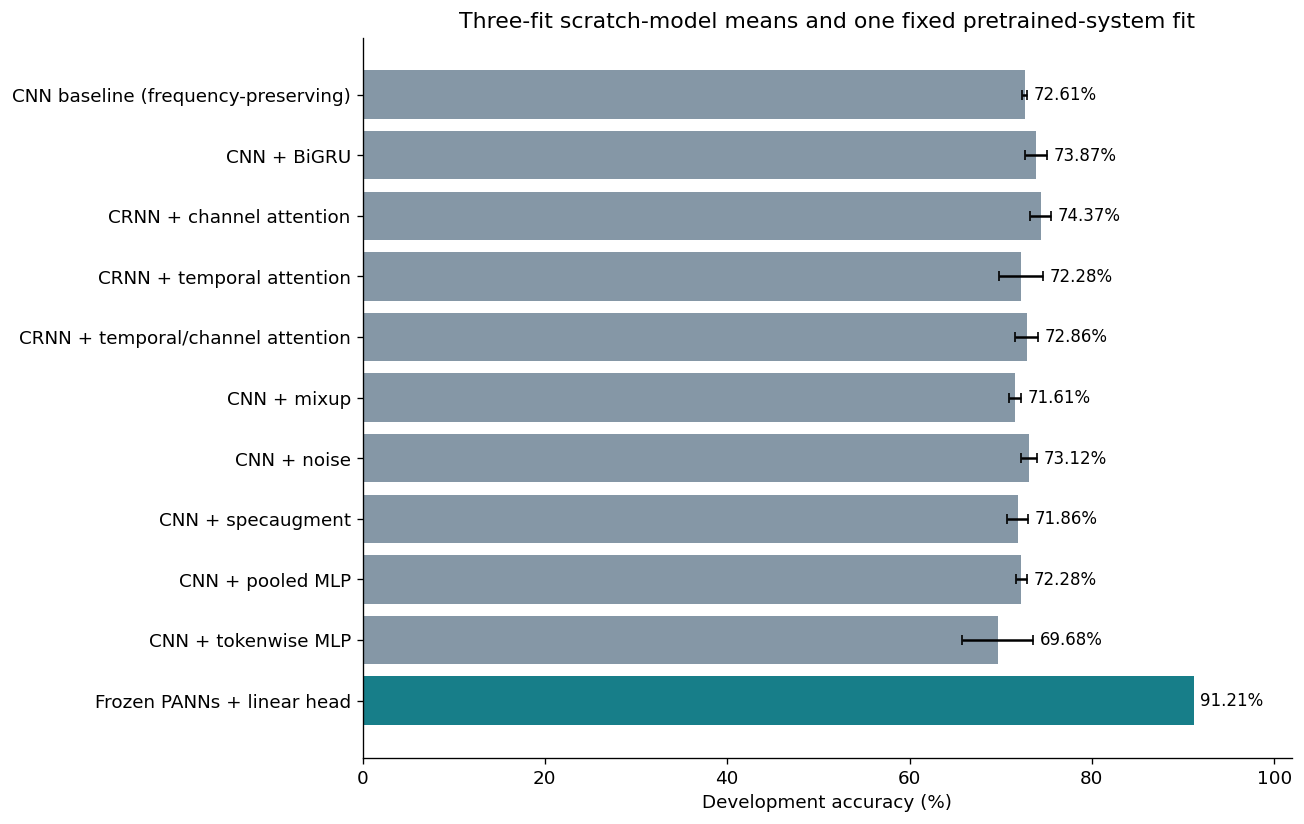

In [14]:
fig, ax = plt.subplots(figsize=(11, 7))
values = comparison["accuracy_percent"].to_numpy()
errors = pd.to_numeric(comparison["accuracy_sample_sd_pp"], errors="coerce").fillna(0).to_numpy()
ax.barh(comparison["model"], values, color=["#177e89" if x == "transfer" else "#8597a6" for x in comparison["group"]])
ax.errorbar(values[:-1], np.arange(len(values)-1), xerr=errors[:-1], fmt="none", color="black", capsize=3)
for i, (value, error) in enumerate(zip(values, errors)):
    ax.text(value+error+0.7, i, f"{value:.2f}%", va="center", fontsize=10)
ax.set_xlim(0, 102); ax.invert_yaxis(); ax.set_xlabel("Development accuracy (%)")
ax.set_title("Three-fit scratch-model means and one fixed pretrained-system fit")
fig.tight_layout(); plt.show()

### Earlier MLP capacity controls

The pooled MLP and tokenwise MLP were each trained for 60 epochs with seeds 101/202/303. They share the CNN encoder and have 252,036 total parameters. These are completed earlier controls, not new PANNs-head runs. CNN/BiGRU references overlap the later matrix and are not independent replications.

model,label,parameters,fits,accuracy_percent,accuracy_sd_pp,macro_f1_percent,macro_f1_sd_pp
cnn_freq,CNN + linear head,49058,3,72.613,0.251,71.393,0.581
crnn_freq,CNN + BiGRU,251810,3,73.869,1.256,72.970,1.358
cnn_freq_matched,CNN + pooled MLP,252036,3,72.278,0.632,71.165,0.565
cnn_freq_token,CNN + tokenwise MLP,252036,3,69.682,3.903,67.863,4.972


model,label,seed,accuracy,macro_f1,n,parameters,best_epoch,epochs,stage
cnn_freq,CNN + linear head,101,0.7261,0.7194,398,49058,47,60,Earlier fixed-recipe capacity-control study
cnn_freq,CNN + linear head,202,0.7236,0.7079,398,49058,49,60,Earlier fixed-recipe capacity-control study
cnn_freq,CNN + linear head,303,0.7286,0.7145,398,49058,46,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,101,0.7513,0.7421,398,251810,58,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,202,0.7387,0.7318,398,251810,58,60,Earlier fixed-recipe capacity-control study
crnn_freq,CNN + BiGRU,303,0.7261,0.7152,398,251810,30,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,101,0.7161,0.7059,398,252036,32,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,202,0.7286,0.7172,398,252036,52,60,Earlier fixed-recipe capacity-control study
cnn_freq_matched,CNN + pooled MLP,303,0.7236,0.7119,398,252036,48,60,Earlier fixed-recipe capacity-control study
cnn_freq_token,CNN + tokenwise MLP,101,0.6533,0.6233,398,252036,13,60,Earlier fixed-recipe capacity-control study


model,reference,delta_accuracy_pp,source_bootstrap_low_pp,source_bootstrap_high_pp,n_clips,n_sources,bootstrap_resamples,bootstrap_seed,minimum_resample_clips,maximum_resample_clips,uncertainty_scope
cnn_freq_matched,cnn_freq,-0.335,-2.618,1.980,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_matched,crnn_freq,-1.591,-4.085,0.769,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_token,cnn_freq,-2.931,-5.584,-0.246,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty
cnn_freq_token,crnn_freq,-4.188,-6.683,-1.630,398,295,4000,20261105,360,450,source sampling conditional on the fixed models and corruption realization; not training-seed or noise-draw population uncertainty


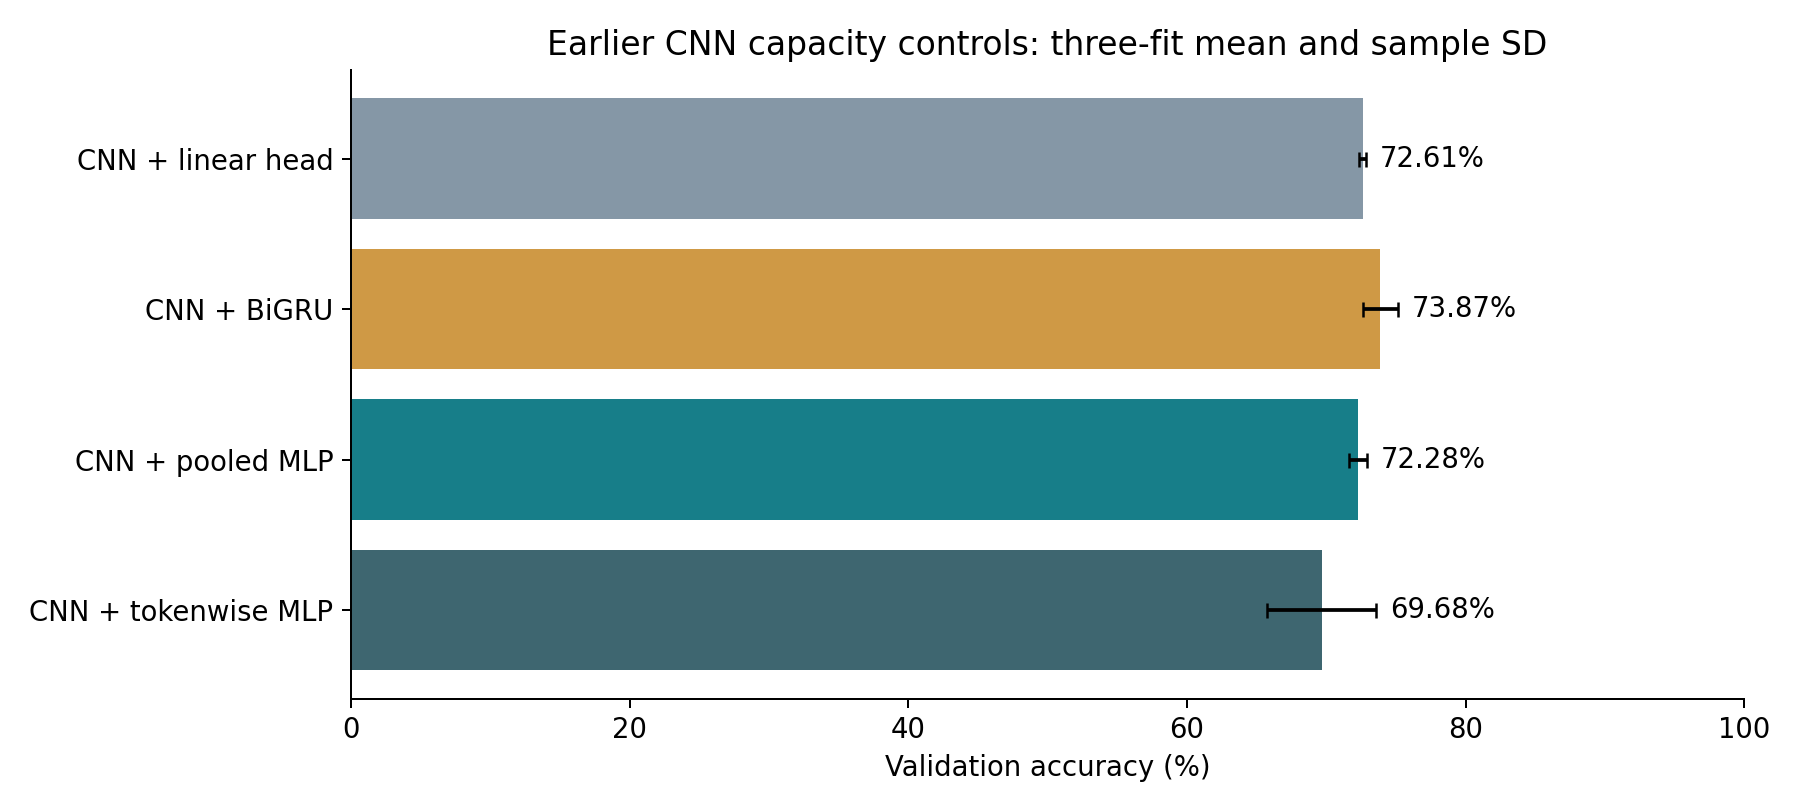

In [15]:
mlp_root=ROOT/"reports/mlp_controls_20261105"
table(pd.read_csv(mlp_root/"comparison.csv"),3)
table(pd.read_csv(mlp_root/"runs.csv"),4)
table(pd.read_csv(mlp_root/"paired_differences.csv"),3)
display(Image(filename=str(ROOT/"reports/transfer_followup_20261105/restored_mlp_controls.png"),width=1050))

## 5. Gaussian-noise robustness

The completed panel contains three model families × three fixed seeds × six conditions = 54 evaluations. All use the same 398 validation recordings and fixed per-clip perturbations. Synthetic Gaussian-noise findings do not establish field robustness. This earlier panel excludes PANNs. The completed new matched PANNs comparison is reported below and uses separate seed-sequence-v2 noise draws.

In [16]:
robustness = load_csv("reports/checkpoint_20261105/robustness_comparison.csv")
table(robustness)
robust_runs = load_csv("reports/followup_20261104/robustness_runs.csv")
table(robust_runs[["variant", "seed", "condition", "correct", "accuracy"]])

condition,cnn_accuracy_percent,cnn_sample_sd_pp,crnn_accuracy_percent,crnn_sample_sd_pp,noise_cnn_accuracy_percent,noise_cnn_sample_sd_pp
clean,72.613,0.251,73.869,1.256,73.116,0.870
snr_20,47.739,1.508,50.838,3.466,70.268,0.290
snr_10,23.367,1.005,23.869,0.754,61.307,2.190
snr_0,7.203,0.384,5.863,0.384,25.377,3.208
gain_-6,69.598,0.665,69.430,0.384,68.593,0.000
gain_6,71.441,0.725,71.524,1.596,70.938,1.046


variant,seed,condition,correct,accuracy
cnn,101,clean,289,0.726
cnn,101,snr_20,190,0.477
cnn,101,snr_10,93,0.234
cnn,101,snr_0,27,0.068
cnn,101,gain_-6,274,0.688
cnn,101,gain_6,286,0.719
cnn,202,clean,288,0.724
cnn,202,snr_20,196,0.492
cnn,202,snr_10,97,0.244
cnn,202,snr_0,30,0.075


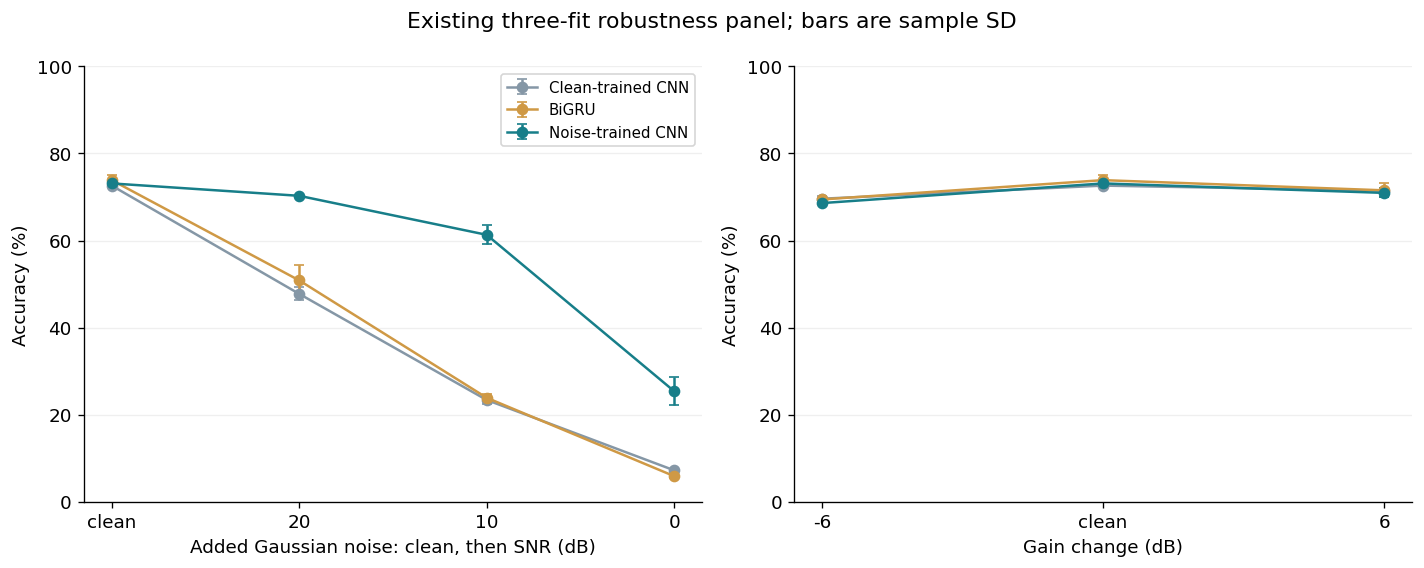

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for family, label, color in [("cnn", "Clean-trained CNN", "#8597a6"),
                              ("crnn", "BiGRU", "#cf9945"),
                              ("noise_cnn", "Noise-trained CNN", "#177e89")]:
    for ax, conditions in zip(axes, [["clean", "snr_20", "snr_10", "snr_0"], ["gain_-6", "clean", "gain_6"]]):
        part = robustness.set_index("condition").loc[conditions]
        ax.errorbar(range(len(conditions)), part[f"{family}_accuracy_percent"],
                    yerr=part[f"{family}_sample_sd_pp"], marker="o", capsize=3, label=label, color=color)
        ax.set_xticks(range(len(conditions)), [x.replace("snr_", "").replace("gain_", "") for x in conditions])
        ax.set_ylim(0, 100); ax.set_ylabel("Accuracy (%)"); ax.grid(axis="y", alpha=0.2)
axes[0].set_xlabel("Added Gaussian noise: clean, then SNR (dB)")
axes[1].set_xlabel("Gain change (dB)")
axes[0].legend(fontsize=9)
fig.suptitle("Existing three-fit robustness panel; bars are sample SD")
fig.tight_layout(); plt.show()

In [18]:
paired_robust = load_csv("reports/followup_20261104/paired_robustness.csv")
loss_reduction = load_csv("reports/followup_20261104/robustness_loss_reduction.csv")
# Summary rows labelled mean_fixed_seeds retain the paired source-cluster calculation.
table(paired_robust[["comparison", "condition", "seed", "delta_accuracy_pp",
                     "source_bootstrap_low_pp", "source_bootstrap_high_pp"]])
table(loss_reduction)

comparison,condition,seed,delta_accuracy_pp,source_bootstrap_low_pp,source_bootstrap_high_pp
noise_cnn-cnn,clean,101,0.000,-3.291,3.133
noise_cnn-cnn,clean,202,1.759,-1.772,5.366
noise_cnn-cnn,clean,303,-0.251,-3.828,3.234
noise_cnn-cnn,clean,fixed_three_seed_mean,0.503,-2.020,2.884
noise_cnn-cnn,snr_20,101,22.864,17.150,28.536
noise_cnn-cnn,snr_20,202,20.854,14.988,26.583
noise_cnn-cnn,snr_20,303,23.869,17.979,29.880
noise_cnn-cnn,snr_20,fixed_three_seed_mean,22.529,17.354,27.636
noise_cnn-cnn,snr_10,101,39.447,32.978,45.918
noise_cnn-cnn,snr_10,202,34.422,28.085,40.887


comparison,condition,seed,reduced_accuracy_loss_pp,source_bootstrap_low_pp,source_bootstrap_high_pp,n_clips,n_sources,bootstrap_resamples,bootstrap_seed
noise_cnn-cnn,snr_20,101,22.864,16.708,29.156,398,295,4000,20261104
noise_cnn-cnn,snr_20,202,19.095,13.158,25.063,398,295,4000,20261104
noise_cnn-cnn,snr_20,303,24.121,18.317,30.244,398,295,4000,20261104
noise_cnn-cnn,snr_20,fixed_three_seed_mean,22.027,16.926,27.302,398,295,4000,20261104
noise_cnn-cnn,snr_10,101,39.447,32.299,46.374,398,295,4000,20261104
noise_cnn-cnn,snr_10,202,32.663,25.907,39.947,398,295,4000,20261104
noise_cnn-cnn,snr_10,303,40.201,33.245,47.216,398,295,4000,20261104
noise_cnn-cnn,snr_10,fixed_three_seed_mean,37.437,31.308,43.740,398,295,4000,20261104
noise_cnn-cnn,snr_0,101,19.347,14.285,24.642,398,295,4000,20261104
noise_cnn-cnn,snr_0,202,12.563,7.068,18.274,398,295,4000,20261104


At 10 dB, noise-trained CNN accuracy is 61.31% versus 23.37% for clean-trained CNN: **+37.94 pp**, conditional 95% source interval **[+32.08, +43.88] pp**. After accounting for the small clean difference, the reduction in noise-induced loss is **37.44 pp [31.31, 43.74]**. Gain perturbations do not show a similar advantage. This supports a specific improvement in sensitivity to the tested additive noise.

## 6. Temporal structure and feature diagnostics

The temporal intervention permutes the encoder's 39 tokens, rather than waveform samples. Reversal reduces BiGRU mean accuracy from 73.87% to 68.84%, while the CNN's temporal averaging leaves predictions unchanged. The small shuffle effects prevent a simple claim that greater disorder necessarily causes greater degradation.

In [19]:
temporal = load_csv("reports/temporal_20261105/metrics.csv")
table(temporal[["model", "seed", "condition", "accuracy", "macro_f1", "changedpredcount"]])
temporal_summary = json.loads((ROOT/"reports/temporal_20261105/summary.json").read_text())
effects = pd.DataFrame([{"Model / intervention": name, "Change (pp)": values["delta_accuracy_pp"],
                         "Lower (pp)": values["source_bootstrap_low_pp"],
                         "Upper (pp)": values["source_bootstrap_high_pp"]}
                        for name, values in temporal_summary["effects"].items()])
table(effects)

model,seed,condition,accuracy,macro_f1,changedpredcount
cnn_freq,101,identity,0.726,0.719,0
cnn_freq,101,reverse,0.726,0.719,0
cnn_freq,101,roll19,0.726,0.719,0
cnn_freq,101,shuffle17,0.726,0.719,0
cnn_freq,101,shuffle29,0.726,0.719,0
cnn_freq,202,identity,0.724,0.708,0
cnn_freq,202,reverse,0.724,0.708,0
cnn_freq,202,roll19,0.724,0.708,0
cnn_freq,202,shuffle17,0.724,0.708,0
cnn_freq,202,shuffle29,0.724,0.708,0


Model / intervention,Change (pp),Lower (pp),Upper (pp)
cnn_freq/reverse,0.000,0.000,0.000
cnn_freq/roll19,0.000,0.000,0.000
cnn_freq/shuffle17,0.000,0.000,0.000
cnn_freq/shuffle29,0.000,0.000,0.000
crnn_freq/reverse,-5.025,-7.543,-2.602
crnn_freq/roll19,-1.424,-2.939,0.085
crnn_freq/shuffle17,-1.089,-2.640,0.419
crnn_freq/shuffle29,-0.084,-1.470,1.320


In [20]:
groups = load_csv("reports/evidence/matrix_20261028/analysis/groups.csv")
feature_groups = groups.loc[groups["group"] == "D_features"].copy()
if feature_groups.empty:
    feature_groups = groups.loc[groups["case"].notna()].copy()
table(feature_groups[["case", "accuracy_mean", "accuracy_sample_sd", "macro_f1_mean", "macro_f1_sample_sd"]])
convergence = load_csv("reports/followup_20261104/convergence/runs.csv")
table(convergence)
print("Feature fits selected in epochs 51–60:", int(convergence["latebest"].sum()), "/", len(convergence))
print("Late checkpoint selection alone is not proof that training had not converged.")

case,accuracy_mean,accuracy_sample_sd,macro_f1_mean,macro_f1_sample_sd
sr16_fmax8_loglinear64,0.516,0.008,0.486,0.012
sr16_fmax8_logmel32,0.556,0.007,0.530,0.005
sr16_fmax8_logmel64,0.516,0.020,0.485,0.022
sr16_fmax8_mfcc40,0.492,0.017,0.471,0.017
sr32_fmax16_loglinear64,0.490,0.013,0.461,0.017
sr32_fmax16_logmel32,0.571,0.010,0.546,0.015
sr32_fmax16_logmel64,0.511,0.004,0.483,0.005
sr32_fmax16_mfcc40,0.496,0.031,0.473,0.029
sr32_fmax8_loglinear64,0.508,0.007,0.476,0.016
sr32_fmax8_logmel32,0.557,0.010,0.530,0.013


case,config,feature,seed,best_epoch,selected_accuracy,selected_macro_f1,selected_validation_loss,latebest,loss_delta_e60_minus_e50,accuracy_delta_pp_e60_minus_e50
sr16_fmax8_logmel64,sr16_fmax8,logmel64,101,59,0.492,0.460,1.823,1,-0.015,0.000
sr16_fmax8_logmel64,sr16_fmax8,logmel64,202,49,0.525,0.491,1.859,0,0.006,0.503
sr16_fmax8_logmel64,sr16_fmax8,logmel64,303,57,0.530,0.503,1.809,1,-0.003,-0.754
sr16_fmax8_logmel32,sr16_fmax8,logmel32,101,58,0.548,0.524,1.639,1,-0.015,0.754
sr16_fmax8_logmel32,sr16_fmax8,logmel32,202,58,0.560,0.533,1.671,1,-0.002,-0.754
sr16_fmax8_logmel32,sr16_fmax8,logmel32,303,57,0.560,0.532,1.624,1,-0.010,-1.005
sr16_fmax8_mfcc40,sr16_fmax8,mfcc40,101,58,0.482,0.457,2.019,1,0.006,-0.754
sr16_fmax8_mfcc40,sr16_fmax8,mfcc40,202,56,0.513,0.490,1.993,1,-0.003,-0.251
sr16_fmax8_mfcc40,sr16_fmax8,mfcc40,303,59,0.482,0.465,1.994,1,-0.006,2.261
sr16_fmax8_loglinear64,sr16_fmax8,loglinear64,101,58,0.510,0.476,1.804,1,-0.022,1.759


Feature fits selected in epochs 51–60: 30 / 36
Late checkpoint selection alone is not proof that training had not converged.


The feature experiment uses a separate 26, 658-parameter pooled CNN and 12 configurations × three seeds. Its lower scores must not be substituted for the main frequency-preserving CNN baseline. Log-Mel 32 improves over Log-Mel 64 in the tested feature track; that result need not transfer to every model.

## 7. Complete experiment ledger and historical comparison

The original matrix registered 65 tasks: 60 neural fits, two classical fits and three stress evaluations. The designated test and fold-rotation results below belong to an earlier research stage. They are not new confirmation and are not subtracted from current validation scores.

In [21]:
all_runs = load_csv("reports/evidence/matrix_20261028/analysis/runs.csv")
table(all_runs[["id", "kind", "model", "seed", "accuracy", "macro_f1", "best_epoch", "parameters", "seconds"]])
print("Registered tasks:", len(all_runs))
print("Neural fits:", int(all_runs["kind"].isin(["supervised", "feature_ablation"]).sum()))
print("Classical fits:", int((all_runs["kind"] == "baseline").sum()))

id,kind,model,seed,accuracy,macro_f1,best_epoch,parameters,seconds
A_logistic,baseline,logistic,—,0.422,0.389,—,6450.000,18.714
A_cepstral_svm,baseline,cepstral_svm,—,0.402,0.375,—,2050.000,—
B_cnn_freq_s101,supervised,cnn_freq,101.000,0.726,0.719,47.000,49058.000,72.395
B_cnn_freq_s202,supervised,cnn_freq,202.000,0.724,0.708,49.000,49058.000,75.864
B_cnn_freq_s303,supervised,cnn_freq,303.000,0.729,0.715,46.000,49058.000,75.914
B_crnn_freq_s101,supervised,crnn_freq,101.000,0.751,0.742,58.000,251810.000,81.077
B_crnn_freq_s202,supervised,crnn_freq,202.000,0.739,0.732,58.000,251810.000,80.782
B_crnn_freq_s303,supervised,crnn_freq,303.000,0.726,0.715,30.000,251810.000,80.793
B_crnn_freq_ta_s101,supervised,crnn_freq_ta,101.000,0.749,0.740,46.000,251939.000,81.318
B_crnn_freq_ta_s202,supervised,crnn_freq_ta,202.000,0.701,0.692,58.000,251939.000,81.692


Registered tasks: 65
Neural fits: 60
Classical fits: 2


In [22]:
historical = json.loads((ROOT/"reports/evidence/baseline_20261028/comparison.json").read_text())
historical_rows = []
for role, label in [("left", "Historical CRNN"), ("right", "Historical CNN")]:
    result = historical[role]
    historical_rows.append({"System": label, "Clips": historical["n"],
                            "Accuracy (%)": 100*result["accuracy"], "Macro-F1 (%)": 100*result["macro_f1"]})
table(pd.DataFrame(historical_rows))
print("Historical scope: designated fold-5 evaluation; different recordings from the main validation table.")

System,Clips,Accuracy (%),Macro-F1 (%)
Historical CRNN,400,62.000,59.505
Historical CNN,400,61.500,59.918


Historical scope: designated fold-5 evaluation; different recordings from the main validation table.


In [23]:
classes = load_csv("reports/followup_20261104/class_accuracy.csv")
class_pivot = classes.pivot(index="category", columns="variant", values="mean_accuracy").reset_index()
table(class_pivot)
confusions = load_csv("reports/followup_20261104/confusions.csv")
print("Saved confusion-event rows:", len(confusions))
display(confusions.head(20))
print("Full confusion-event details remain in reports/followup_20261104/confusions.csv.")

category,channel_attention,cnn,crnn,mixup,noise_cnn,specaugment,temporal_attention,temporal_channel_attention
airplane,0.625,0.875,0.625,0.875,0.875,0.875,0.458,0.542
breathing,0.833,0.750,0.667,0.750,0.750,0.708,0.792,0.750
brushing_teeth,0.792,0.708,0.792,0.750,0.708,0.708,0.750,0.750
can_opening,1.000,1.000,0.958,0.833,0.917,1.000,0.833,0.875
car_horn,0.708,0.792,0.708,0.750,0.625,0.750,0.542,0.542
cat,0.625,0.583,0.583,0.542,0.667,0.417,0.667,0.667
chainsaw,0.875,0.833,0.875,0.833,0.833,0.875,0.792,0.750
chirping_birds,0.958,0.875,0.917,0.875,0.917,0.917,0.833,0.917
church_bells,0.792,0.833,0.833,0.833,0.875,0.750,0.875,0.958
clapping,0.667,0.417,0.917,0.917,0.667,0.208,0.792,0.917


Saved confusion-event rows: 1174


,variant,target,target_category,prediction,predicted_category,seed_clip_error_events,unique_clips,unique_sources
0,cnn,8,sheep,47,airplane,12,4,1
1,cnn,29,drinking_sipping,17,pouring_water,9,3,1
2,cnn,22,clapping,11,sea_waves,7,3,2
3,cnn,26,laughing,20,crying_baby,7,3,3
4,cnn,7,insects,19,thunderstorm,6,2,1
5,cnn,13,crickets,14,chirping_birds,6,2,2
6,cnn,16,wind,3,cow,6,2,2
7,cnn,16,wind,19,thunderstorm,6,2,1
8,cnn,27,brushing_teeth,29,drinking_sipping,6,2,1
9,cnn,39,glass_breaking,34,can_opening,6,2,2


Full confusion-event details remain in reports/followup_20261104/confusions.csv.


## 8. Literature and implementation decisions

The 26-entry map distinguishes selected full-text reading, abstract/repository screening and access limitations. CNN/CRNN, augmentation and transfer learning are implemented comparisons. AST, BEATs, CLAP and masked/self-supervised audio models supply context and possible future approaches; their published leaderboard scores are not experimental results from this notebook.

SpecAugment originally targeted ASR, and Salamon/Bello primarily evaluated UrbanSound8K. Their results motivate experiments rather than guaranteeing an ESC-50 gain. Waveform Mixup here is not Tokozume's complete perceptual between-class sound-mixing recipe.

In [24]:
literature = load_csv("reports/checkpoint_20261105/literature_matrix.csv")
display(literature.style.hide(axis="index").set_properties(**{"white-space": "normal", "text-align": "left"}))

id,publication,primary_url,theme,reading_depth,checkpoint_decision
R01,"Piczak, 2015: ESC dataset",https://doi.org/10.1145/2733373.2806390,Dataset/source-fold protocol,Primary record and official dataset documentation,Direct: establishes dataset provenance; use our source-strict role counts rather than importing historical benchmark scores.
R02,"Piczak, 2015: Environmental Sound Classification with CNNs",https://doi.org/10.1109/MLSP.2015.7324337,Early spectrogram CNN,Selected author full-text methods; earlier audit,Conceptual baseline only: our small full-clip frequency-preserving CNN is an independent implementation.
R03,"Salamon and Bello, 2017 (preprint 2016)",https://arxiv.org/abs/1608.04363,CNN and waveform augmentation,"Primary full text, selected methods/dataset sections","Direct augmentation motivation; original main experiments use UrbanSound8K, not our ESC-50 split."
R04,"Zhang et al., 2019: Learning Attentive Representations",https://doi.org/10.1109/ACCESS.2019.2939495,Temporal/channel attention,Publisher abstract; full tables not verified,Direct architectural motivation; lightweight adaptations and our negative results do not replicate or refute every published configuration.
R05,"Boddapati et al., 2017",https://doi.org/10.1016/j.procs.2017.08.250,Image recognition networks for environmental audio,Publisher abstract screening,Representation/transfer context; AlexNet and GoogLeNet are not our CNN architecture.
R06,"Tokozume et al., ICLR 2018 (preprint 2017)",https://arxiv.org/abs/1711.10282,Between-class sound learning,Primary abstract,Related to mixed sound/label training; not identical to the implemented generic waveform Mixup. The image paper has a different identifier.
R07,"Kong et al., 2020 (preprint 2019): PANNs",https://arxiv.org/abs/1912.10211,Supervised AudioSet transfer,"Primary full text, Section V and VI-D; official model code",Direct implemented alternative: frozen Cnn14_16k embeddings plus one linear head. Original transfer recipe and our 16 kHz logistic probe differ.
R08,"Niizumi et al., 2021: BYOL-A",https://arxiv.org/abs/2103.06695,Self-supervised augmented audio views,Primary abstract screening,"Background only; our PANNs checkpoint is supervised AudioSet pretraining, not BYOL-A."
R09,"Gong et al., Interspeech 2021: AST",https://arxiv.org/abs/2104.01778,Audio spectrogram transformer,Primary abstract and official ESC-50 recipe,Deferred alternative; pretrained/five-fold results cannot rank directly against this development split.
R10,"Koutini et al., Interspeech 2022: PaSST",https://arxiv.org/abs/2110.05069,Patchout for efficient transformers,Proceedings abstract and official repository screening,Efficiency context only; no PaSST training or timing result was measured here.


## 9. Original 22-figure atlas

The following 22 original figures retain their original captions and experimental scope. The four new follow-up figures appear in the added sections. They include historical baseline figures, the original seed101 noise panel, the later completed three-seed panel and the earlier PANNs fit. New PANNs metrics and plots are calculated above. These stored figures are not presented as new model runs.

### Figure 1. Three-seed development validation; SD is not a confidence interval.

Scope: Original development matrix.

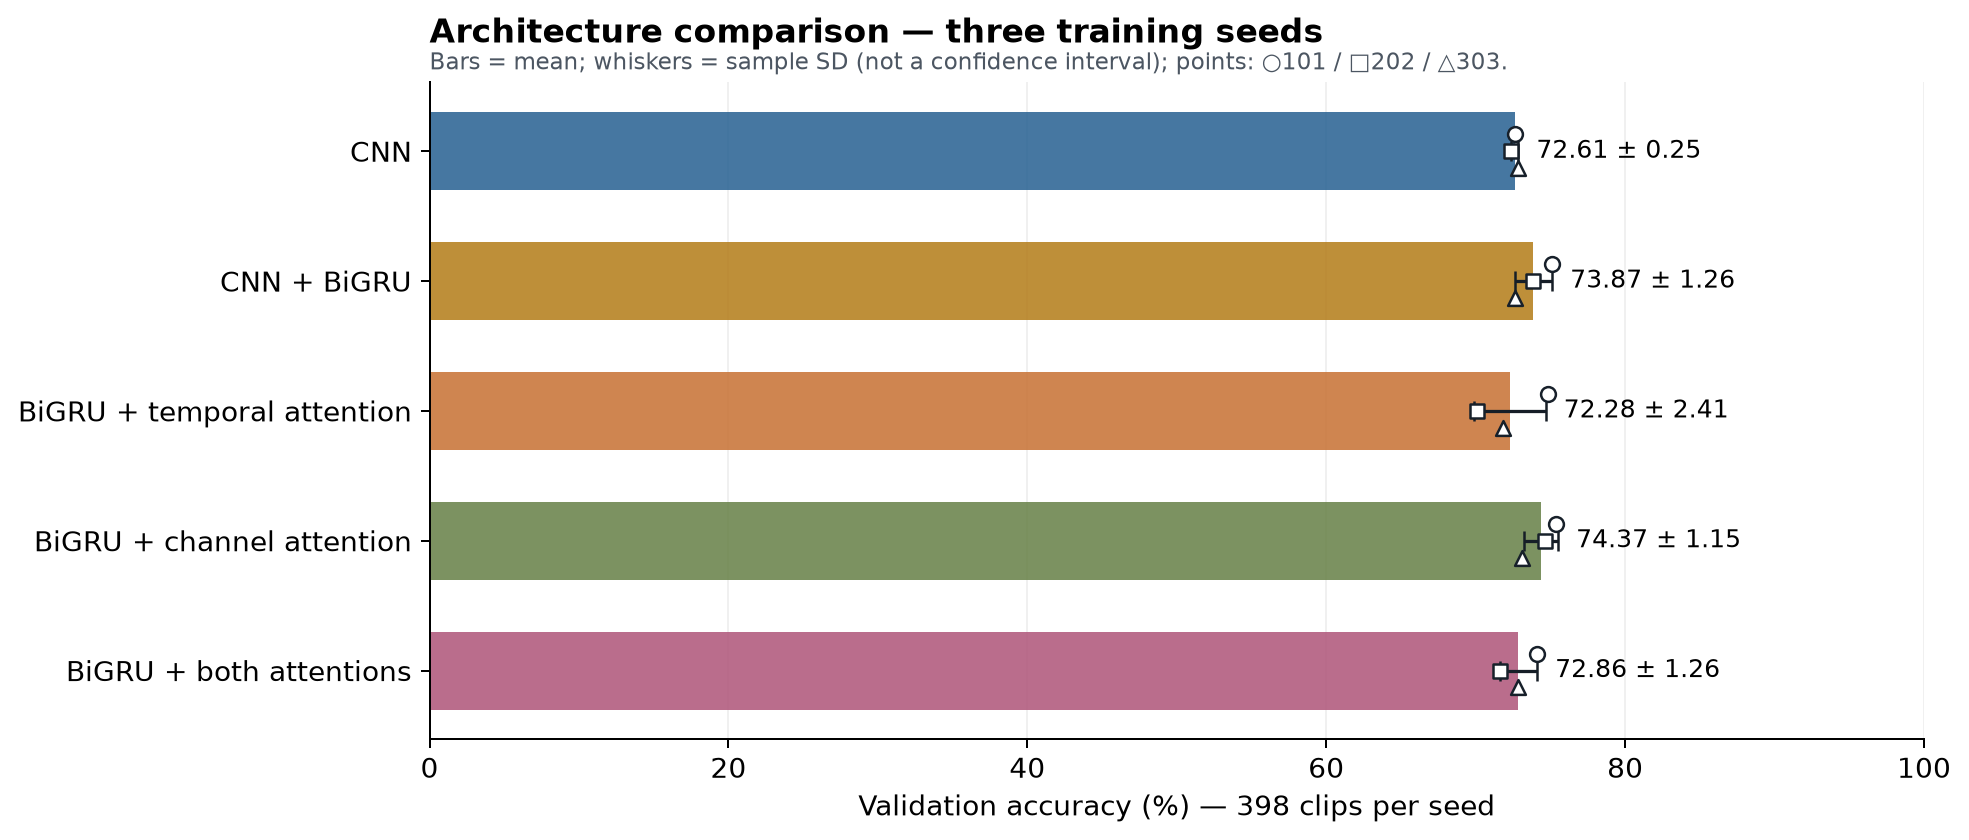

In [25]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/architecture.png'), width=1050))

### Figure 2. Augmentation affects training only; validation recordings stay clean.

Scope: Original development matrix.

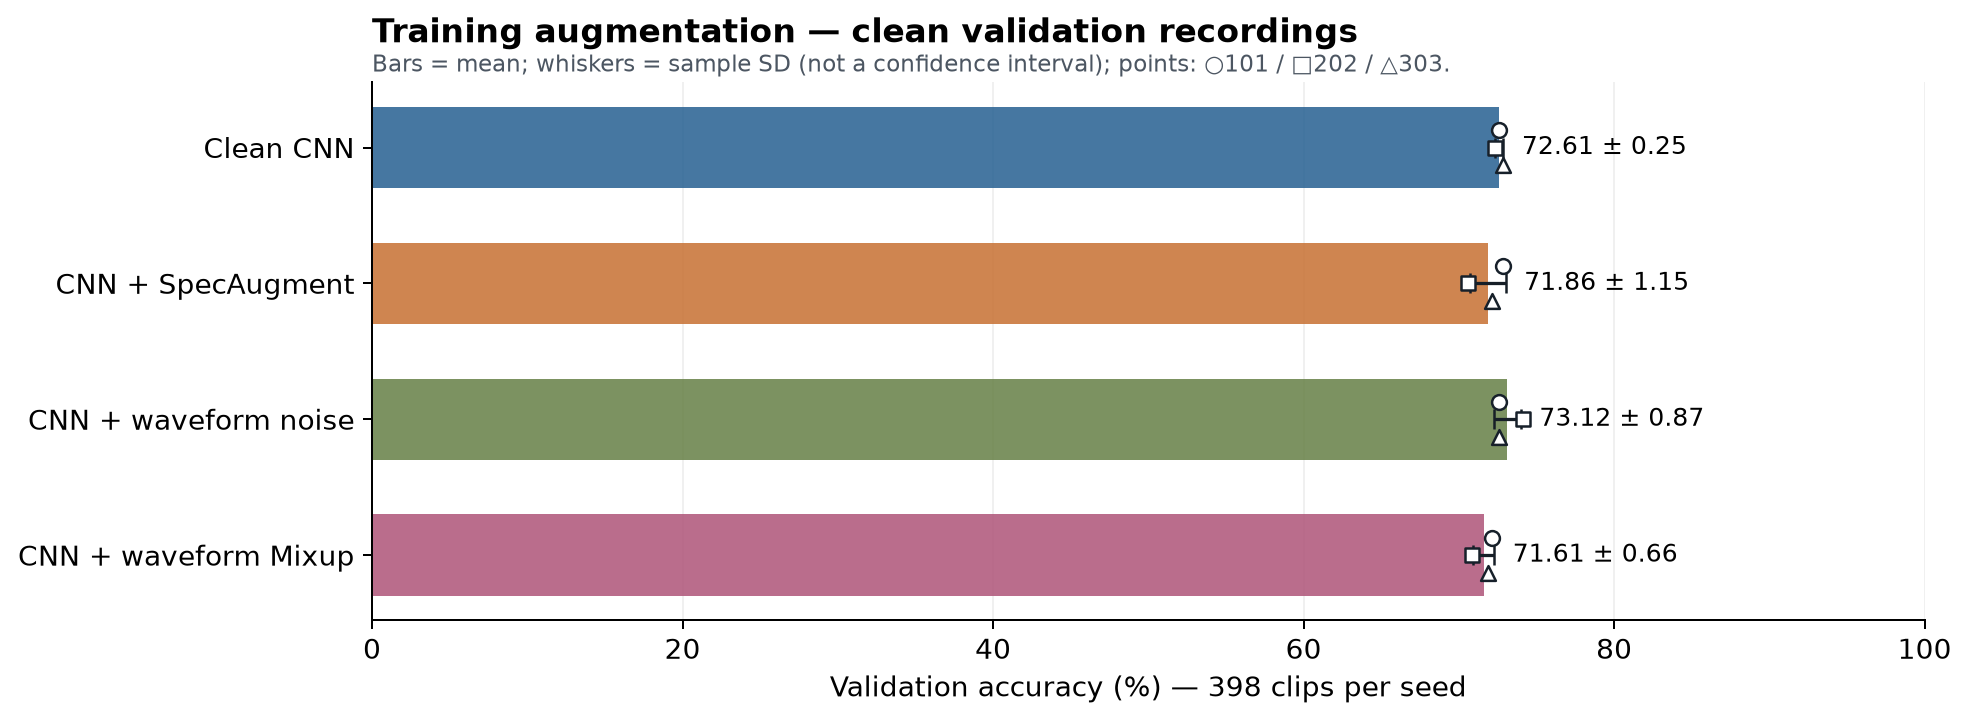

In [26]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/augmentation.png'), width=1050))

### Figure 3. Within-seed deltas; these are not significance tests.

Scope: Original development matrix.

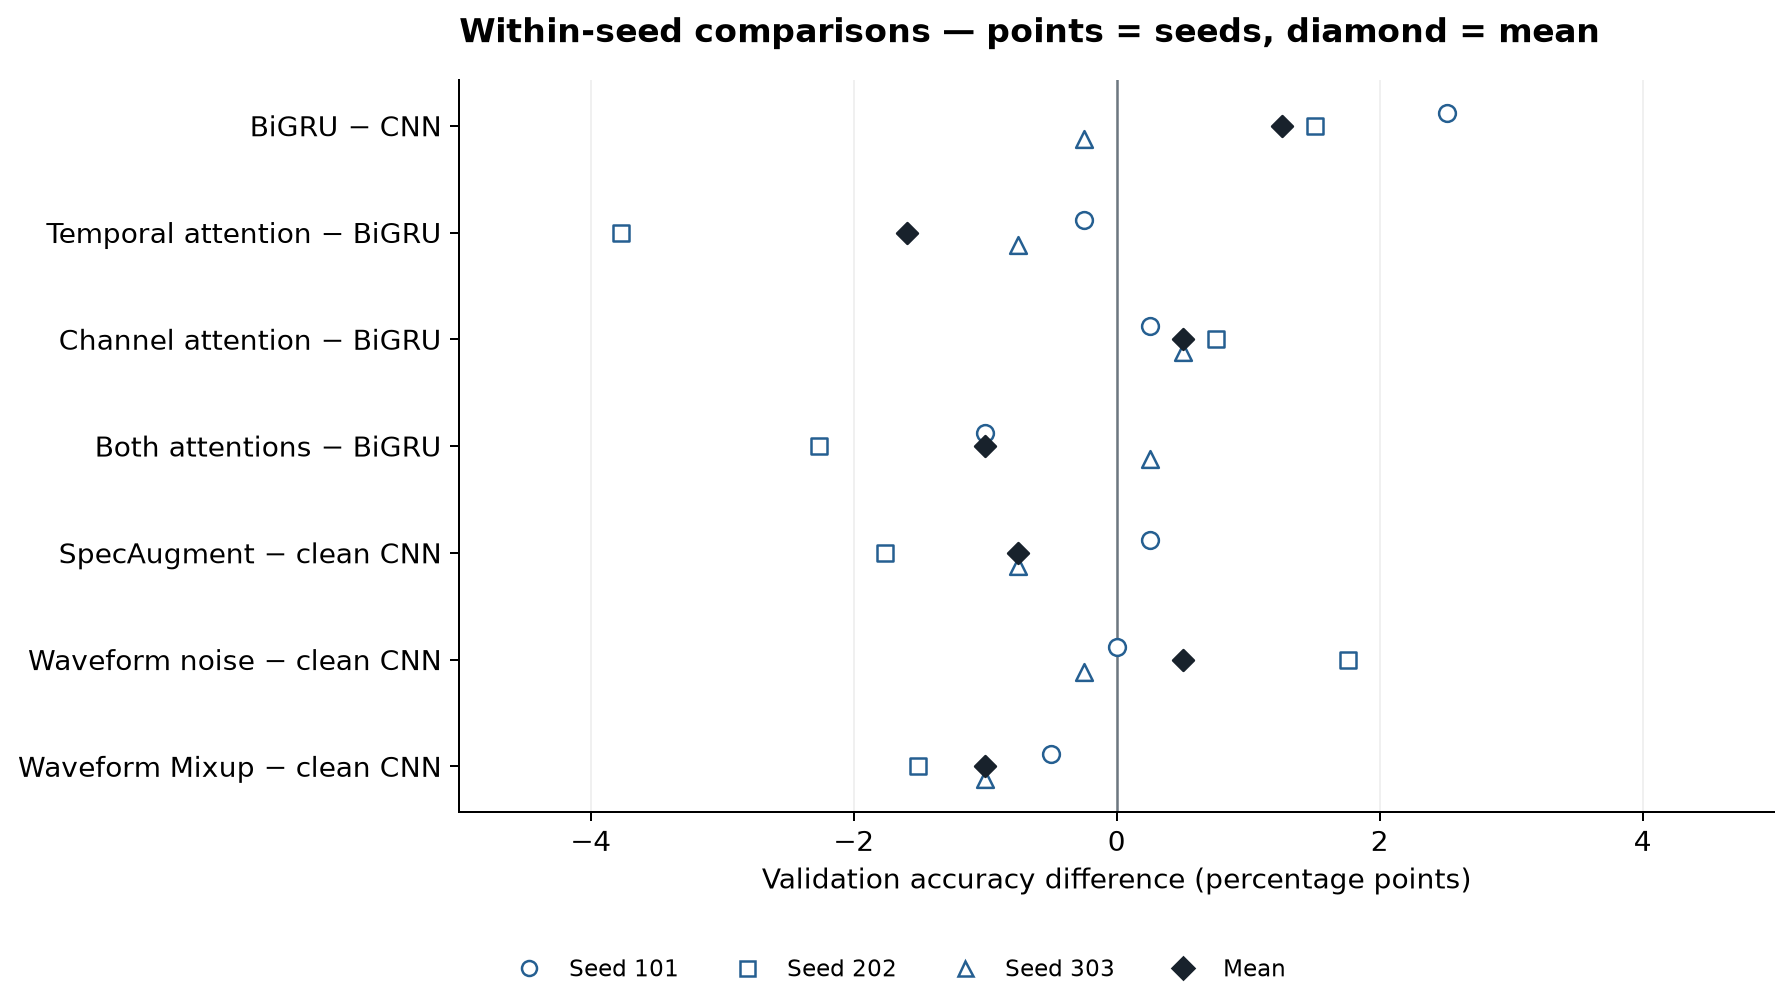

In [27]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/paired_effects.png'), width=1050))

### Figure 4. Track D uses the 26, 658-parameter pooled CNN; interpret separately from the main architecture track.

Scope: Original development matrix.

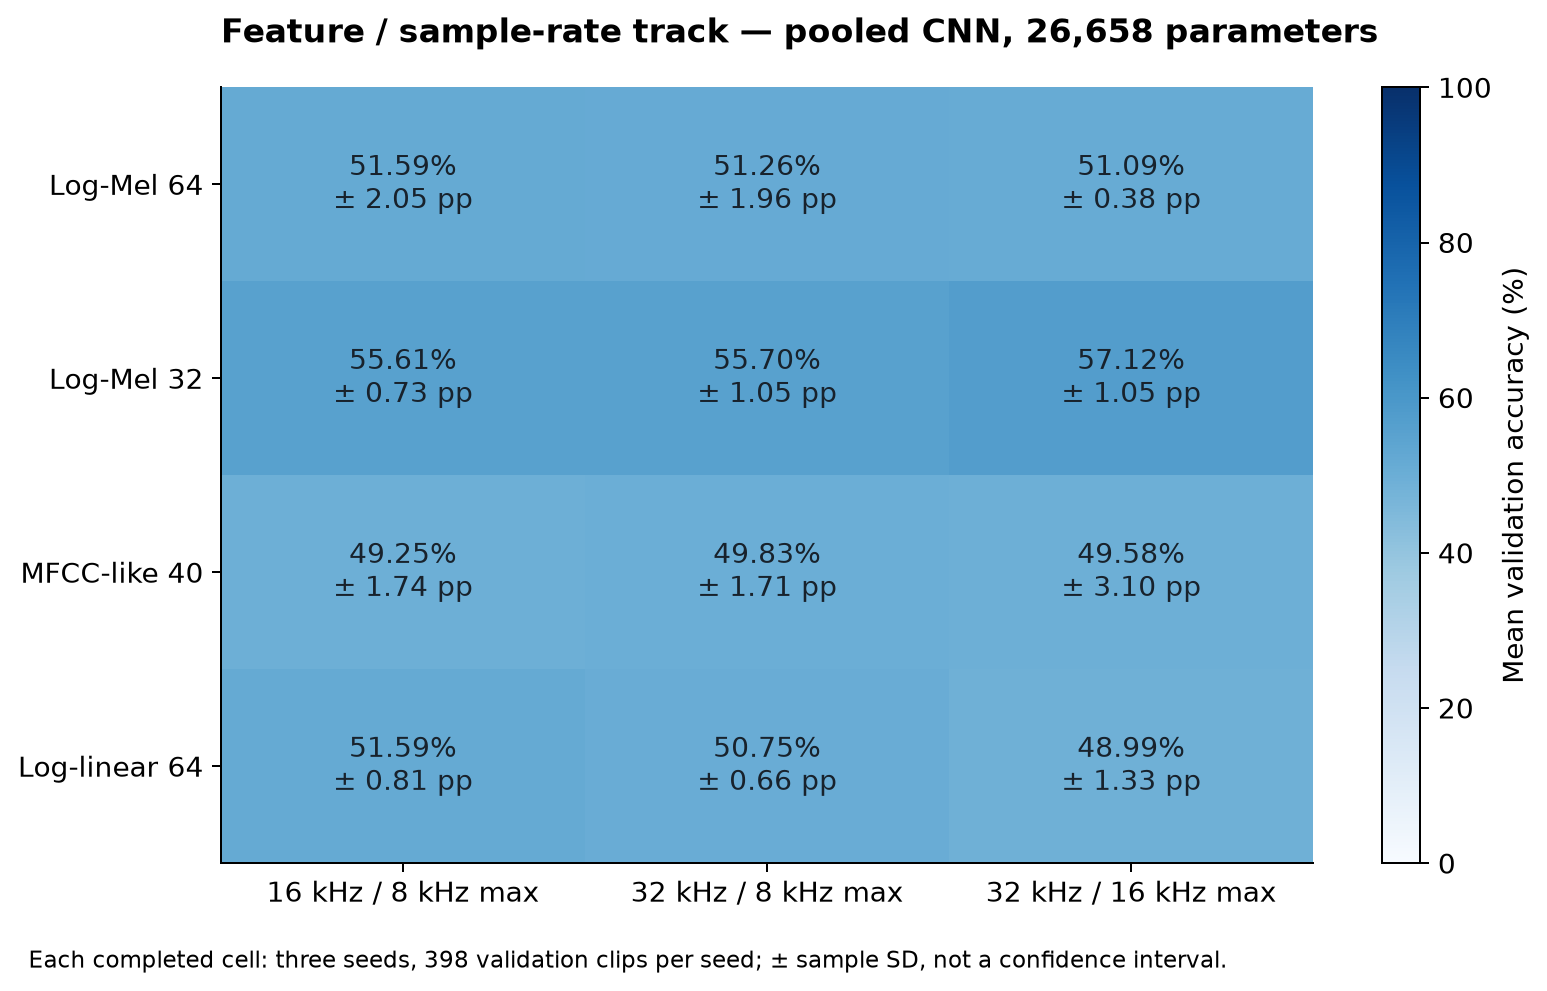

In [28]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/feature_sampling.png'), width=1050))

### Figure 5. Original seed101 robustness comparison: one fitted checkpoint per model

Scope: Original development matrix.

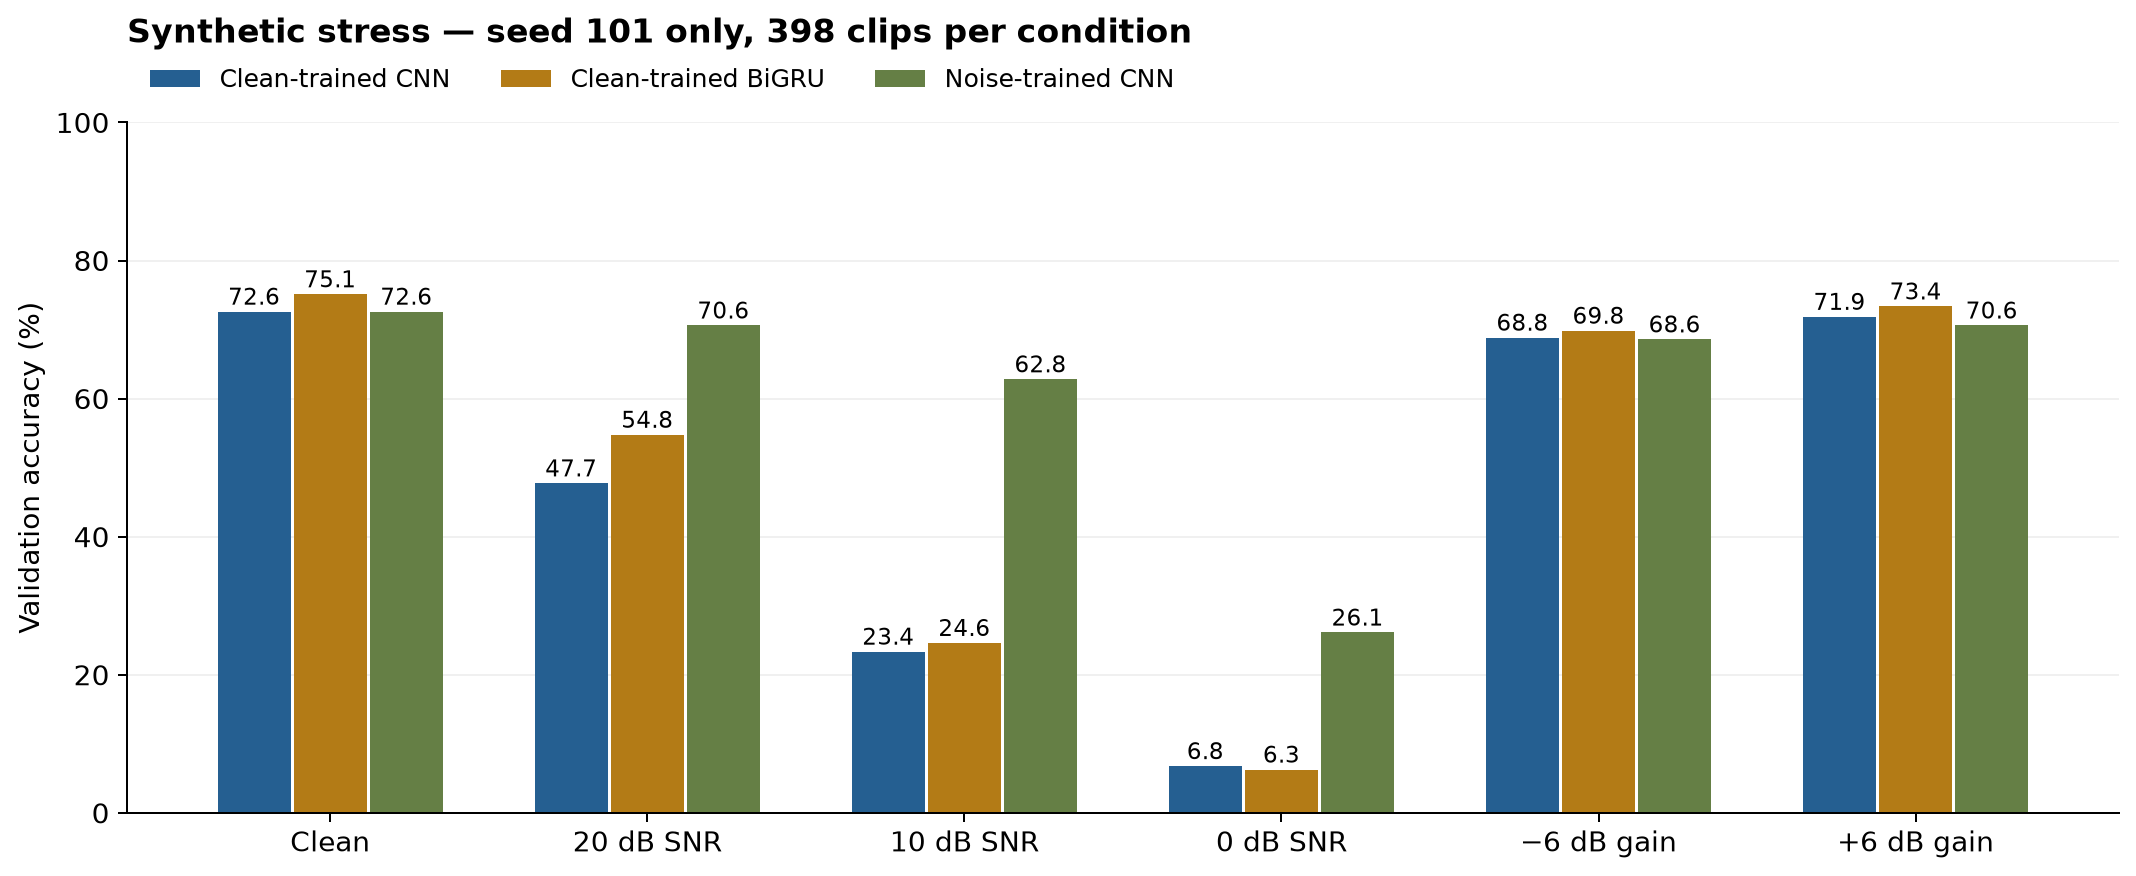

In [29]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/robustness.png'), width=1050))

### Figure 6. Fixed-seed101 validation curves; checkpoints use minimum cross-entropy.

Scope: Original development matrix.

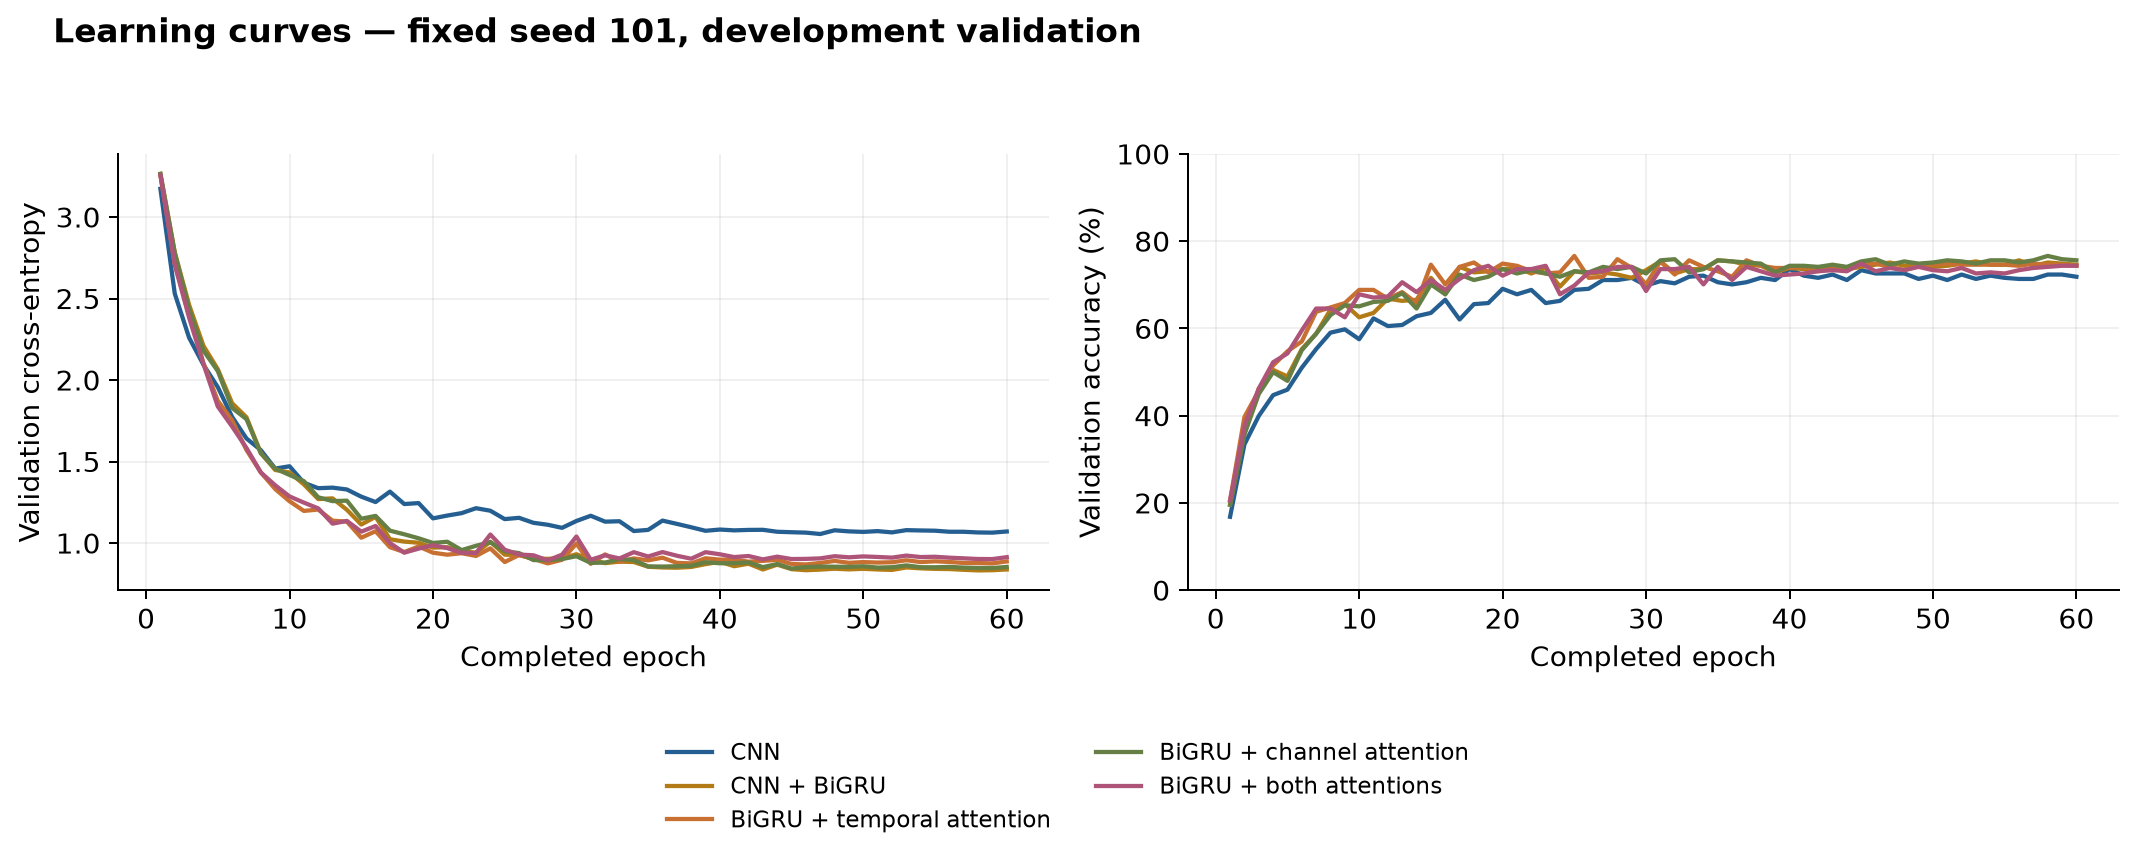

In [30]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/learning_curves.png'), width=1050))

### Figure 7. A real validation waveform and Log-Mel representation

Scope: Original development matrix.

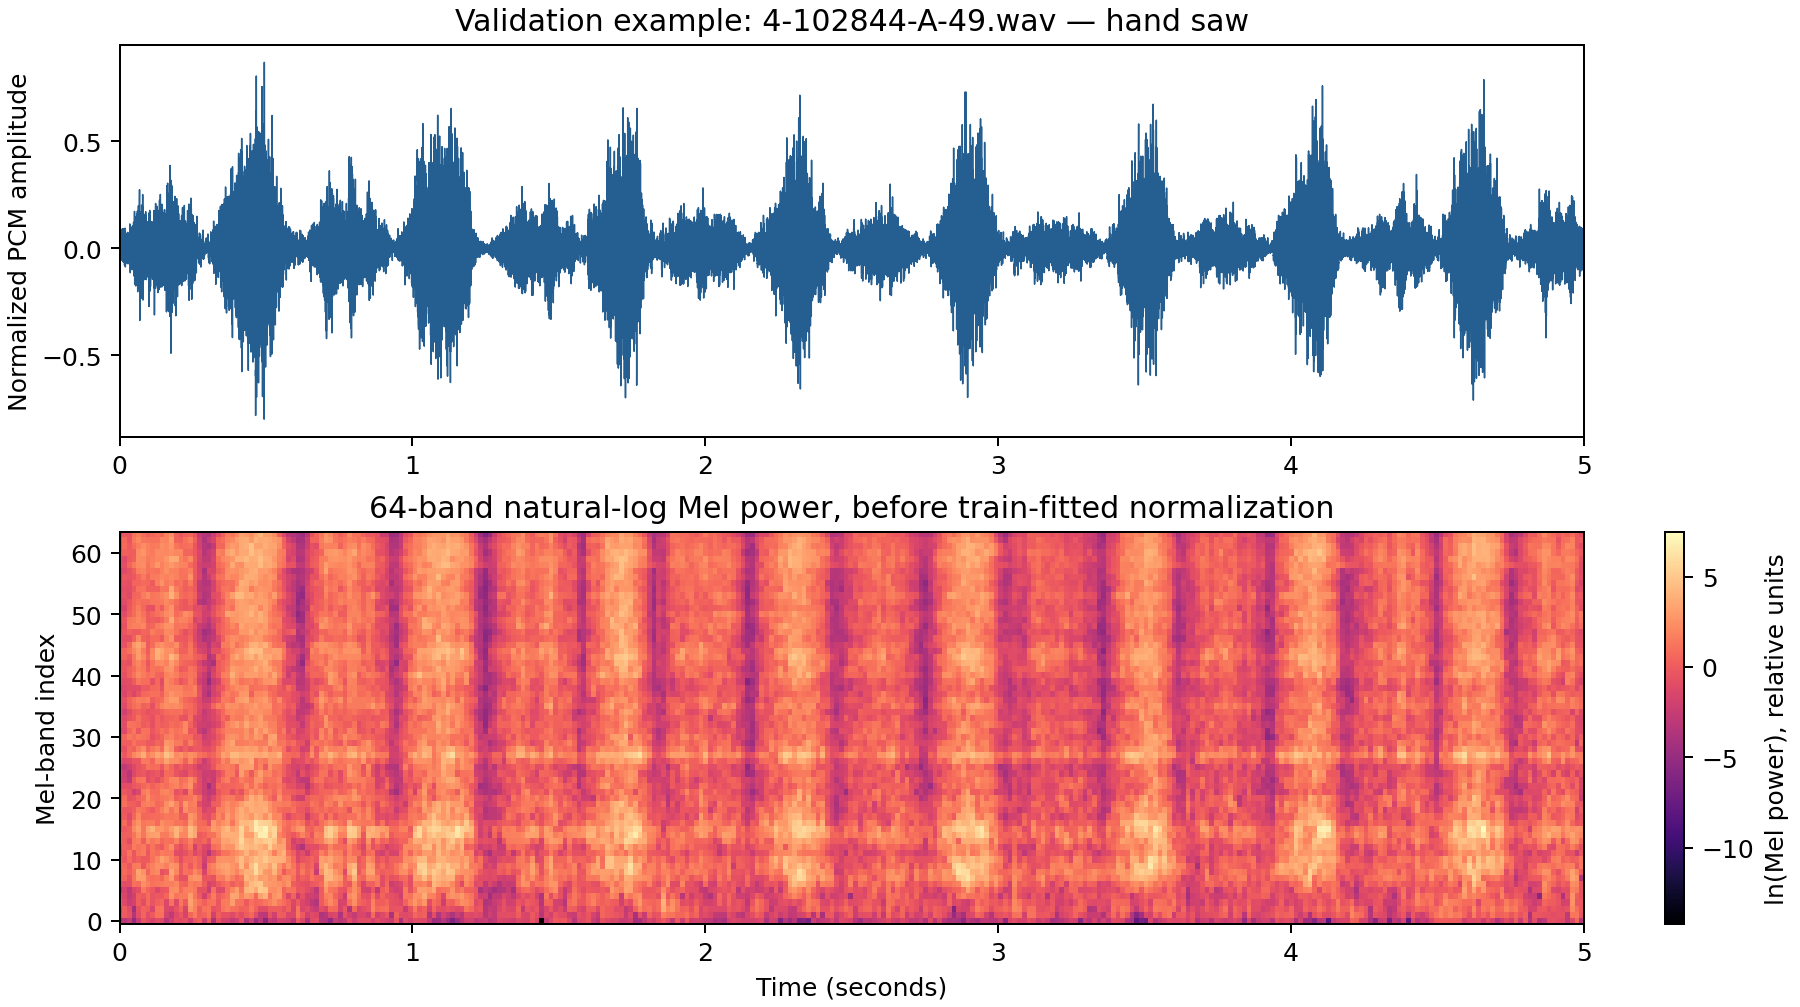

In [31]:
display(Image(filename=str(ROOT/'reports/figures/matrix_20261028/frontend_example.png'), width=1050))

### Figure 8. Completed three-seed Gaussian-noise and gain results; bars show sample SD, not confidence intervals

Scope: November inference/analysis follow-up.

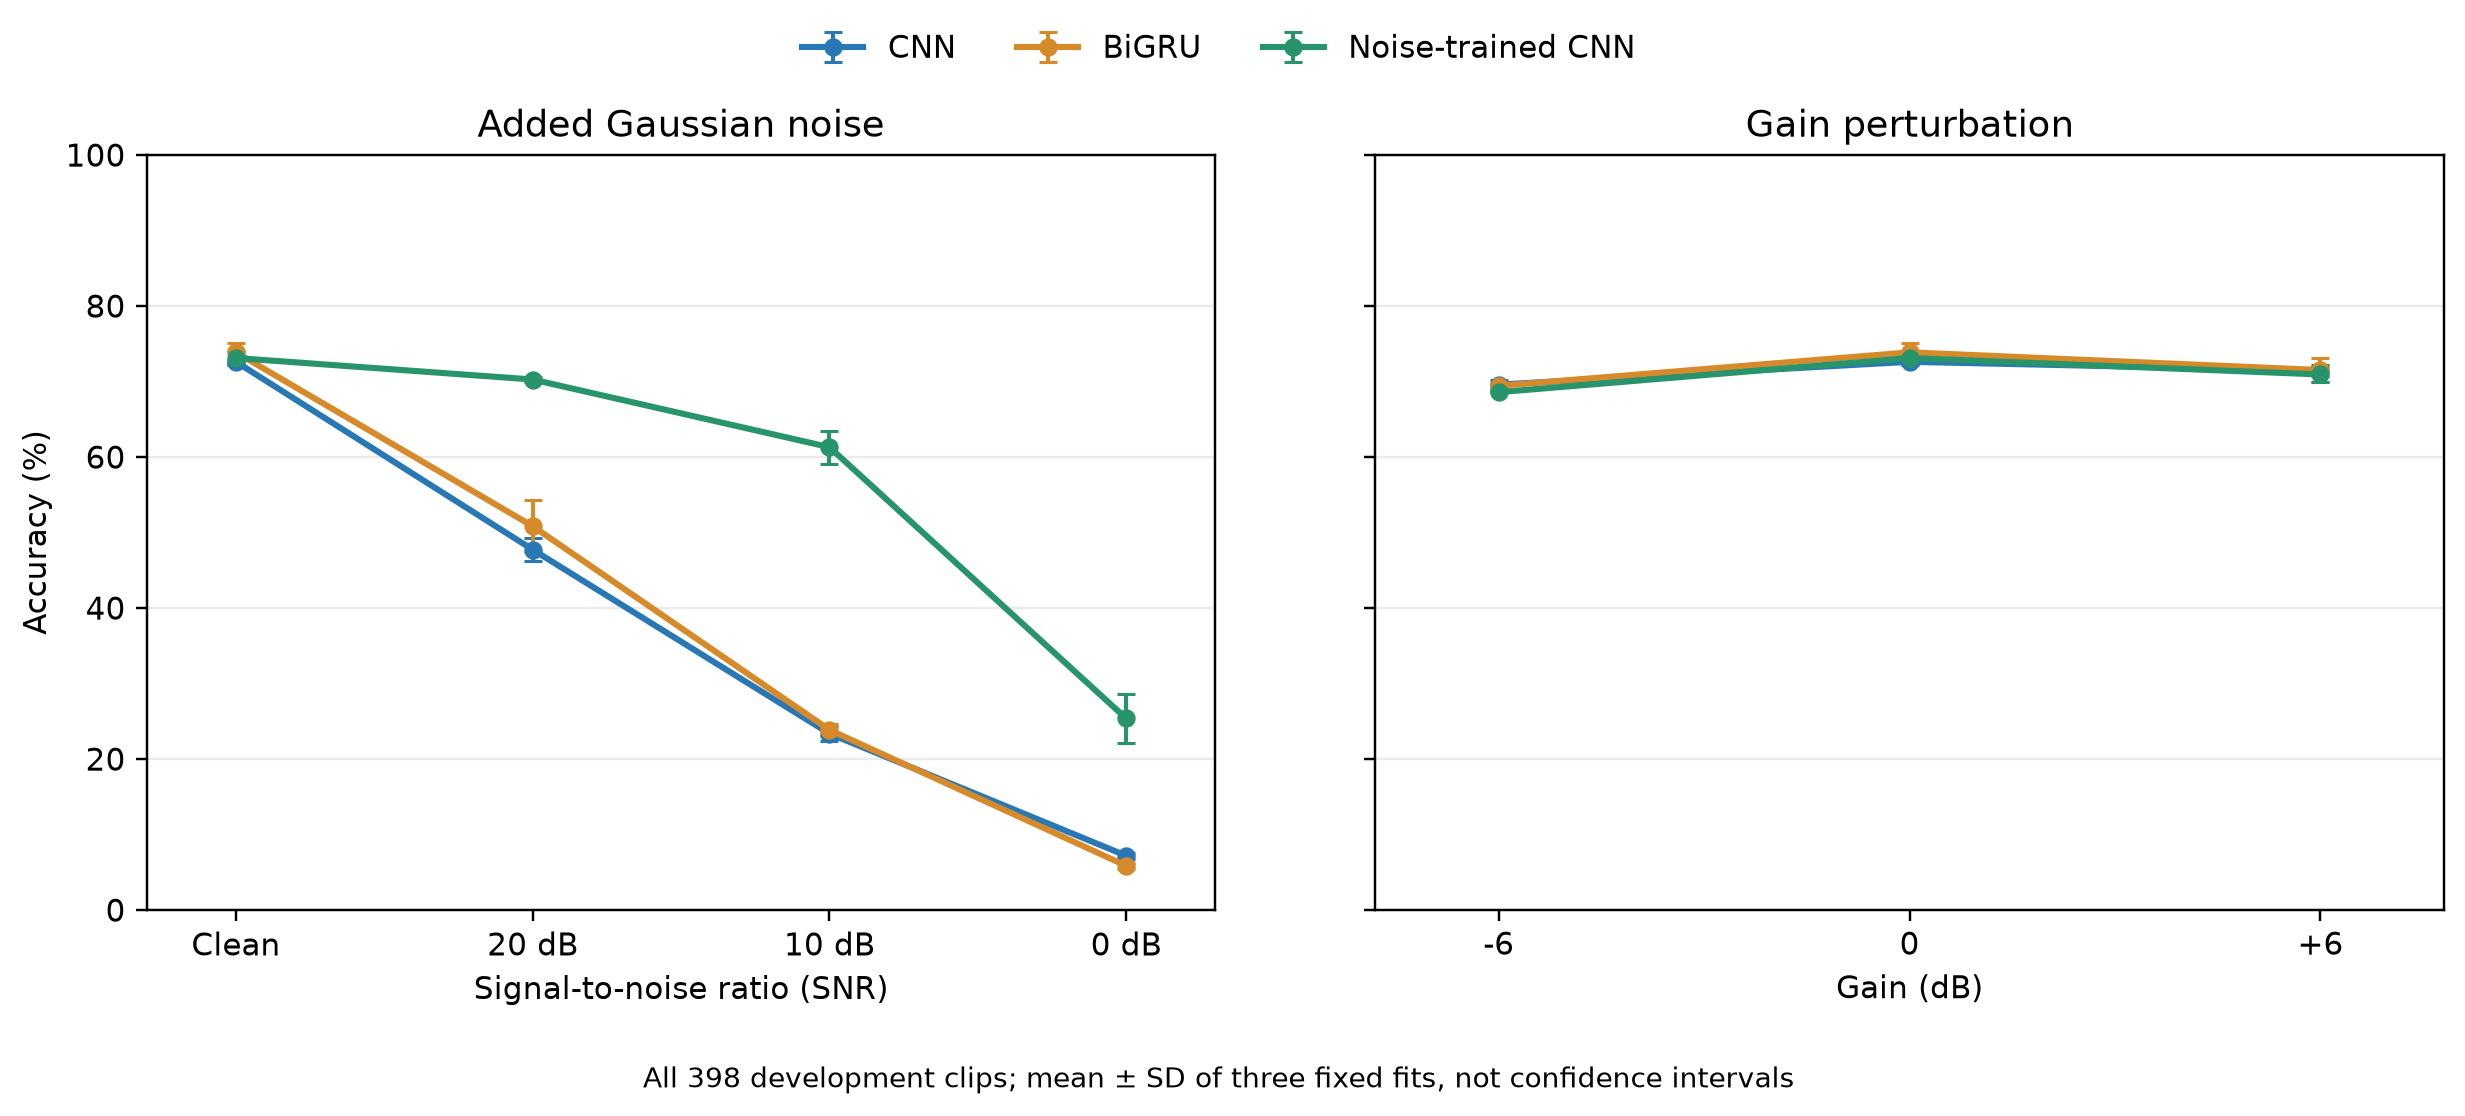

In [32]:
display(Image(filename=str(ROOT/'reports/final_20261105/three_seed_robustness.png'), width=1050))

### Figure 9. Feature-study loss trajectories: Log-Mel 32 and Log-Mel 64, three fixed seeds

Scope: November inference/analysis follow-up.

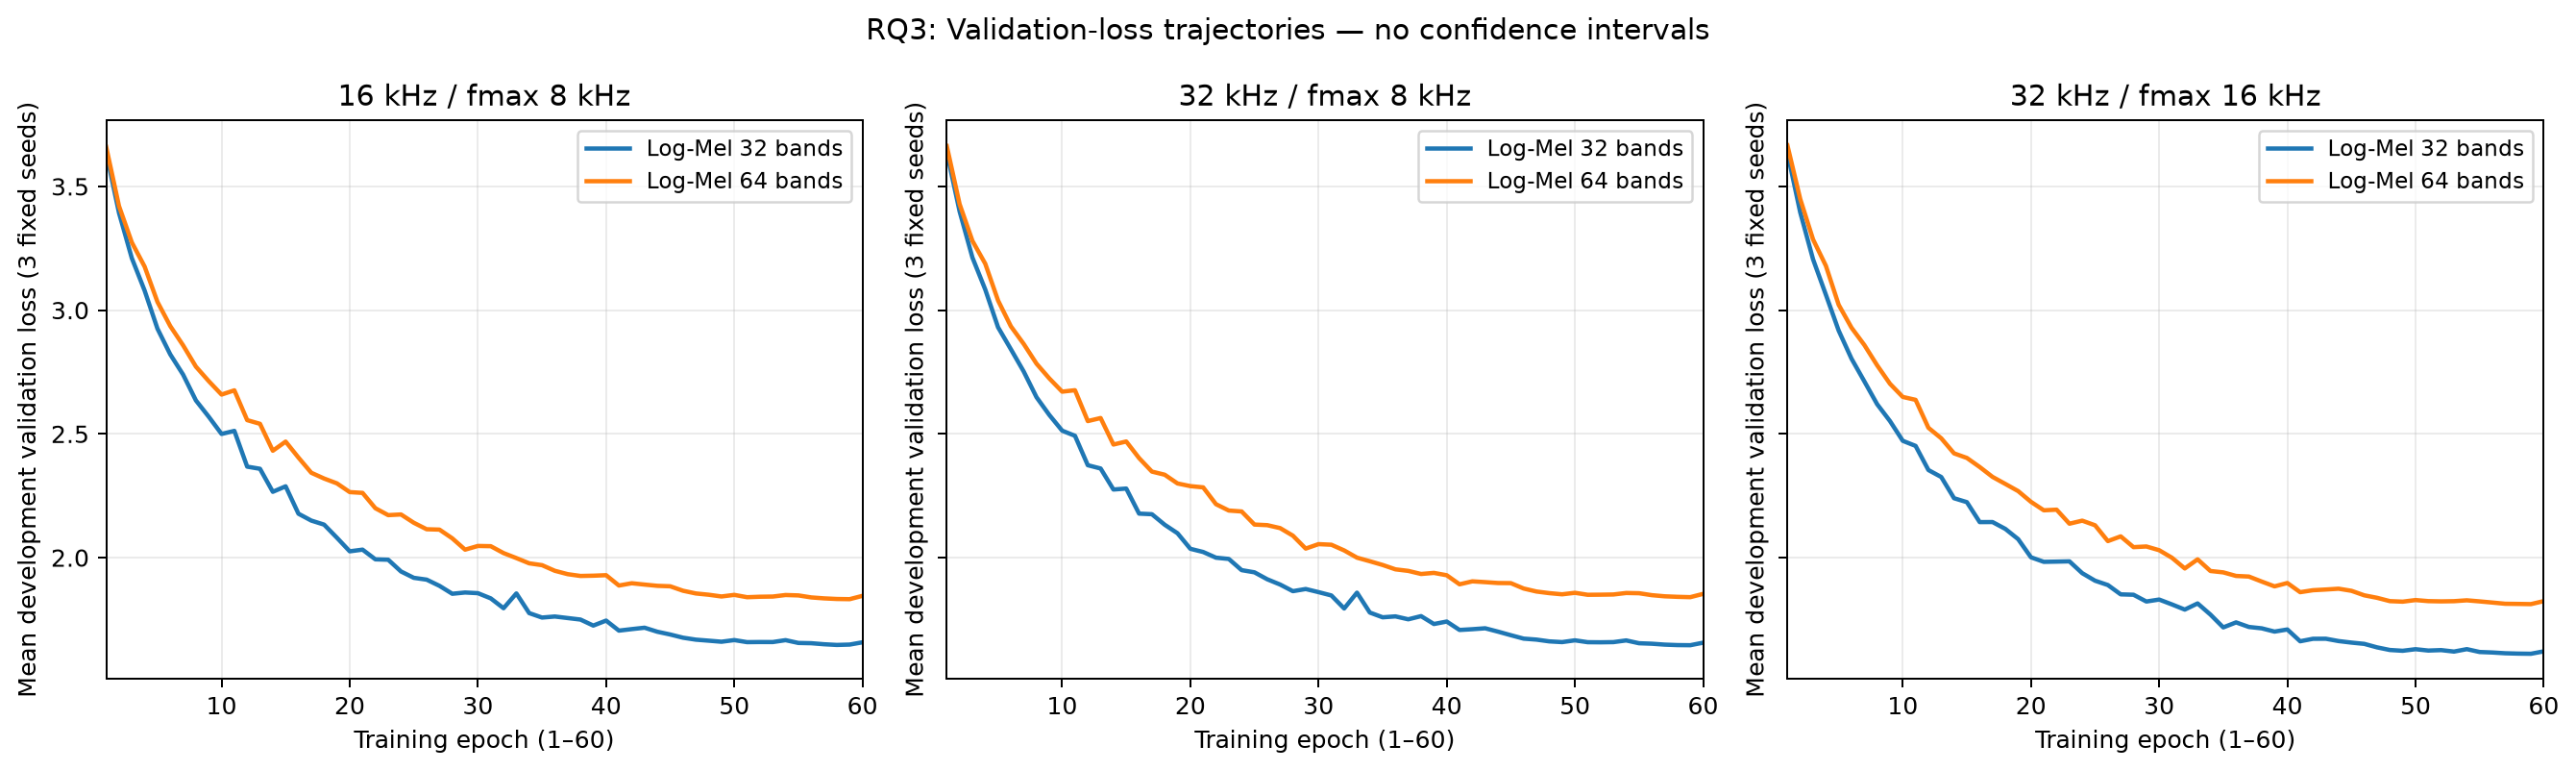

In [33]:
display(Image(filename=str(ROOT/'reports/followup_20261104/convergence/validation_loss_curves.png'), width=1050))

### Figure 10. Four selected real-audio error cases: waveform and Log-Mel evidence, not causal explanations

Scope: November inference/analysis follow-up.

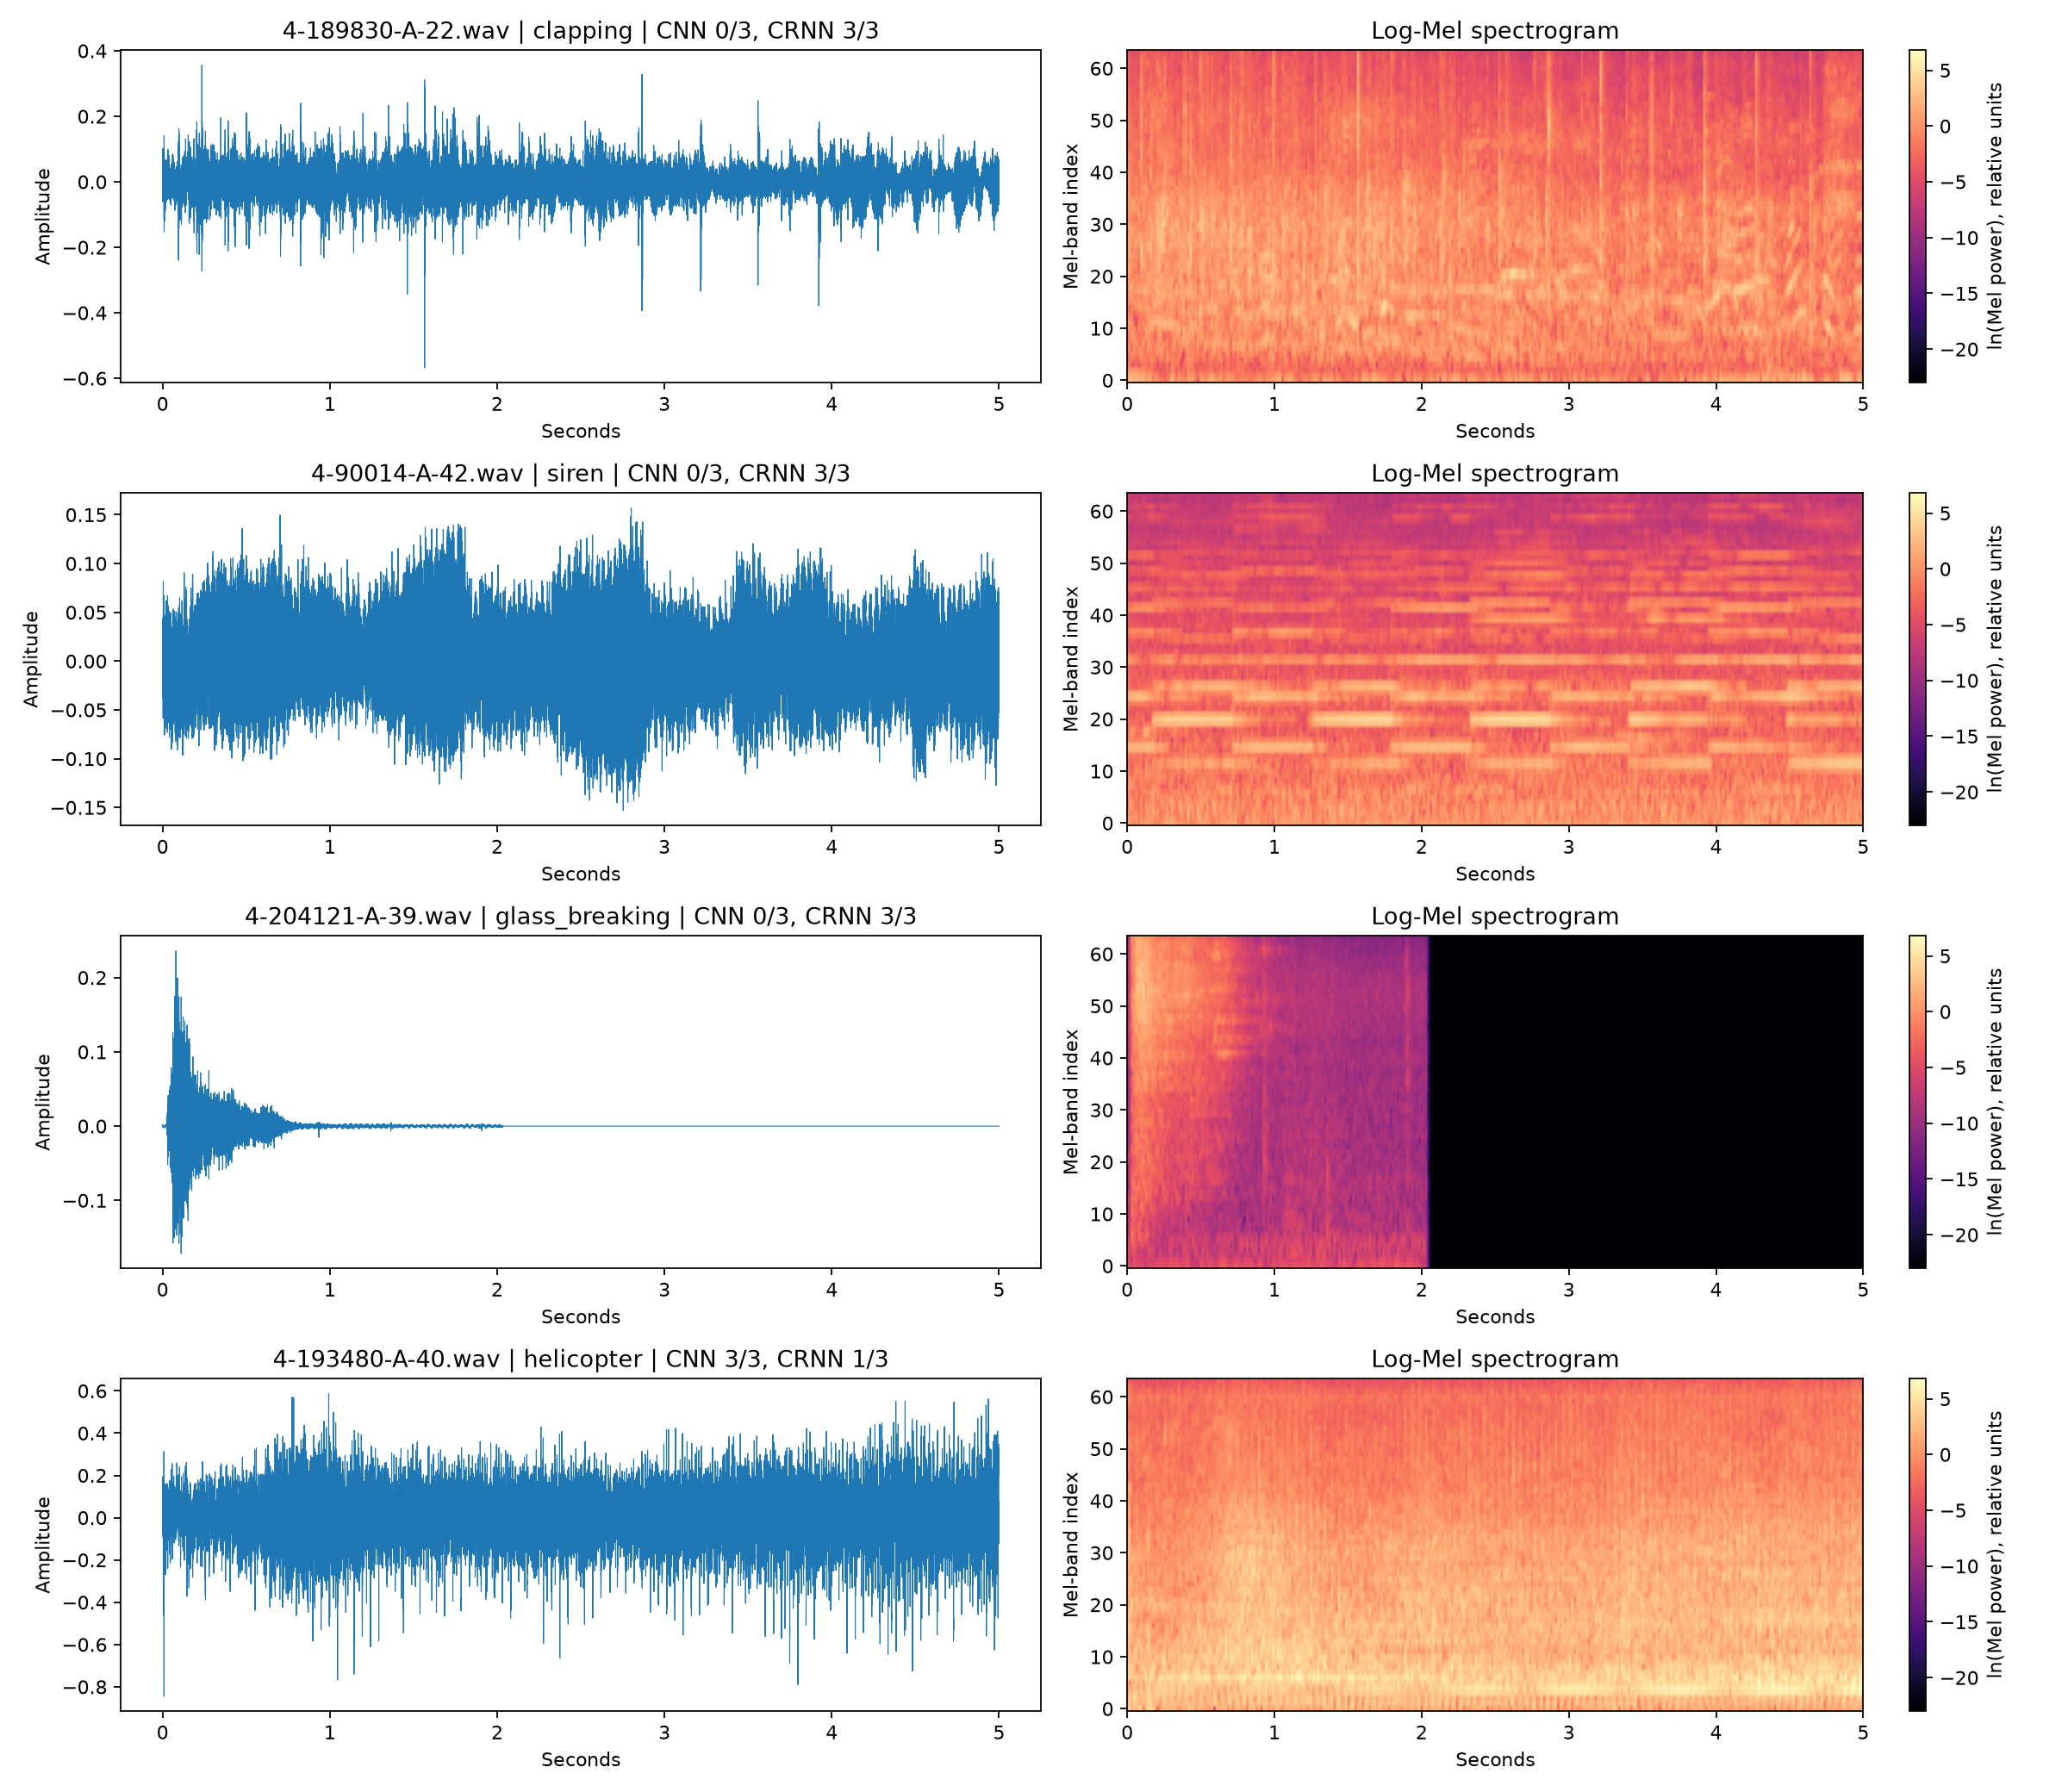

In [34]:
display(Image(filename=str(ROOT/'reports/followup_20261104/error_cases/error_case_atlas.png'), width=1050))

### Figure 11. CRNN encoder-token intervention effects with conditional source-bootstrap intervals

Scope: November inference/analysis follow-up.

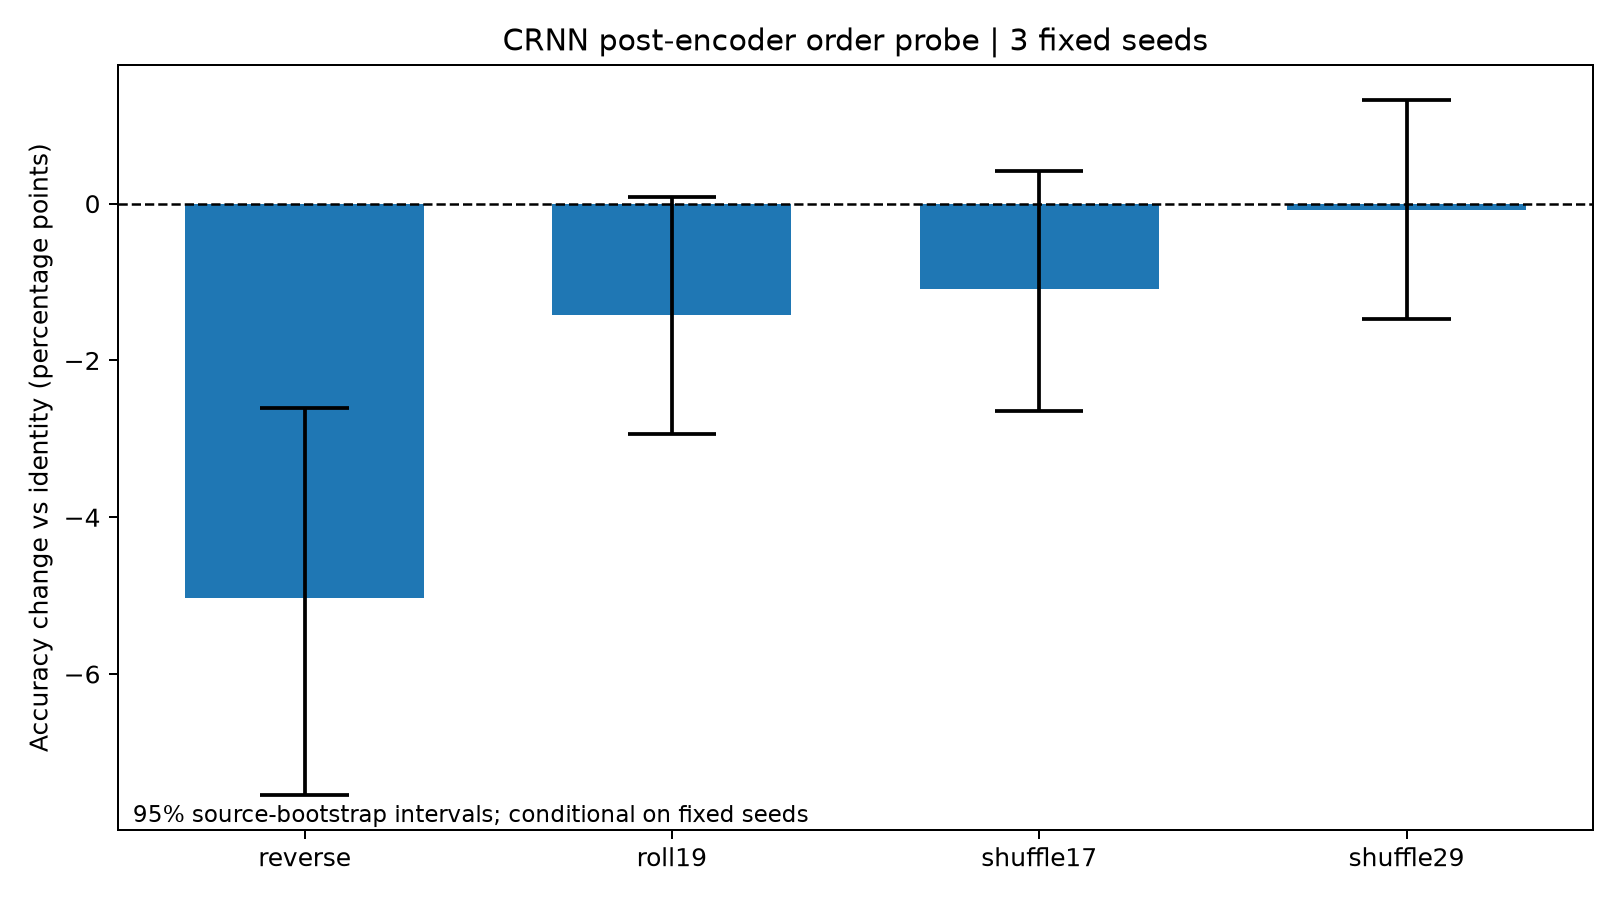

In [35]:
display(Image(filename=str(ROOT/'reports/temporal_20261105/crnn_accuracy_change.png'), width=1050))

### Figure 12. Historical study - Model comparison

Scope: Historical baseline study; not new confirmation.

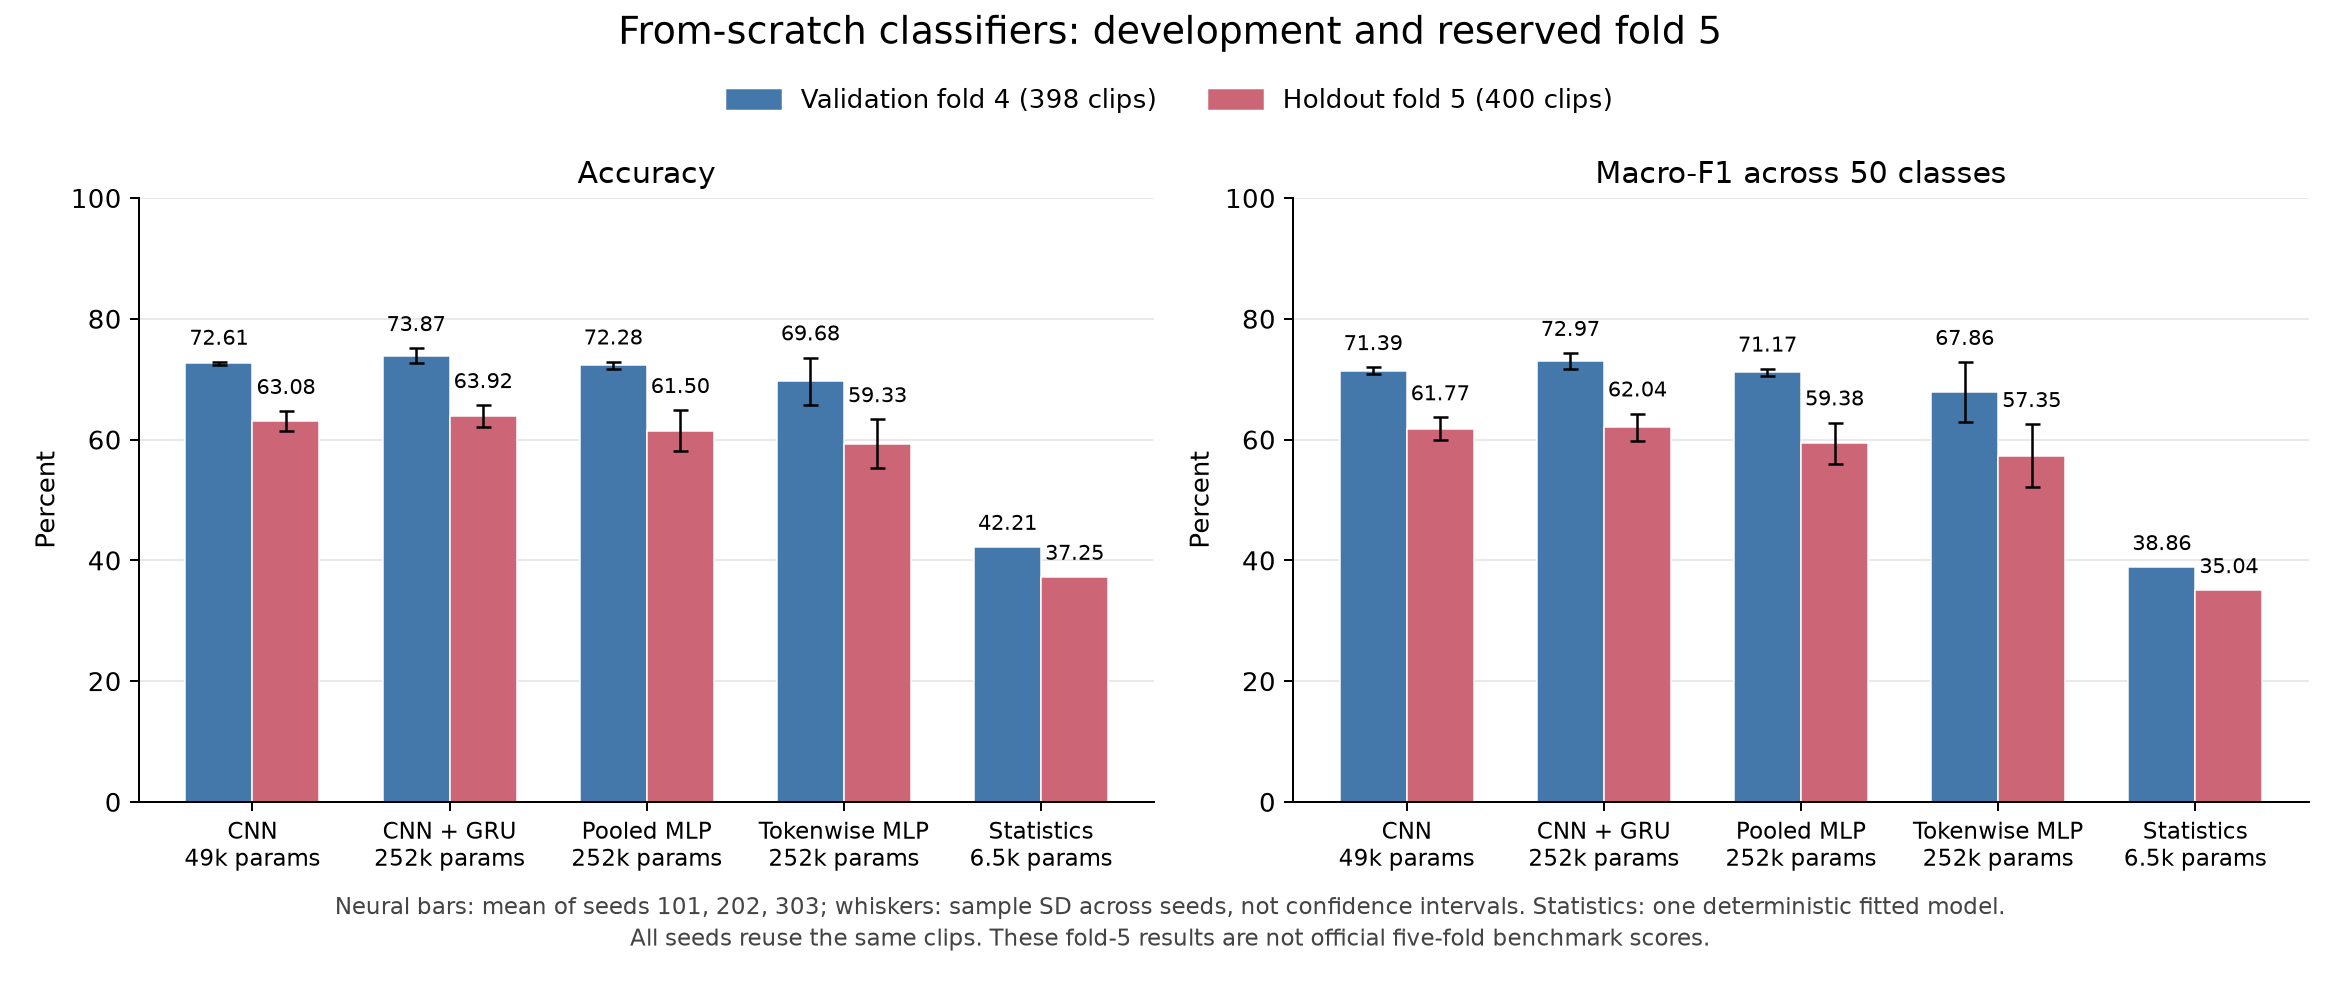

In [36]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/model_comparison.png'), width=1050))

### Figure 13. Historical study - Learning curves

Scope: Historical baseline study; not new confirmation.

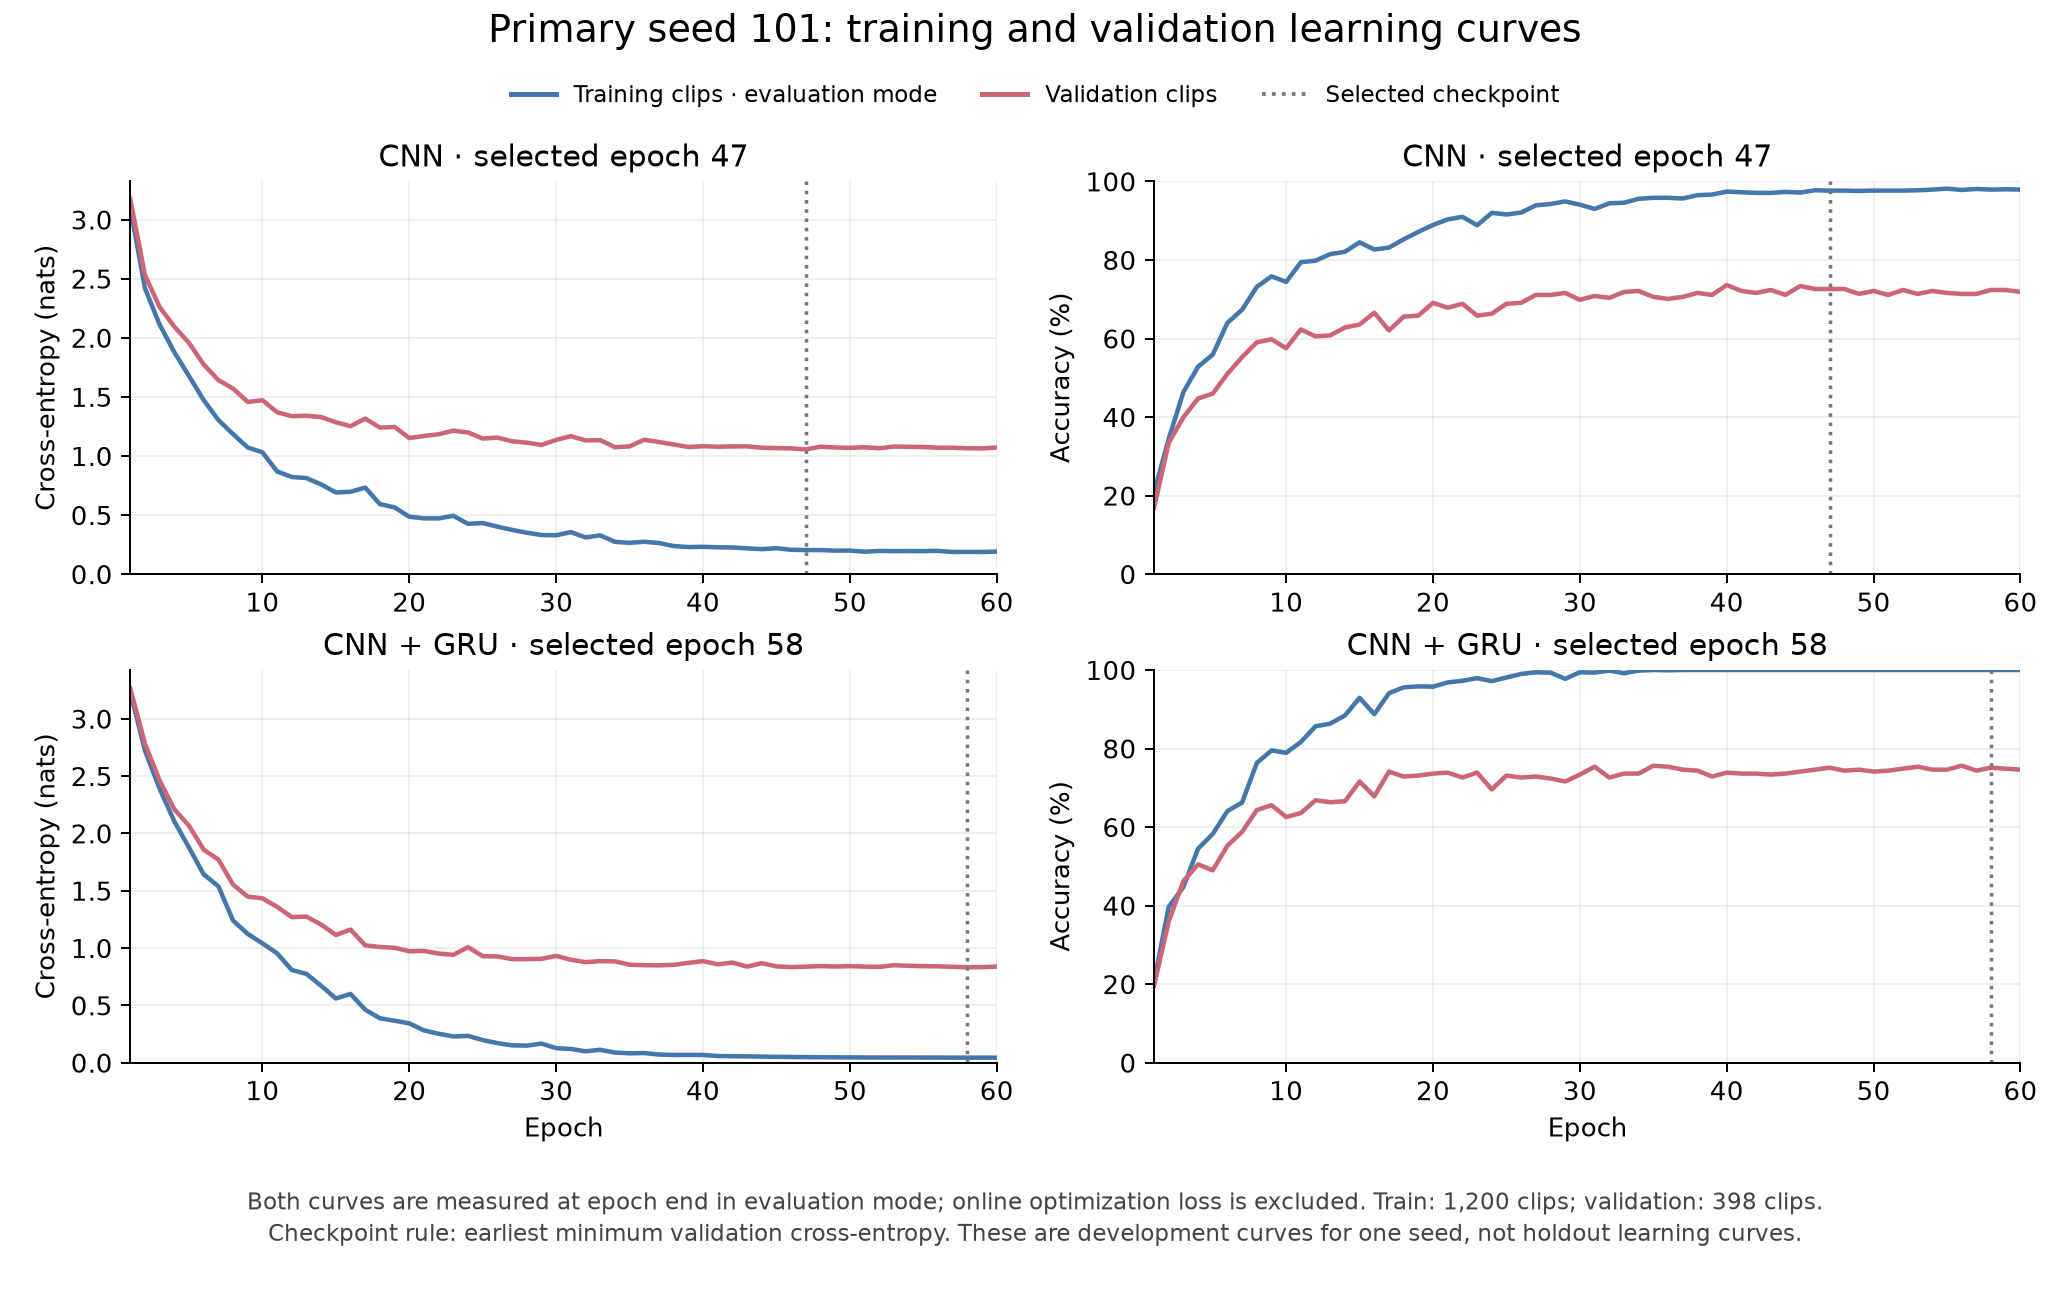

In [37]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/learning_curves.png'), width=1050))

### Figure 14. Historical study - Named confusions

Scope: Historical baseline study; not new confirmation.

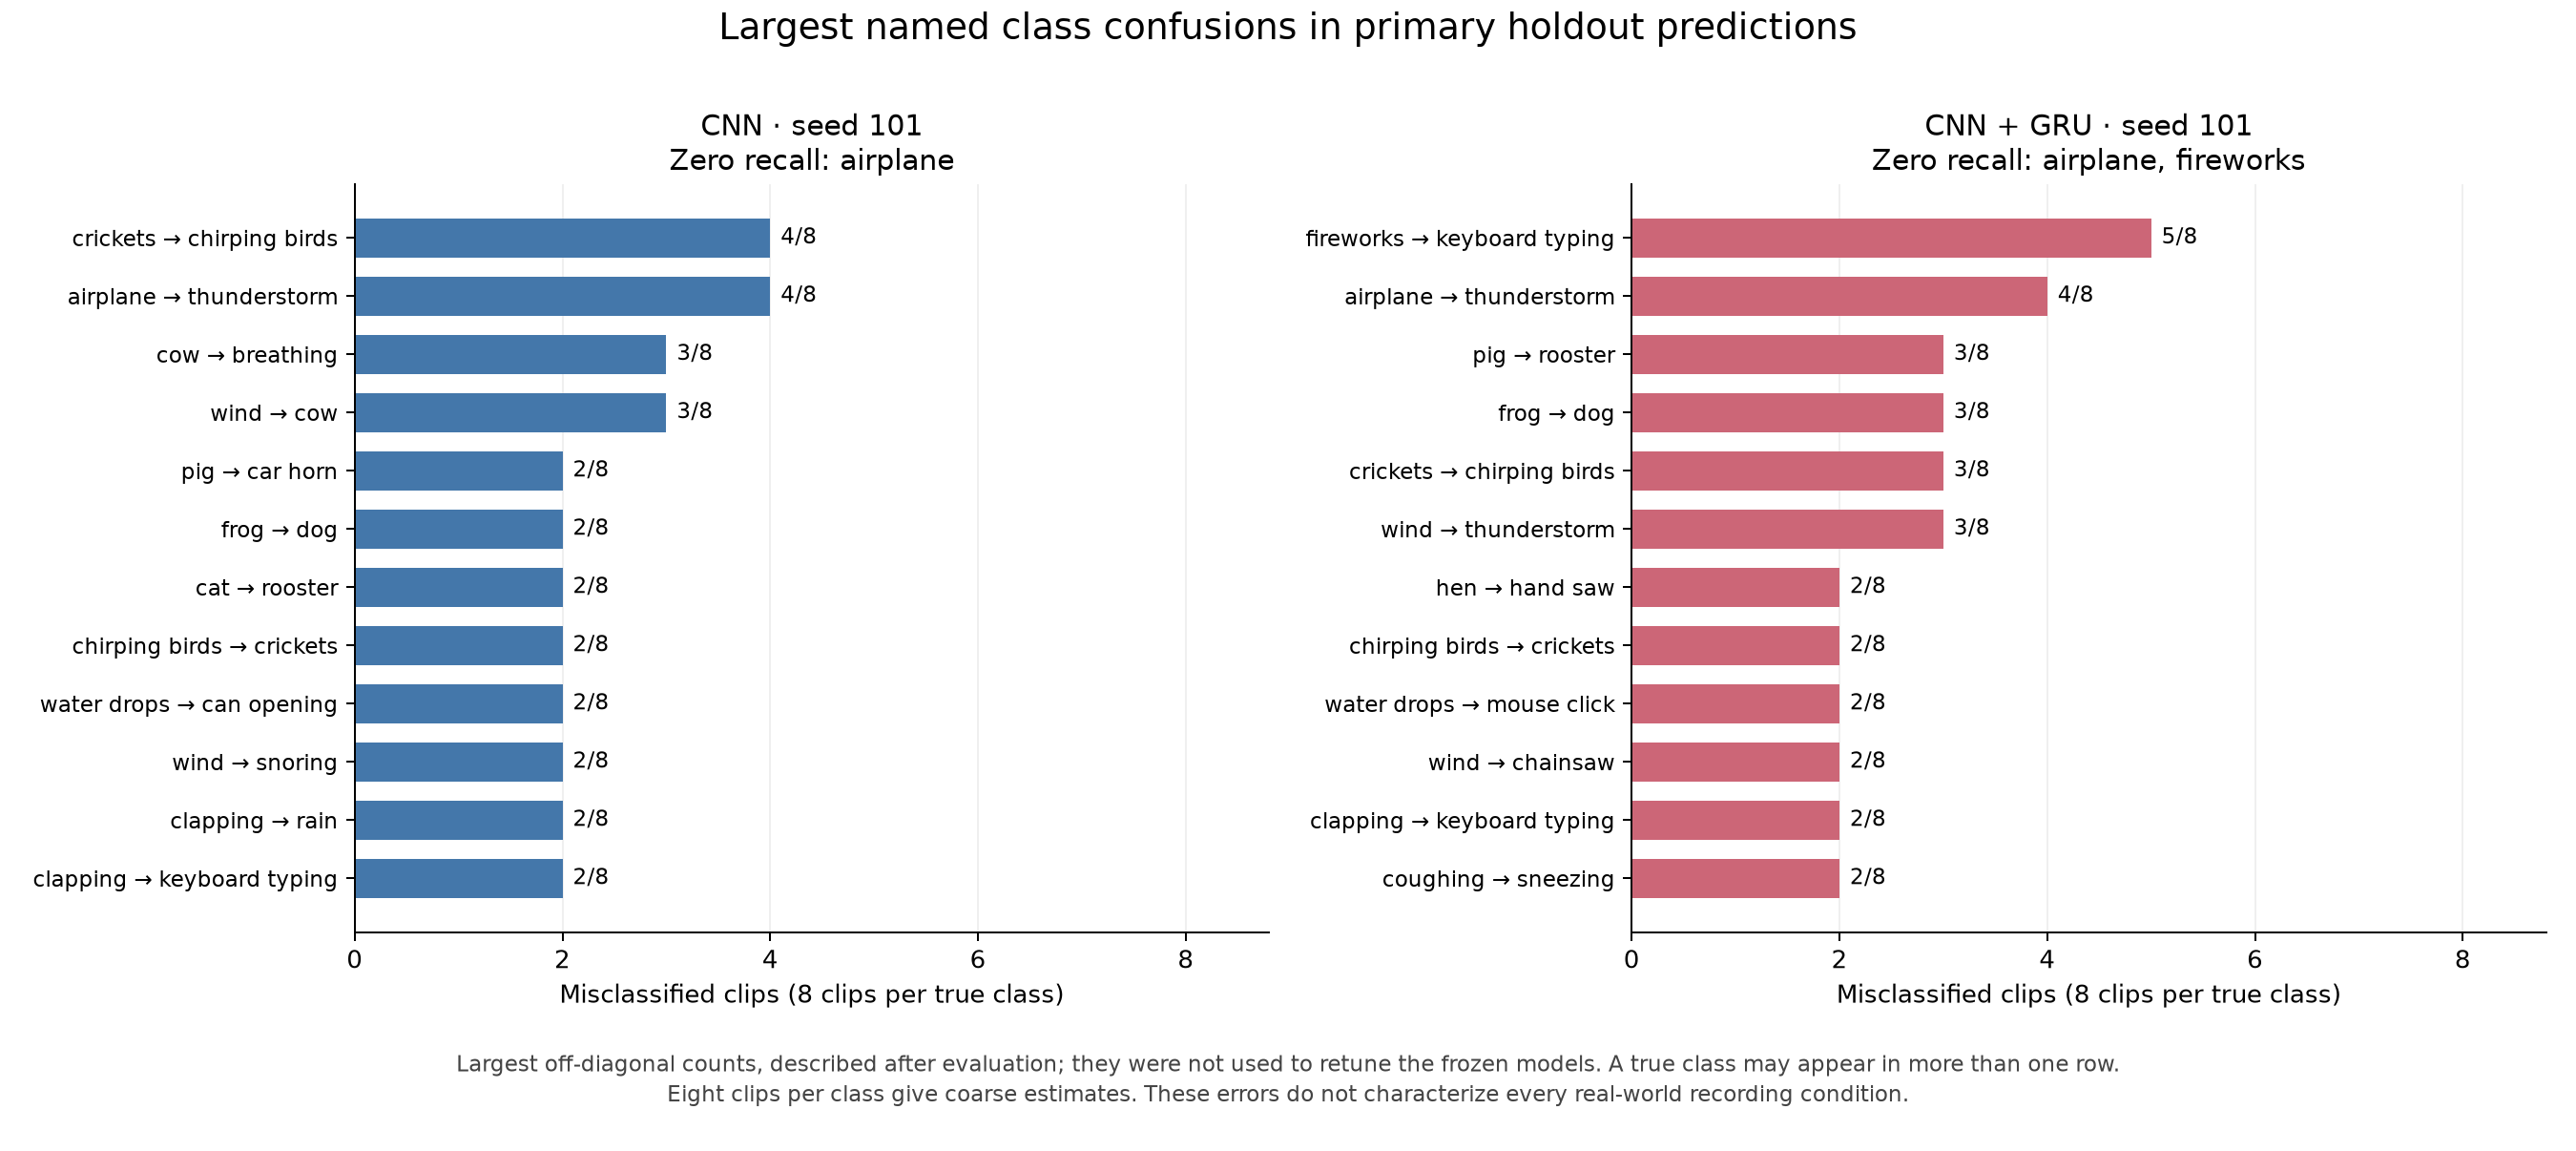

In [38]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/top_confusions.png'), width=1050))

### Figure 15. Historical study - Order probe

Scope: Historical baseline study; not new confirmation.

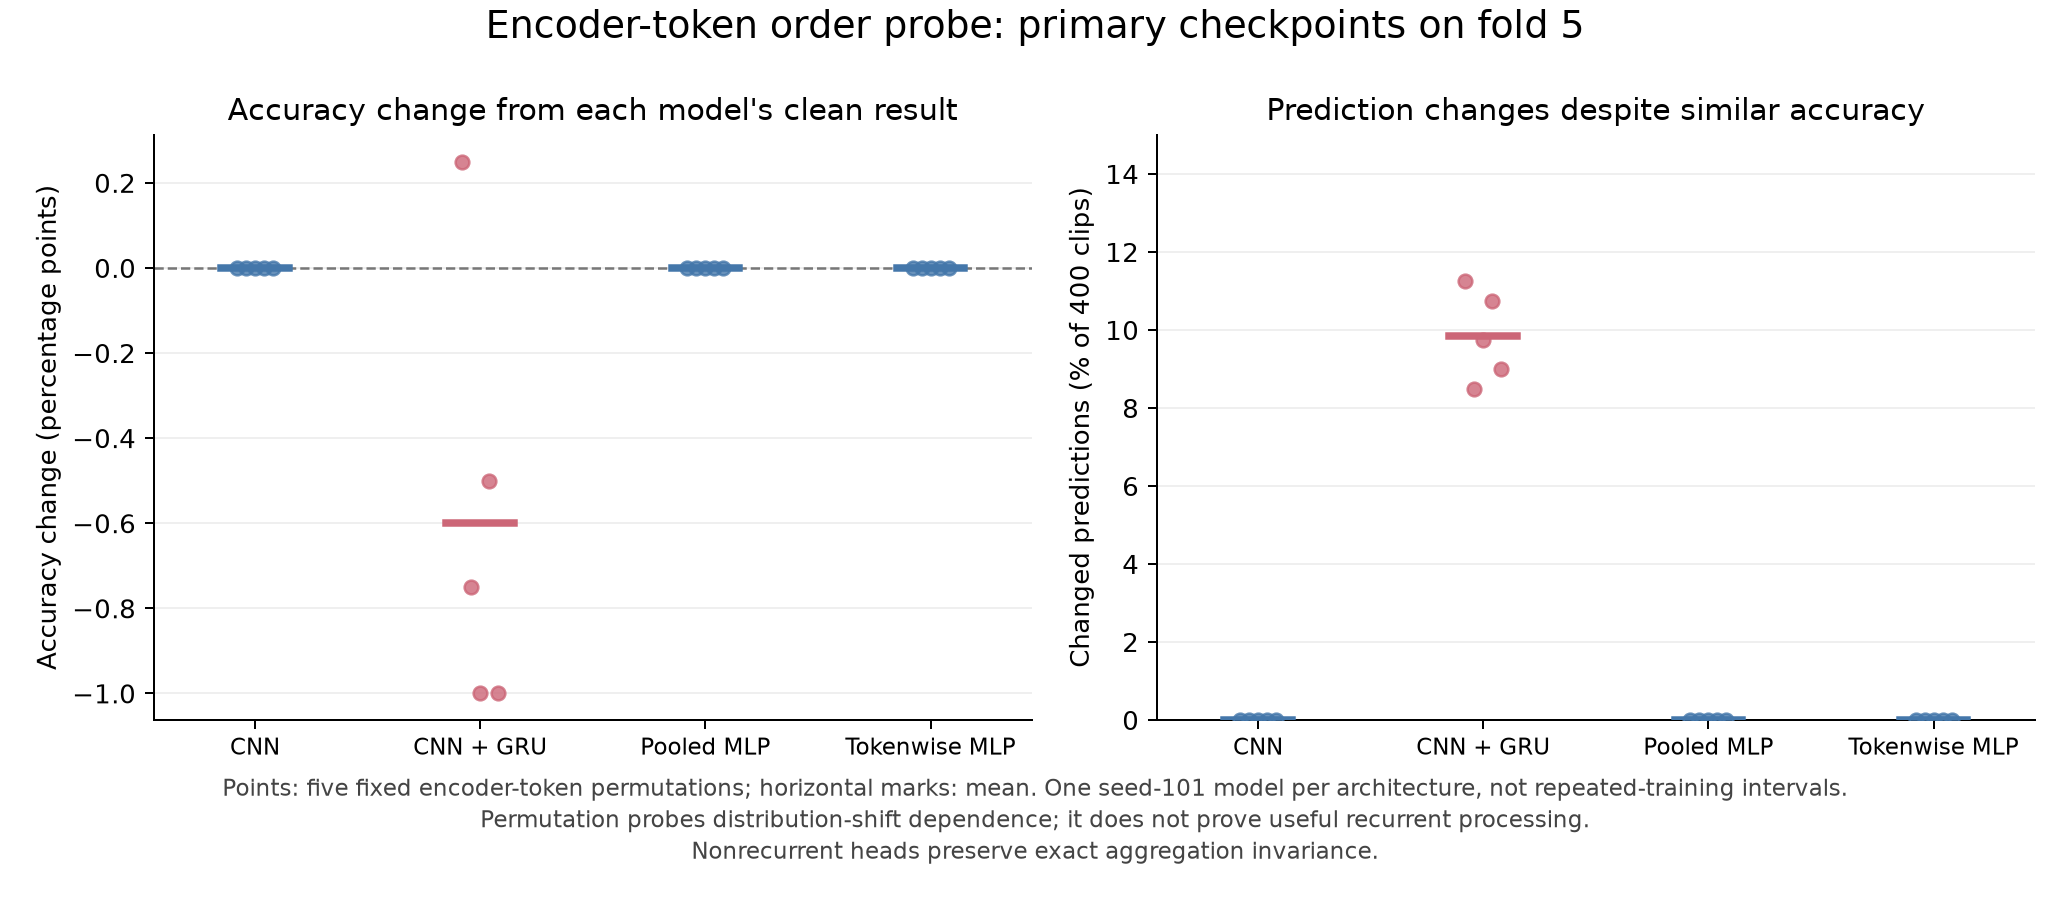

In [39]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/order_probe.png'), width=1050))

### Figure 16. Historical study - Synthetic stress

Scope: Historical baseline study; not new confirmation.

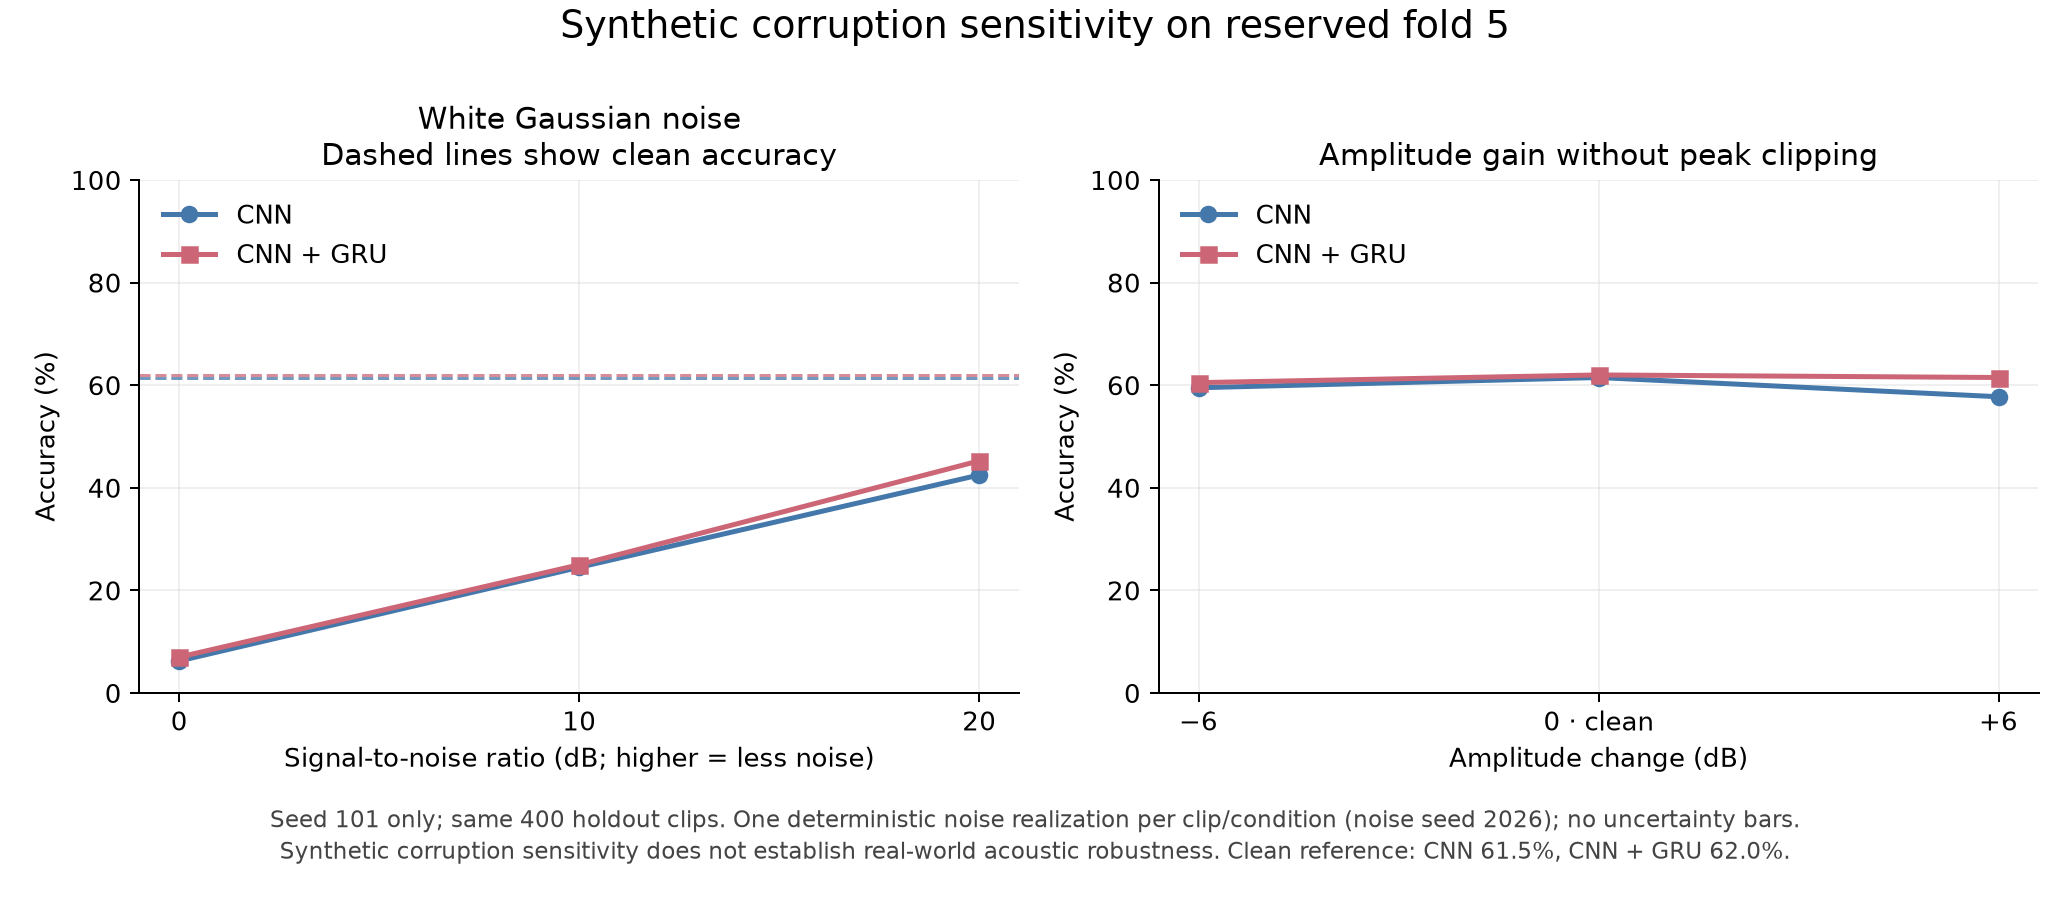

In [40]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/synthetic_stress.png'), width=1050))

### Figure 17. Historical study - Five-fold characterization

Scope: Historical baseline study; not new confirmation.

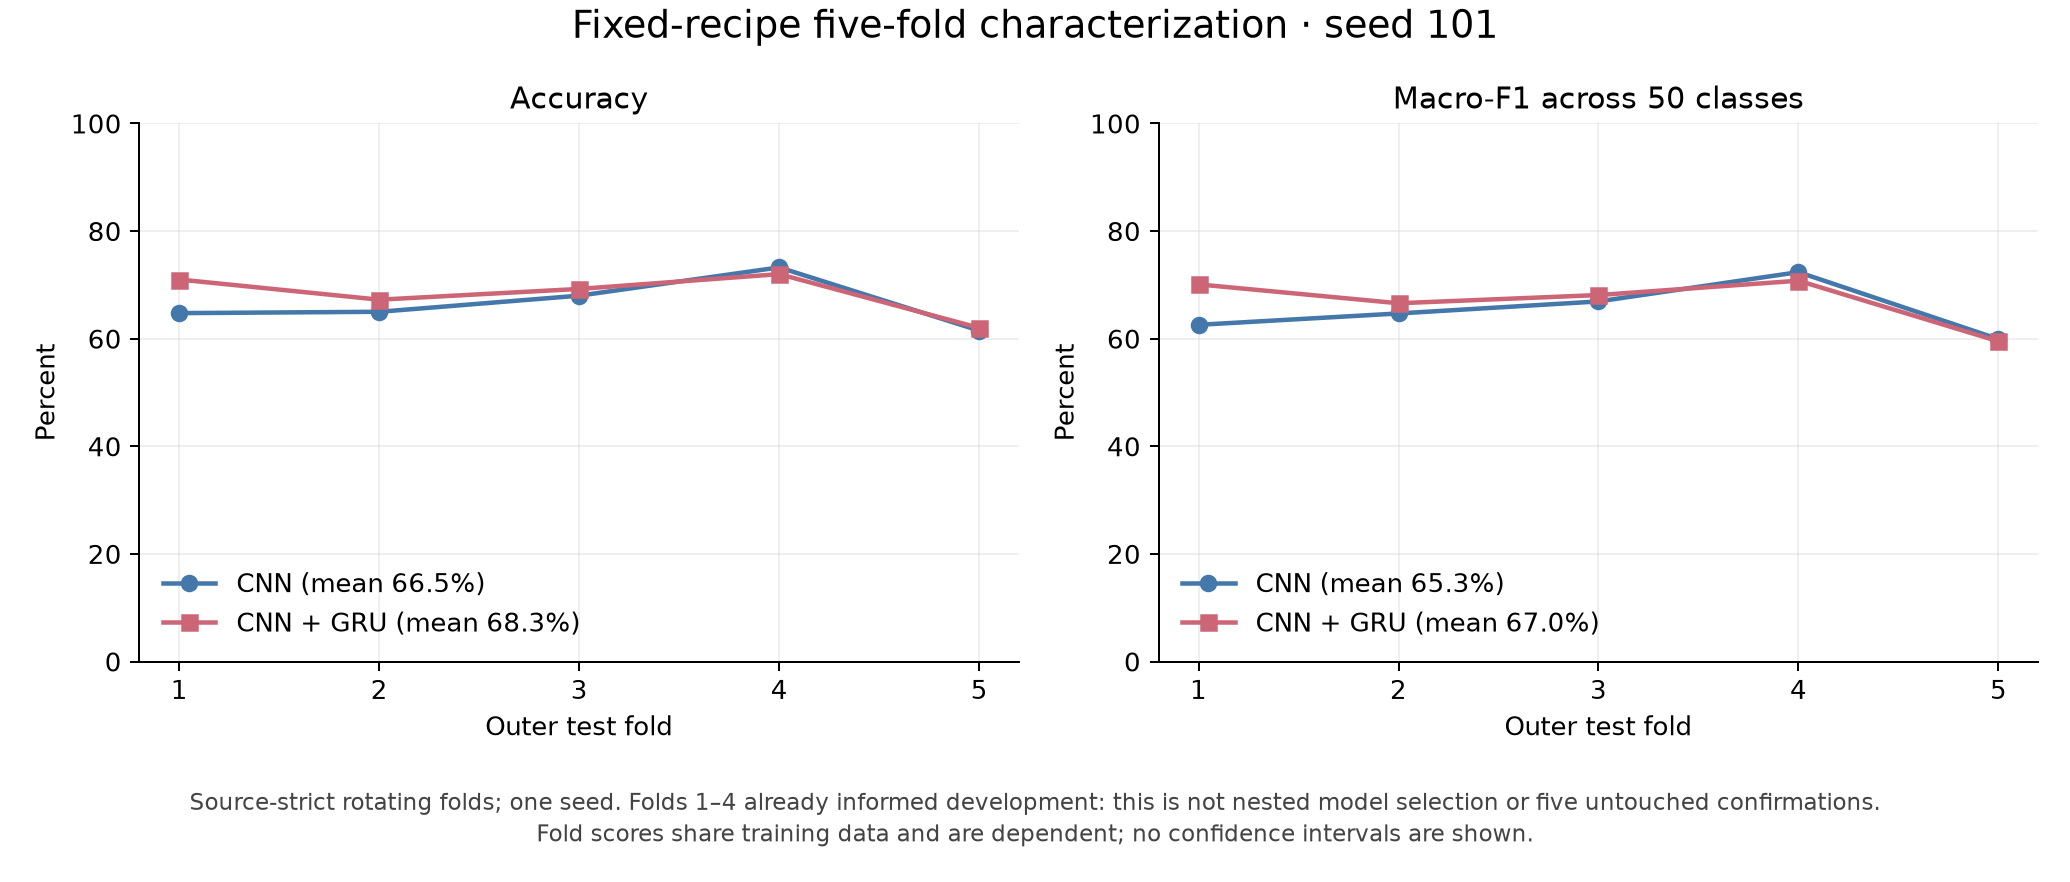

In [41]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/cross_validation.png'), width=1050))

### Figure 18. Historical study - CNN primary fold-5 confusion matrix

Scope: Historical baseline study; not new confirmation.

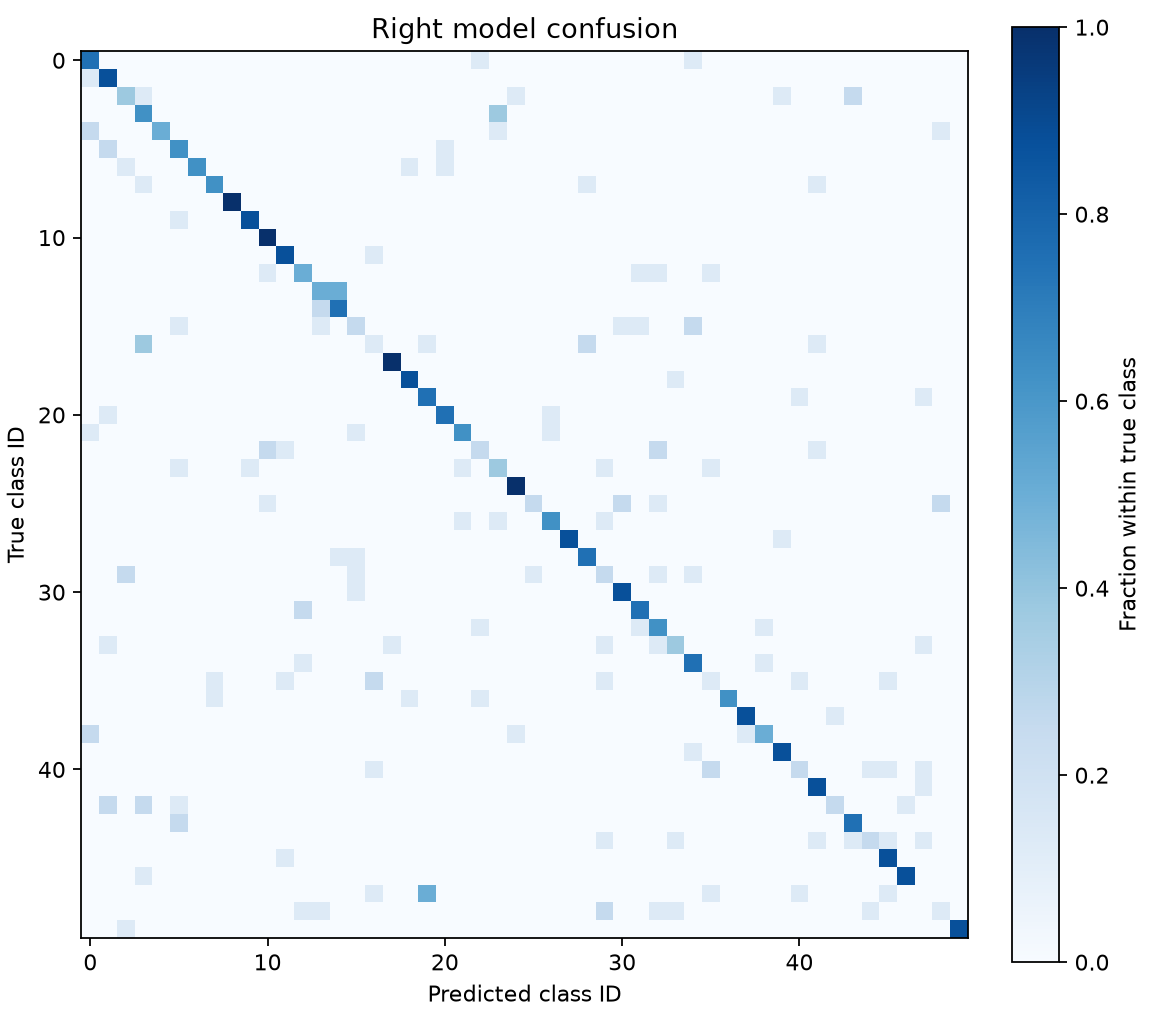

In [42]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/cnn_confusion.png'), width=1050))

### Figure 19. Historical study - CRNN (CNN + BiGRU) primary fold-5 confusion matrix

Scope: Historical baseline study; not new confirmation.

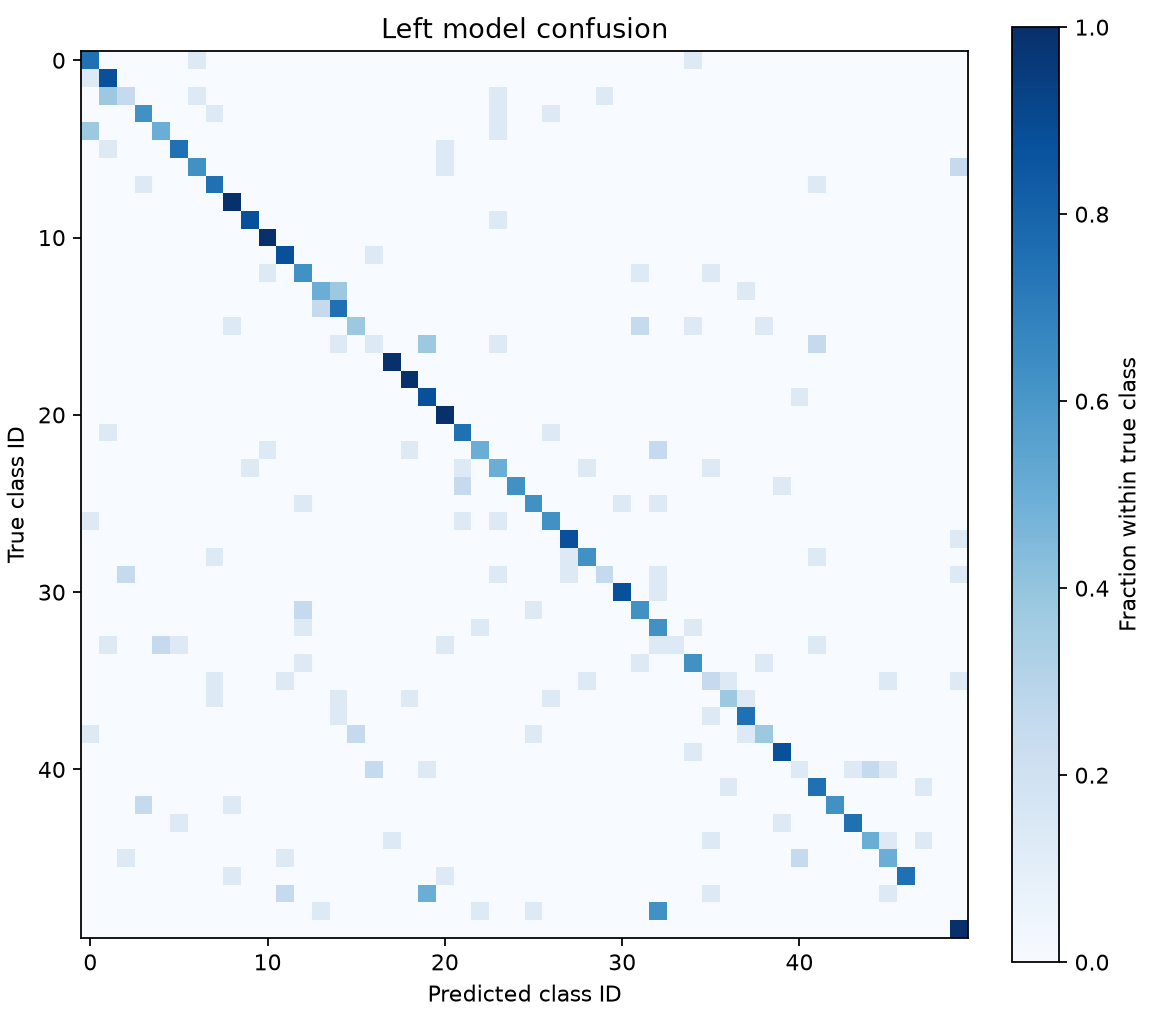

In [43]:
display(Image(filename=str(ROOT/'reports/figures/baseline_20261028/crnn_confusion.png'), width=1050))

### Figure 20. System comparison: scratch-trained references and the fixed pretrained system

Scope: Frozen PANNs transfer, development validation.

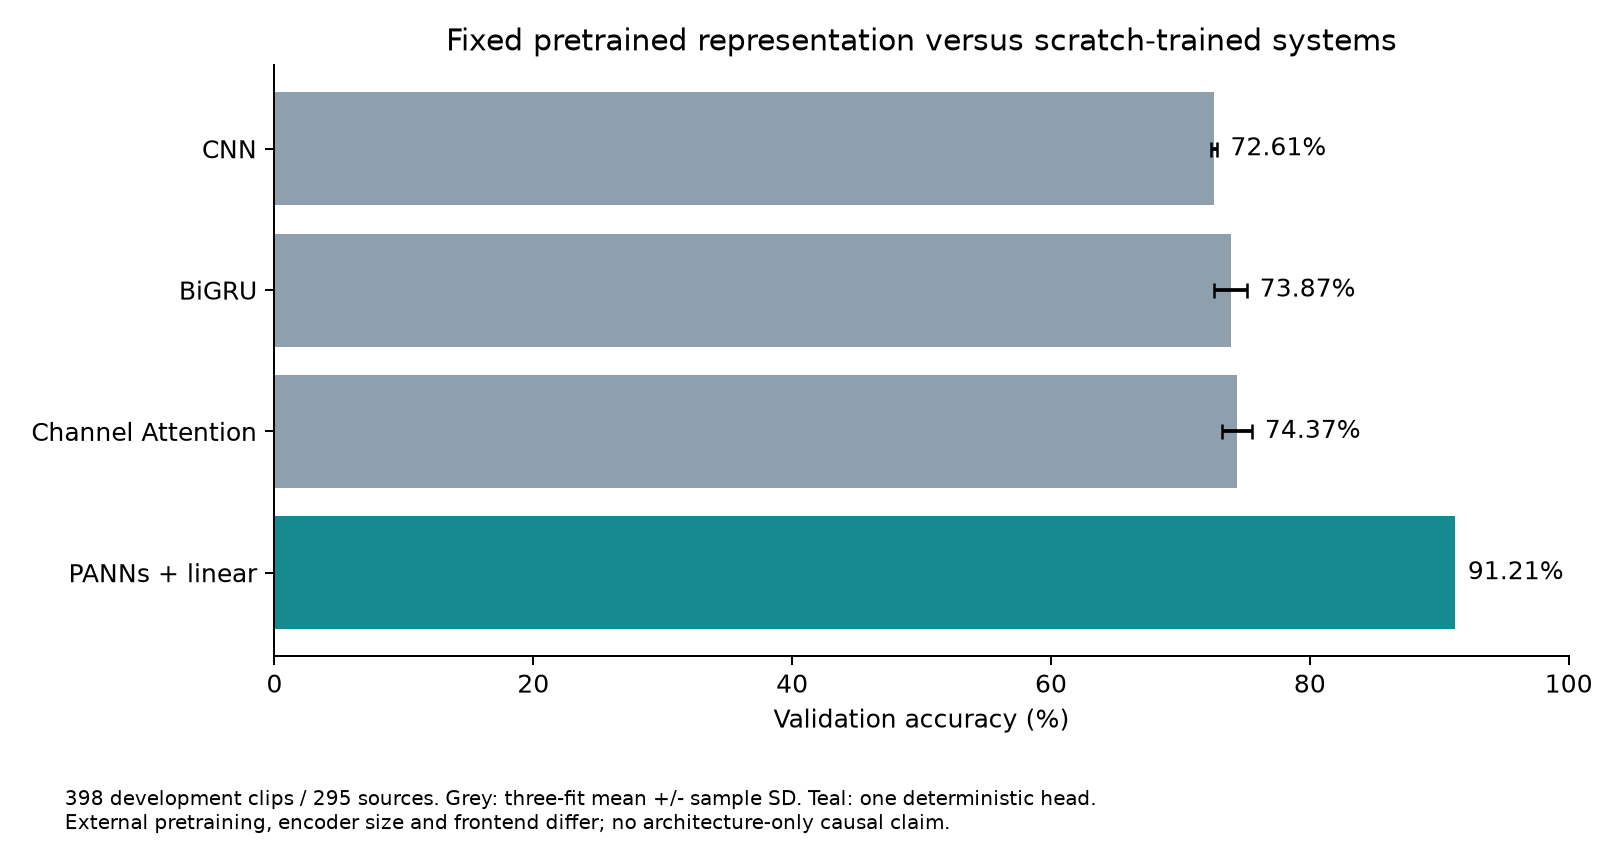

In [44]:
display(Image(filename=str(ROOT/'reports/panns_20261105/system_comparison.png'), width=1050))

### Figure 21. Paired accuracy gains with conditional source-bootstrap intervals

Scope: Frozen PANNs transfer, development validation.

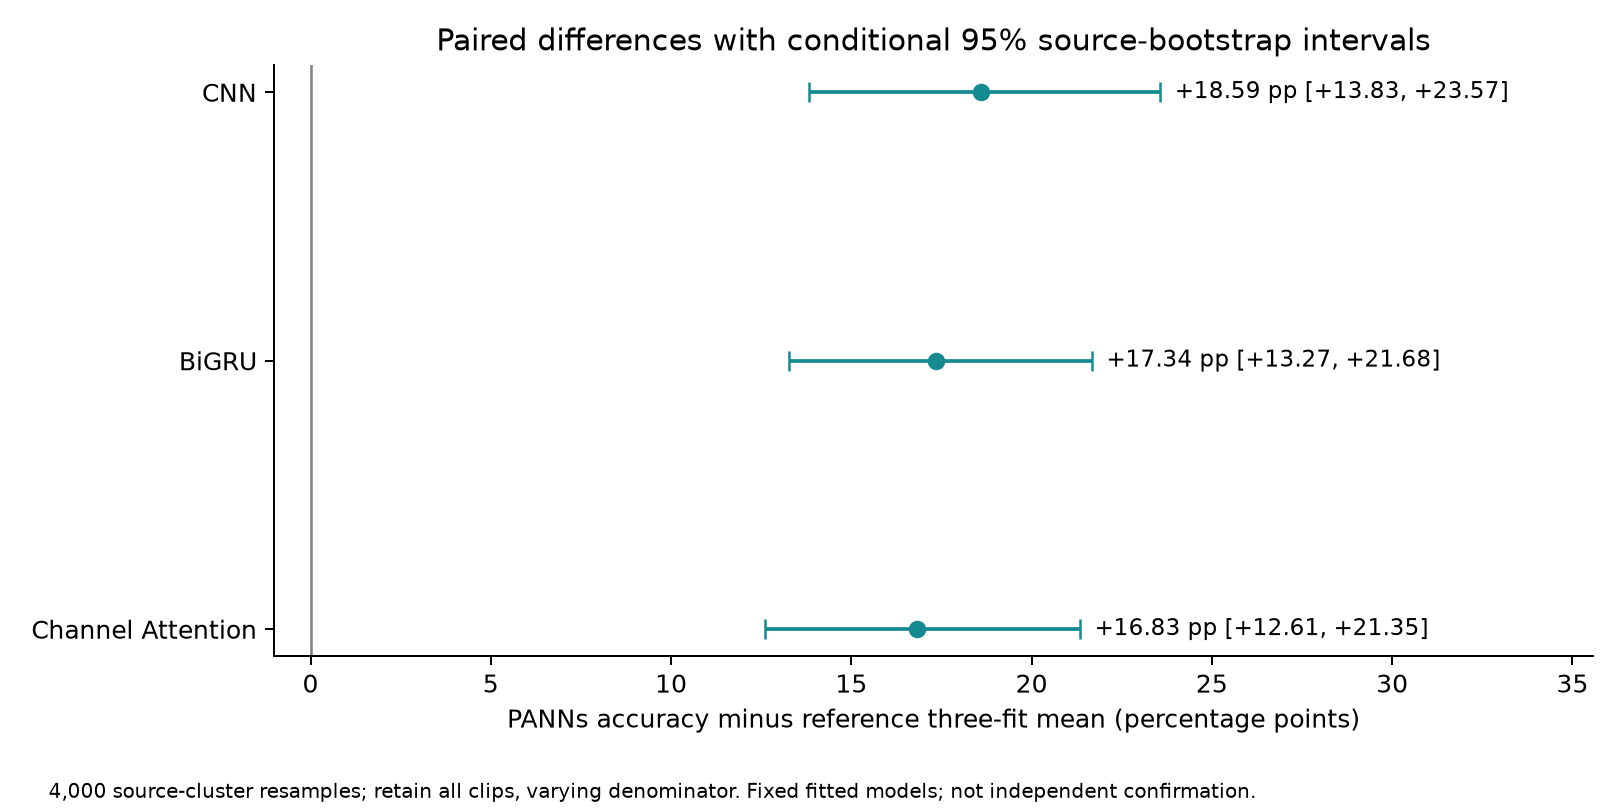

In [45]:
display(Image(filename=str(ROOT/'reports/panns_20261105/paired_accuracy_gains.png'), width=1050))

### Figure 22. All-class row-normalized confusion matrix for the fixed pretrained system

Scope: Frozen PANNs transfer, development validation.

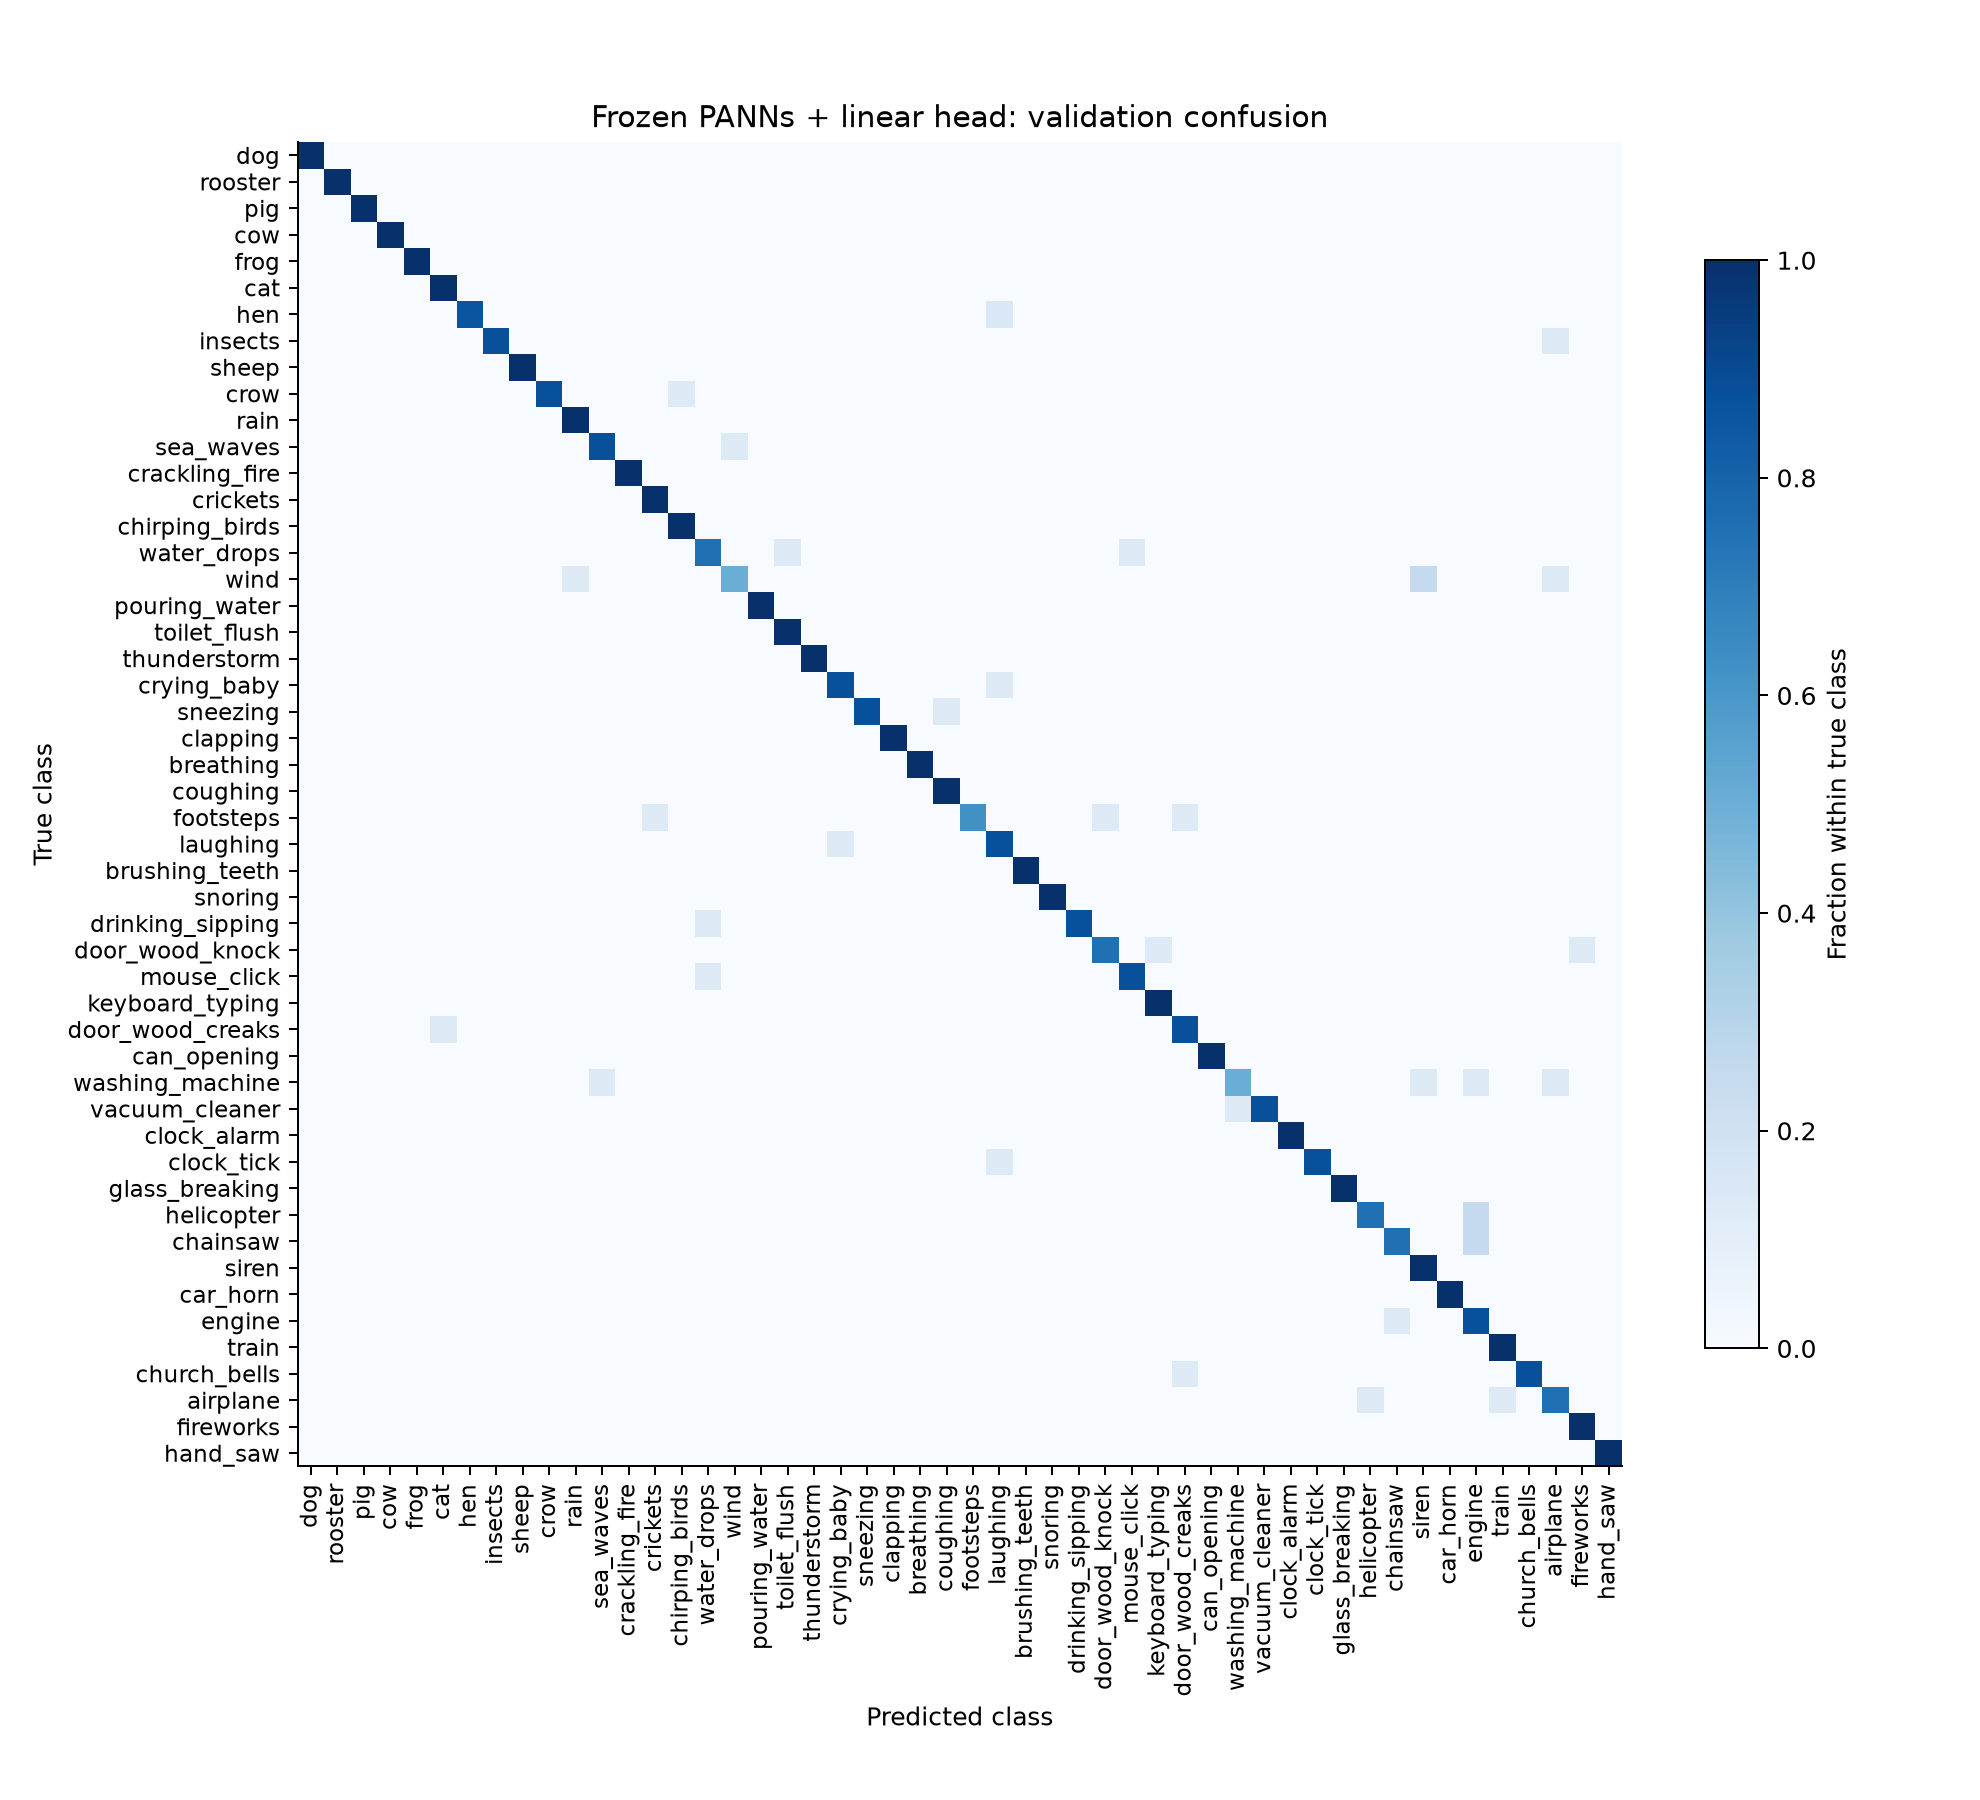

In [46]:
display(Image(filename=str(ROOT/'reports/panns_20261105/confusion_matrix.png'), width=1050))

## 9.1 Completed transfer robustness and matched-head follow-up

The new fixed experiment uses398 validation clips, 295 sources, shared clean/10 dB waveforms and four frozen backbone instances. Six additional fixed 100-epoch heads compare `2048→49→50` with Identity versus ReLU, matching initial weights, ordering, parameters and optimizer. The original logistic head is not refitted. [Executable experiment and full analysis](ESC50_Transfer_Followup.ipynb).

PANNs logistic: **69.85% noisy accuracy** versus noise-CNN mean **61.56%**, paired gain **8.29 pp [1.83, 14.74]**. PANNs loses **21.36 pp** from clean audio versus **11.56 pp** for noise-CNN. These answer different performance questions.

The ReLU head averages **89.78%** clean accuracy versus matched factorized-linear **91.12%**: **−1.34 pp [−2.52, −0.26]**. Noisy ReLU-minus-linear is **−1.42 pp [−3.05, +0.24]**. These are fixed-configuration, conditional development results.

A 49-hidden linear factorization can represent any 50-class affine softmax classifier up to a common logit offset. Its rank bound does not itself restrict that probability family; optimization/regularization differ from L-BFGS logistic regression.

For the centering matrix $C=I-\mathbf{1}\mathbf{1}^{T}/50$, $\operatorname{softmax}(z)=\operatorname{softmax}(Cz)$ and $\operatorname{rank}(CW)\leq49$. The rank statement concerns logits; common-offset invariance explains why the affine softmax family is preserved.

In [47]:
followup=ROOT/"reports/transfer_followup_20261105"
new_groups=pd.read_csv(followup/"groups.csv")
table(new_groups,3)
table(pd.read_csv(followup/"paired_effects.csv"),3)
table(pd.read_csv(followup/"accuracy_losses.csv"),3)
table(pd.read_csv(followup/"head_fits.csv"),5)

model,condition,fits,accuracy_percent,accuracy_sd_pp,macro_f1_percent,macro_f1_sd_pp
panns_lr,clean,1,91.206,—,91.103,—
panns_lr,snr_10,1,69.849,—,71.530,—
noise_cnn,clean,3,73.116,0.870,71.992,1.226
noise_cnn,snr_10,3,61.558,2.303,59.206,1.880
factorized_linear,clean,3,91.122,1.046,91.050,1.012
factorized_linear,snr_10,3,68.760,0.951,69.907,1.226
mlp_relu,clean,3,89.782,0.951,89.695,0.951
mlp_relu,snr_10,3,67.337,0.870,68.193,0.845


comparison,condition,delta_pp,low_pp,high_pp
panns_lr_minus_noise_cnn,clean,18.090,13.350,22.954
mlp_relu_minus_factorized_linear,clean,-1.340,-2.519,-0.260
factorized_linear_minus_panns_lr,clean,-0.084,-1.420,1.231
mlp_relu_minus_panns_lr,clean,-1.424,-3.159,0.163
panns_lr_minus_noise_cnn,snr_10,8.291,1.827,14.739
mlp_relu_minus_factorized_linear,snr_10,-1.424,-3.046,0.243
factorized_linear_minus_panns_lr,snr_10,-1.089,-2.917,0.597
mlp_relu_minus_panns_lr,snr_10,-2.513,-4.970,-0.087
panns_loss_minus_noise_cnn_loss,clean_to_snr10,9.799,3.193,16.624


model,delta_pp,low_pp,high_pp
panns_lr,21.357,15.980,26.667
noise_cnn,11.558,7.513,15.753
factorized_linear,22.362,17.349,27.338
mlp_relu,22.446,17.579,27.360


architecture,seed,condition,parameters,accuracy,macroF1,trainCE,iterations,time_s
factorized_linear,101,clean,102901,0.91457,0.91390,0.00014,3800,8.10097
factorized_linear,101,noise10db,102901,0.68342,0.69998,0.00014,3800,8.10097
factorized_linear,202,clean,102901,0.91960,0.91847,0.00014,3800,8.21126
factorized_linear,202,noise10db,102901,0.68090,0.68638,0.00014,3800,8.21126
factorized_linear,303,clean,102901,0.89950,0.89911,0.00014,3800,8.15673
factorized_linear,303,noise10db,102901,0.69849,0.71085,0.00014,3800,8.15673
mlp_relu,101,clean,102901,0.90201,0.90159,0.00016,3800,7.96980
mlp_relu,101,noise10db,102901,0.67839,0.68928,0.00016,3800,7.96980
mlp_relu,202,clean,102901,0.90452,0.90326,0.00015,3800,8.33850
mlp_relu,202,noise10db,102901,0.67839,0.68382,0.00015,3800,8.33850


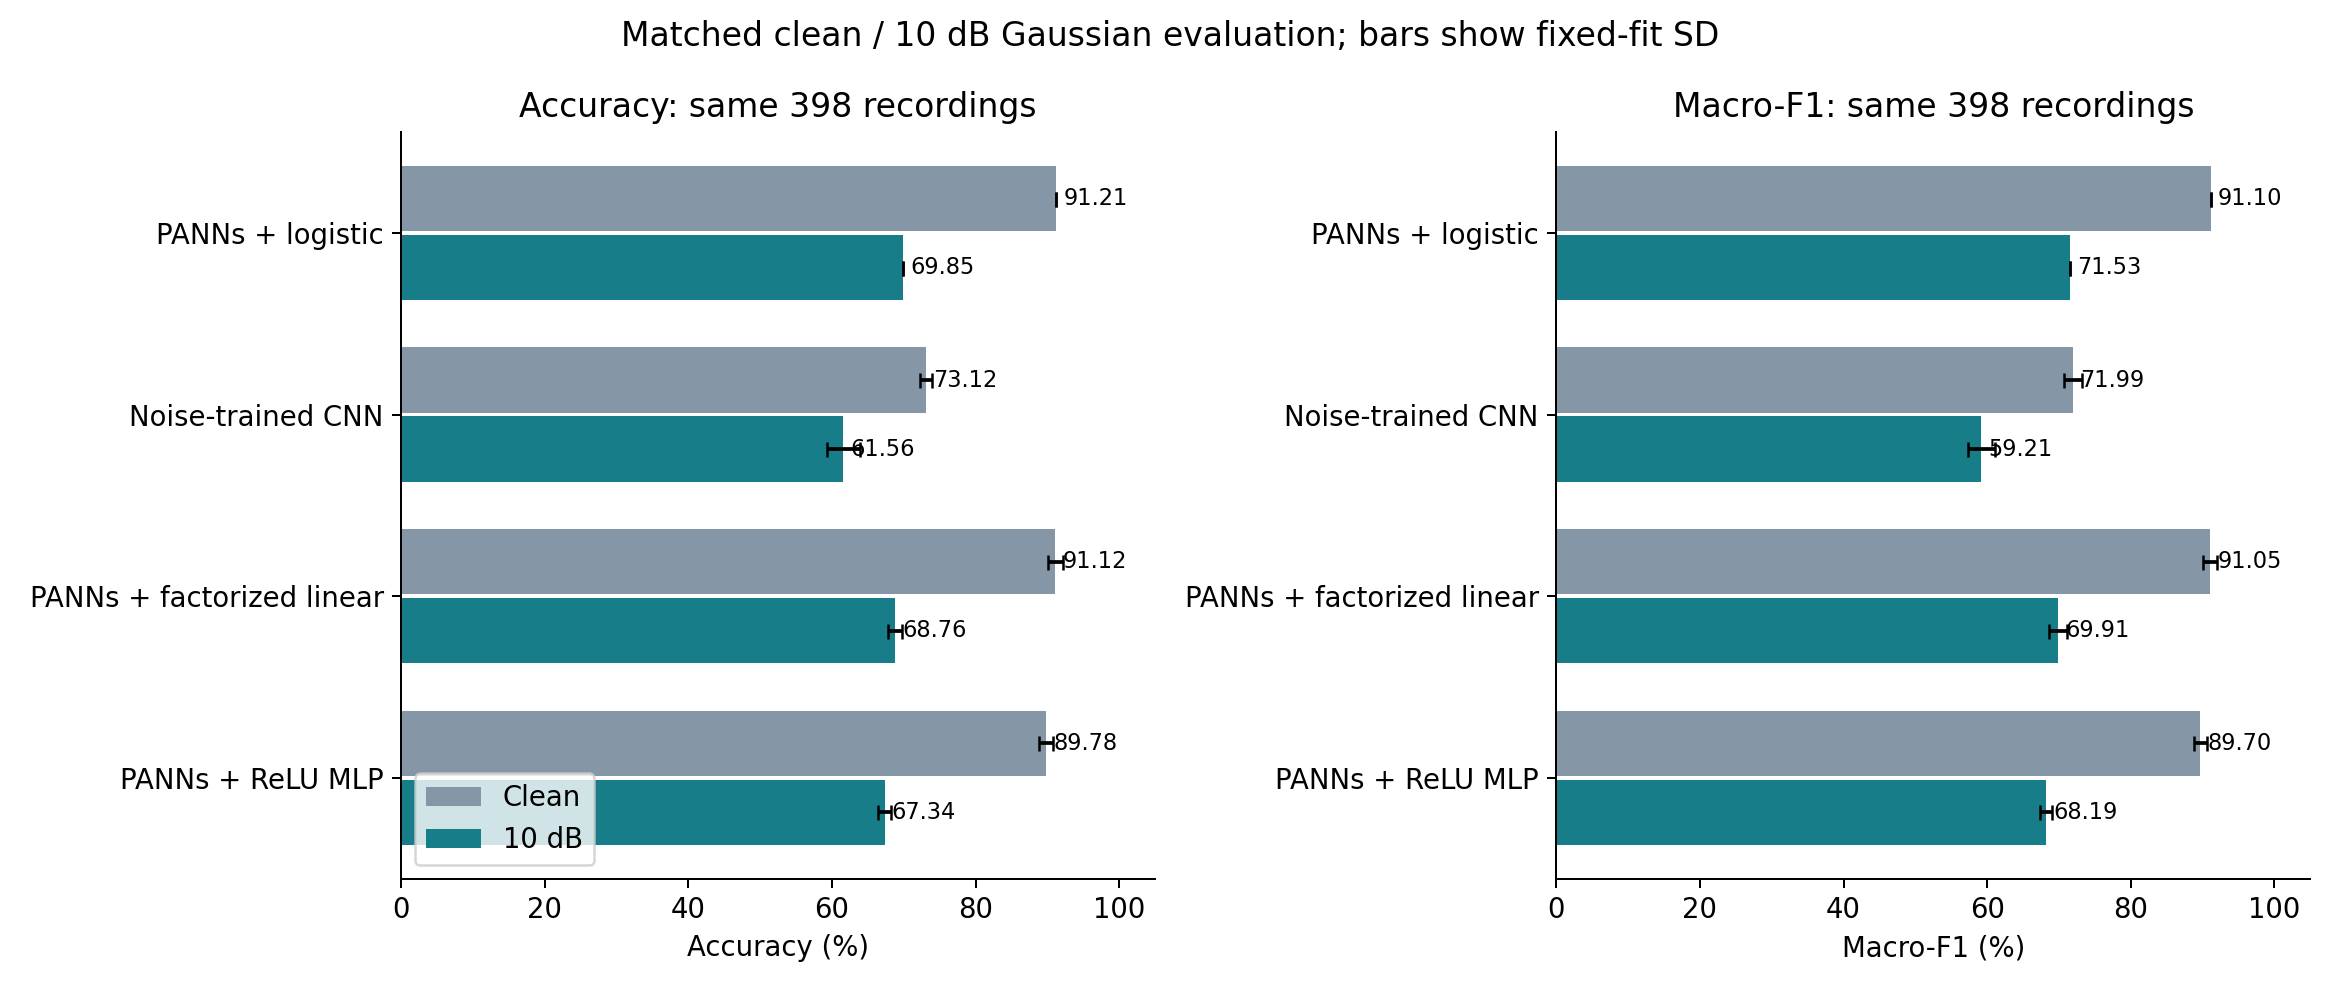

In [48]:
display(Image(filename=str(followup/"matched_robustness.png"),width=1100))

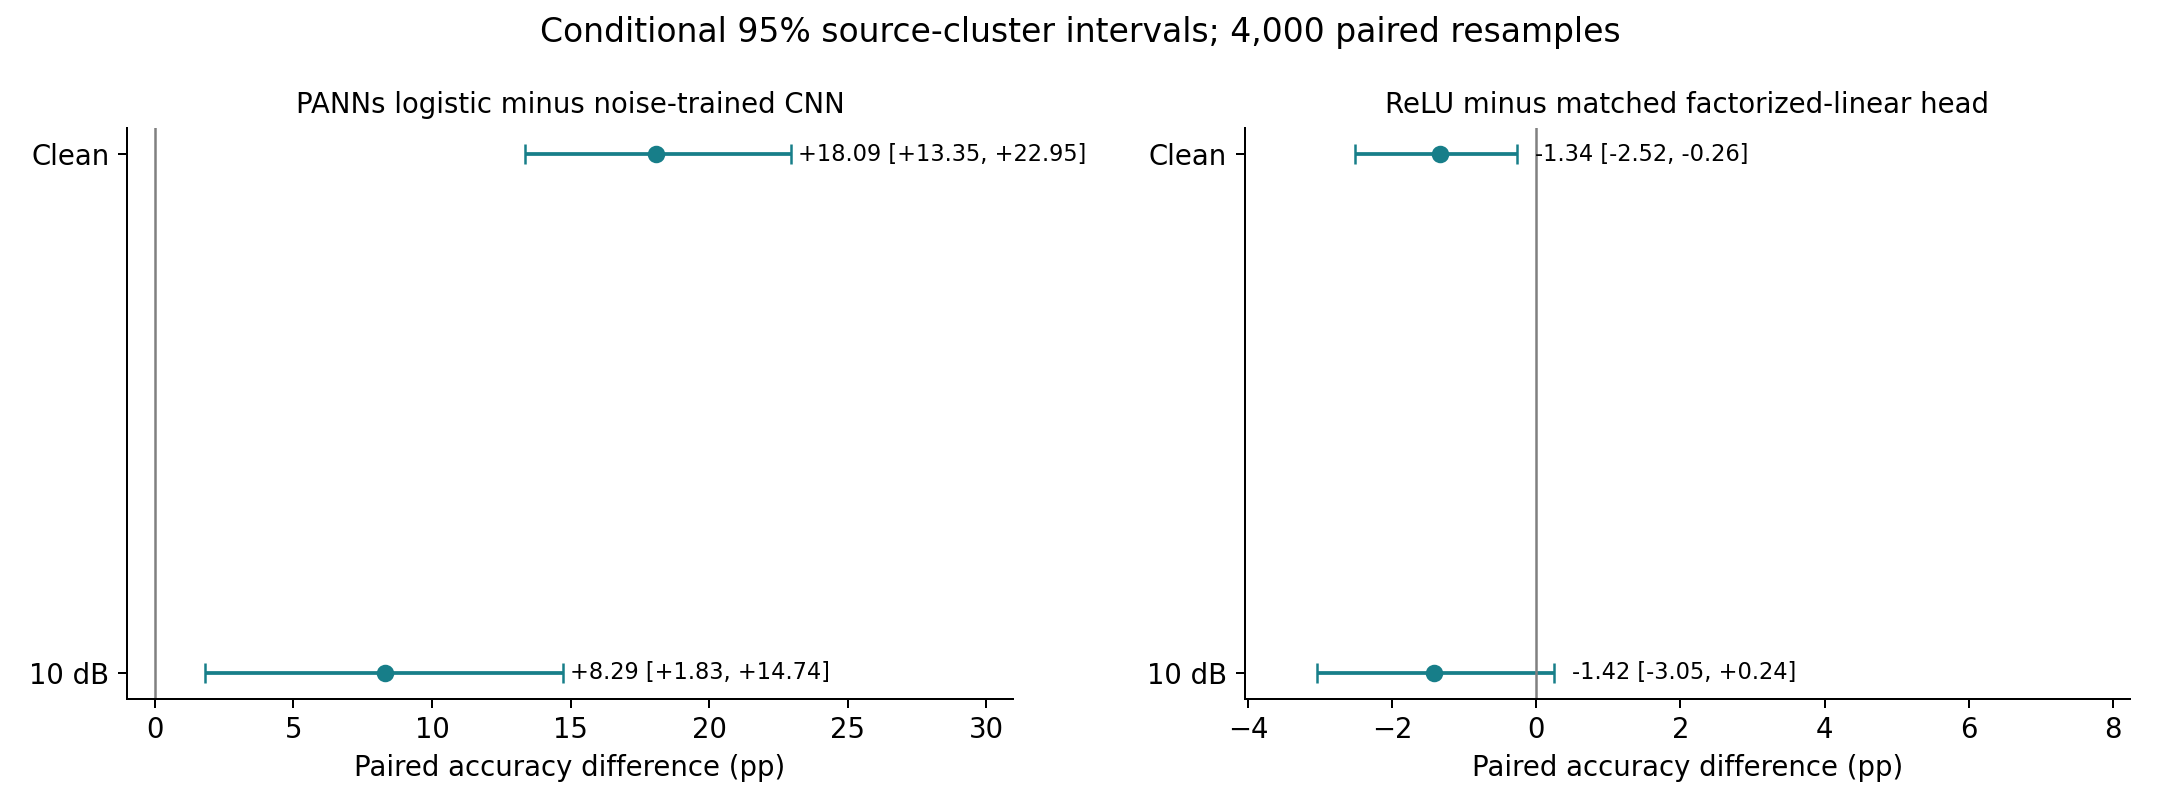

In [49]:
display(Image(filename=str(followup/"paired_transfer_effects.png"),width=1100))

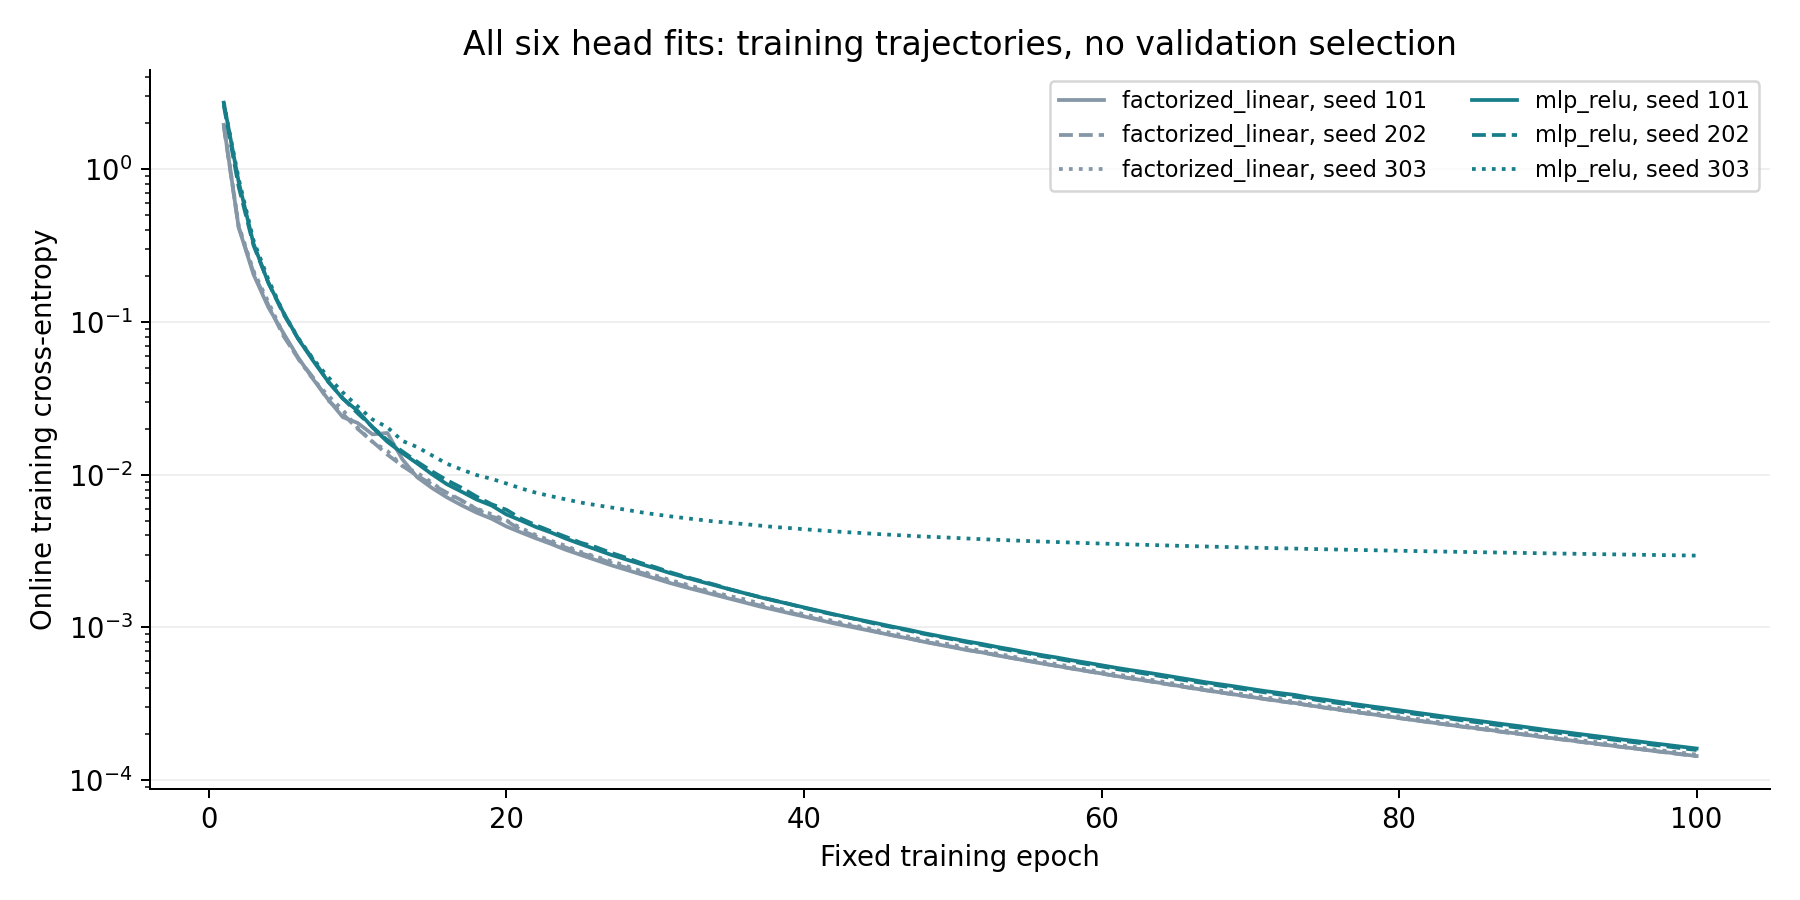

In [50]:
display(Image(filename=str(followup/"matched_head_learning_curves.png"),width=1050))

In [51]:
table(pd.read_csv(followup/"clean_noise_transitions.csv"),0)
table(pd.read_csv(followup/"common_clean_correct.csv"),3)

System,Seed,Correct to correct,Correct to wrong,Wrong to correct,Wrong to wrong
PANNs + logistic,0,265,98,13,22
Noise-trained CNN,101,221,68,26,83
Noise-trained CNN,202,217,78,18,85
Noise-trained CNN,303,232,57,21,88
PANNs + factorized linear,101,261,103,11,23
PANNs + factorized linear,202,260,106,11,21
PANNs + factorized linear,303,266,92,12,28
PANNs + ReLU MLP,101,260,99,10,29
PANNs + ReLU MLP,202,258,102,12,26
PANNs + ReLU MLP,303,250,103,14,31


Noise CNN seed,Common clean-correct clips,PANNs noisy accuracy (%),CNN noisy accuracy (%),Difference (pp),95% lower (pp),95% upper (pp)
101,275,76.364,76.364,0.000,-7.220,7.090
202,280,73.571,73.929,-0.357,-7.474,6.786
303,275,74.545,80.727,-6.182,-12.821,0.752


## 10. External recording transfer

The frozen PANNs classifier achieved **45.17% accuracy** on 259 external recordings across six mapped categories, versus **20.08%** for the mean of three frozen noise-trained CNNs. The paired difference is **+25.10 pp [+19.82, +30.63]**, a conditional 95% recording-bootstrap interval. PANNs macro recall is **46.40%** and macro-F1 **58.07%**. All 50 model outputs remained active.

Five known ESC-50 recording IDs were excluded before inference. This result concerns a mapped external subset; it does not guarantee absence of perceptual duplicates or pretraining exposure. **No new training or added-noise evaluation** occurred.

[Executed external notebook](ESC50_External_Transfer.ipynb) · [Fixed protocol](../reports/external_fsd_20261105/protocol.json). Full recordings use consecutive five-second windows and valid-duration-weighted probabilities, unlike the fixed five-second ESC-50 panel. Do not attribute absolute score differences solely to domain shift.

In [52]:
external=ROOT/"reports/external_fsd_20261105"
external_metrics=pd.read_csv(external/"metrics.csv")
table(external_metrics,4)
table(pd.read_csv(external/"paired_effects.csv"),3)
table(pd.read_csv(external/"per_class.csv"),3)

model,recordings,correct,accuracy,macro_recall,macro_f1,outside_target_rate
panns_lr,259,117,0.4517,0.4640,0.5807,0.5097
noise_cnn_s101,259,49,0.1892,0.1891,0.2865,0.7143
noise_cnn_s202,259,56,0.2162,0.2174,0.3338,0.7297
noise_cnn_s303,259,51,0.1969,0.2024,0.3043,0.7181


comparison,delta_pp,low_pp,high_pp
panns_minus_mean_noise_cnn,25.097,19.820,30.631
panns_minus_noise_cnn_s101,26.255,20.463,32.046
panns_minus_noise_cnn_s202,23.552,18.147,28.958
panns_minus_noise_cnn_s303,25.483,20.077,31.274


model,target,category,recordings,recall
panns_lr,10,rain,32,0.656
panns_lr,16,wind,40,0.150
panns_lr,22,clapping,57,0.193
panns_lr,25,footsteps,52,0.731
panns_lr,44,engine,48,0.521
panns_lr,48,fireworks,30,0.533
noise_cnn_s101,10,rain,32,0.250
noise_cnn_s101,16,wind,40,0.075
noise_cnn_s101,22,clapping,57,0.193
noise_cnn_s101,25,footsteps,52,0.250


### External recording accuracy and macro recall

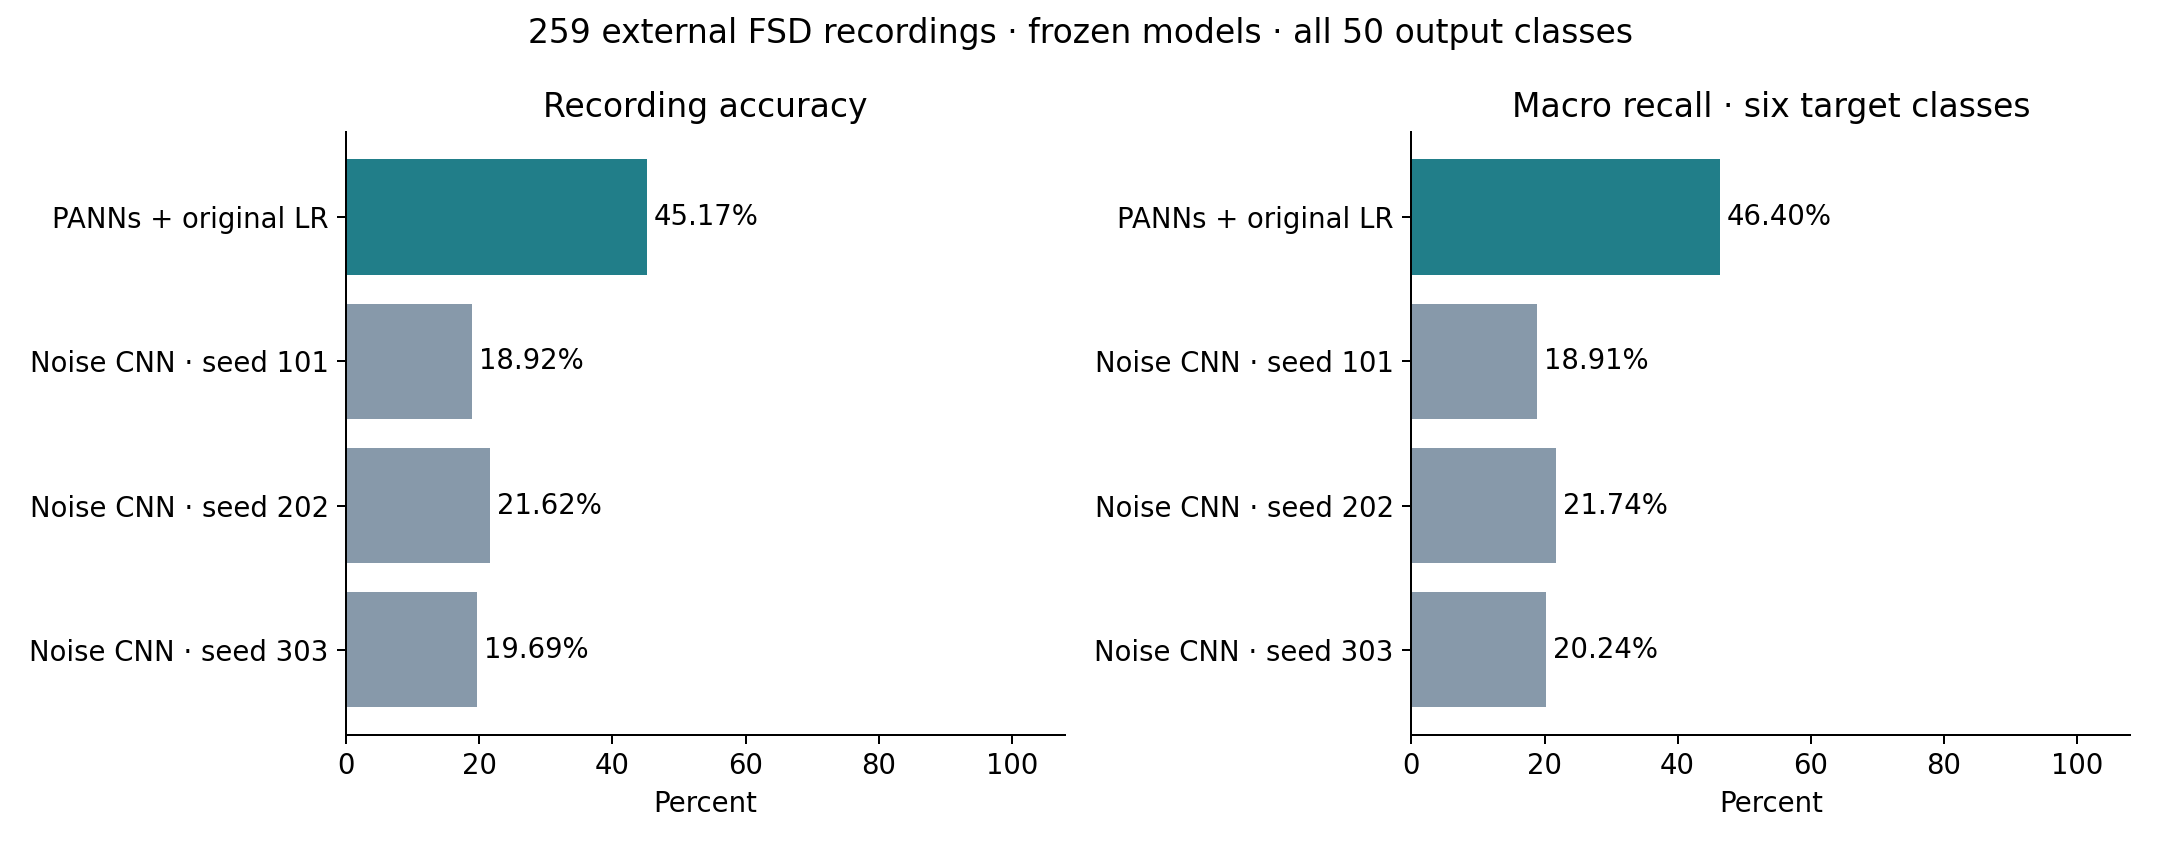

In [53]:
display(Image(filename=str(external/"external_accuracy.png"),width=1100))

### External paired recording-bootstrap effects

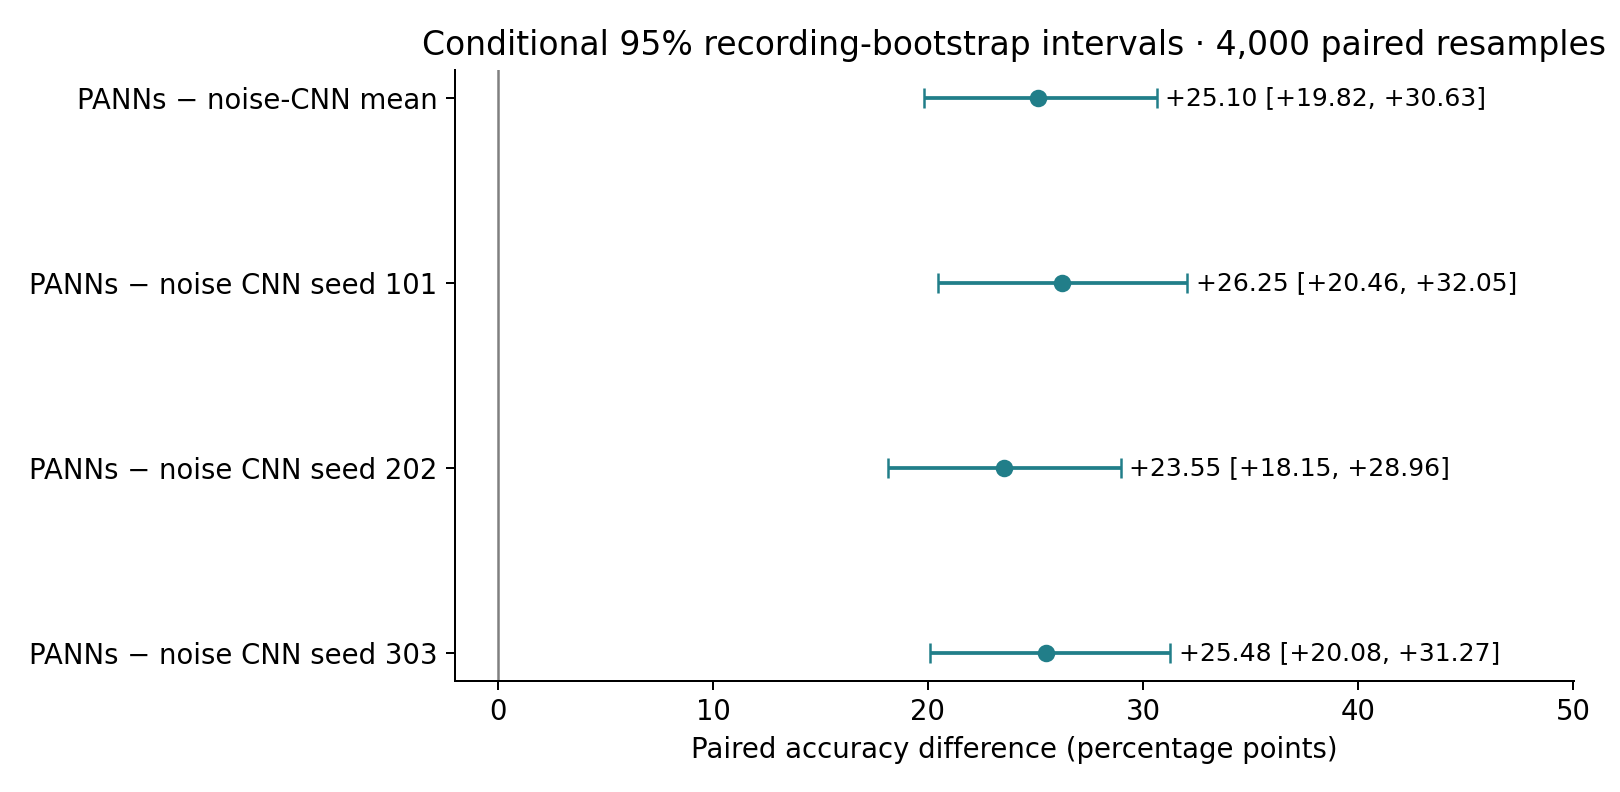

In [54]:
display(Image(filename=str(external/"external_paired_effects.png"),width=1100))

### External six-class recall

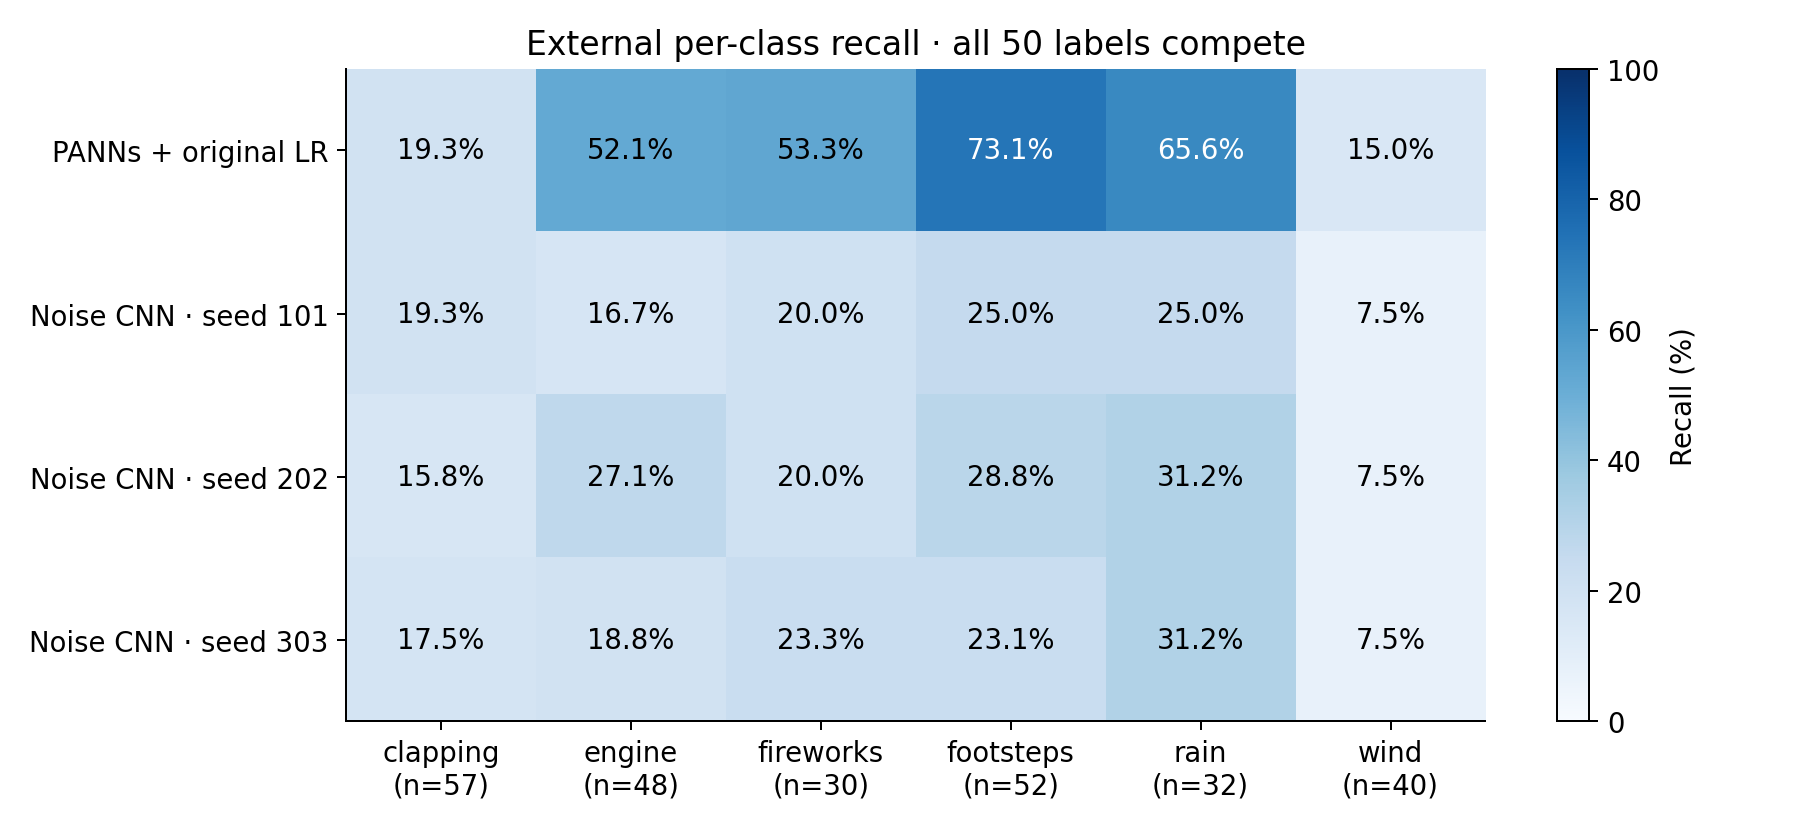

In [55]:
display(Image(filename=str(external/"external_class_recall.png"),width=1100))

### External PANNs confusion counts

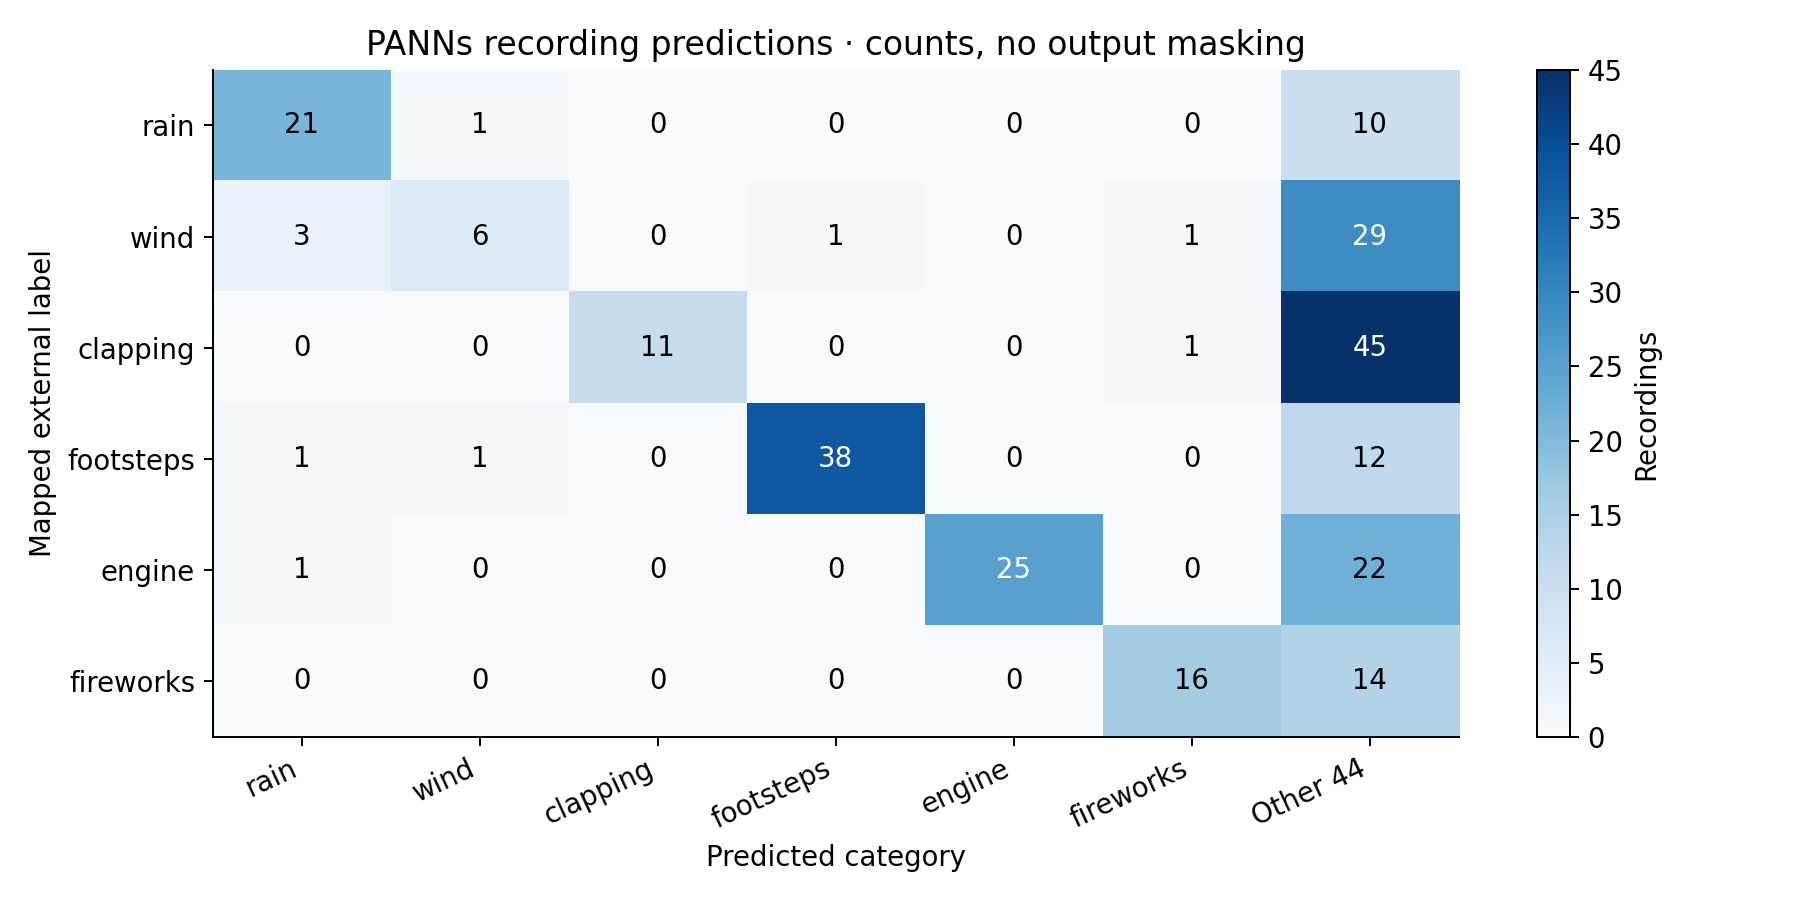

In [56]:
display(Image(filename=str(external/"external_confusion.png"),width=1100))

## 11. Short-recording input-policy diagnostic

On the same **102 eligible short recordings**, right-padding gives **28/102 correct (27.45%)**, native duration **34/102 (33.33%)**, and left-padding **27/102 (26.47%)**. Native-minus-right is **+5.88 pp [−0.98, +12.75]**, conditional 95% recording-bootstrap interval. Its accuracy advantage is uncertain.

Native input changes 46 predictions (ten repairs, four new errors). Left-padding changes 50 predictions on the same subset with little net accuracy change. Three clips below the architecture minimum of 4,960 samples are excluded only from native inference, not from the original benchmark. All 105 original baseline labels and ten identical-input controls reproduce without changes.

[Executed diagnostic notebook](ESC50_Duration_Diagnostic.ipynb) · [Fixed protocol and evidence](../reports/duration_probe_20261105/README.md). No training, extra policy search or selected hybrid score follows these results. The original 259-recording benchmark and default inference policy remain unchanged.

In [57]:
duration_data=ROOT/"reports/duration_probe_20261105"
duration_metrics=pd.read_csv(duration_data/"metrics.csv")
table(duration_metrics,4)
table(pd.read_csv(duration_data/"paired_effects.csv"),3)
table(pd.read_csv(duration_data/"transitions.csv"),3)

policy,population,recordings,correct,accuracy,macro_recall,macro_f1,outside_six_rate
right_pad,all_short,105,29,0.2762,0.3231,0.4421,0.7143
right_pad,native_eligible,102,28,0.2745,0.3194,0.4398,0.7157
native,native_eligible,102,34,0.3333,0.3429,0.4592,0.5784
left_pad,all_short,105,27,0.2571,0.2703,0.3890,0.7238
left_pad,native_eligible,102,27,0.2647,0.2739,0.3942,0.7157


comparison,population,recordings,delta_pp,low_pp,high_pp
native_minus_right_pad,native_eligible,102,5.882,-0.980,12.745
left_pad_minus_right_pad,native_eligible,102,-0.980,-7.843,5.882
left_pad_minus_right_pad,all_short,105,-1.905,-8.571,4.762


policy,population,recordings,prediction_flips,both_correct,repairs,new_errors,both_wrong,mean_true_class_probability_change
native,native_eligible,102,46,24,10,4,64,0.063
left_pad,native_eligible,102,50,21,6,7,68,-0.019
left_pad,all_short,105,53,21,6,8,70,-0.022


### Accuracy on the same 102 short recordings

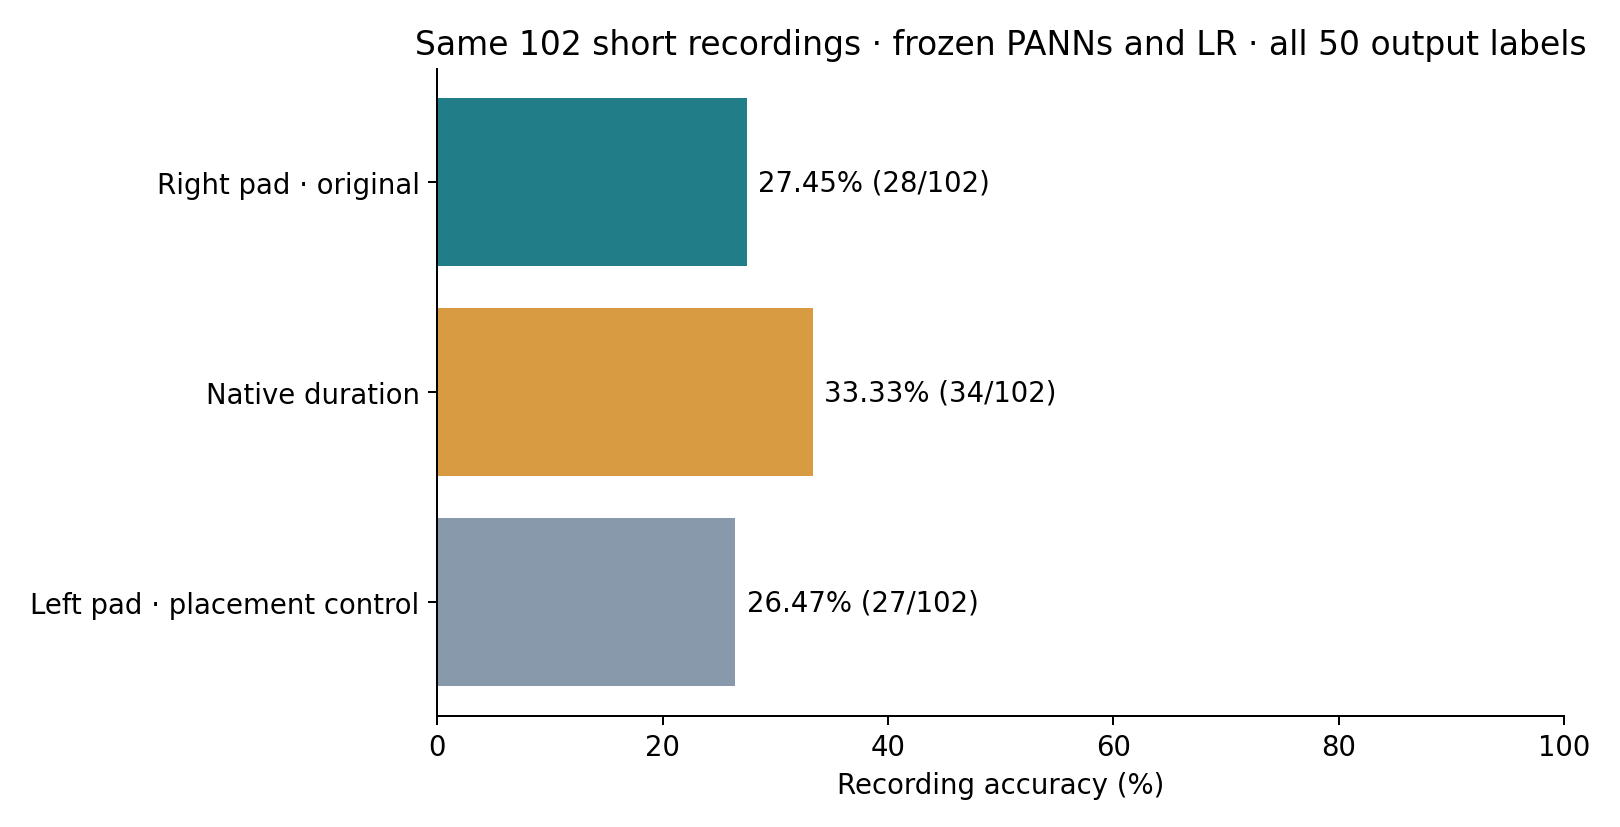

In [58]:
display(Image(filename=str(duration_data/"duration_policy_accuracy.png"),width=1100))

### Input-policy paired recording-bootstrap effects

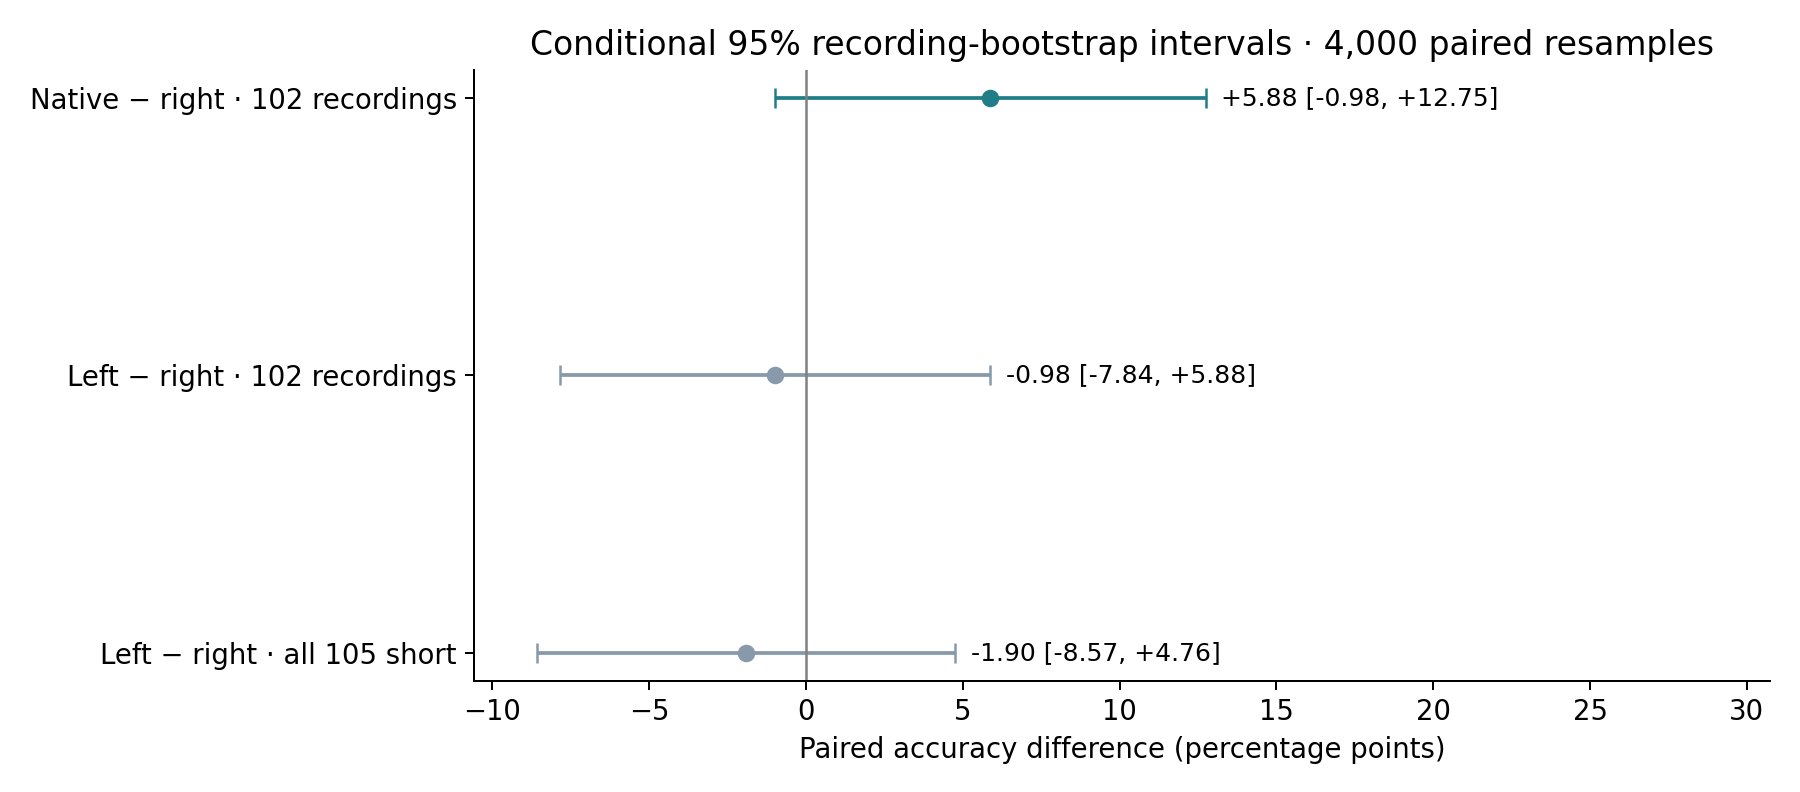

In [59]:
display(Image(filename=str(duration_data/"duration_policy_effects.png"),width=1100))

### Input-policy six-class recall

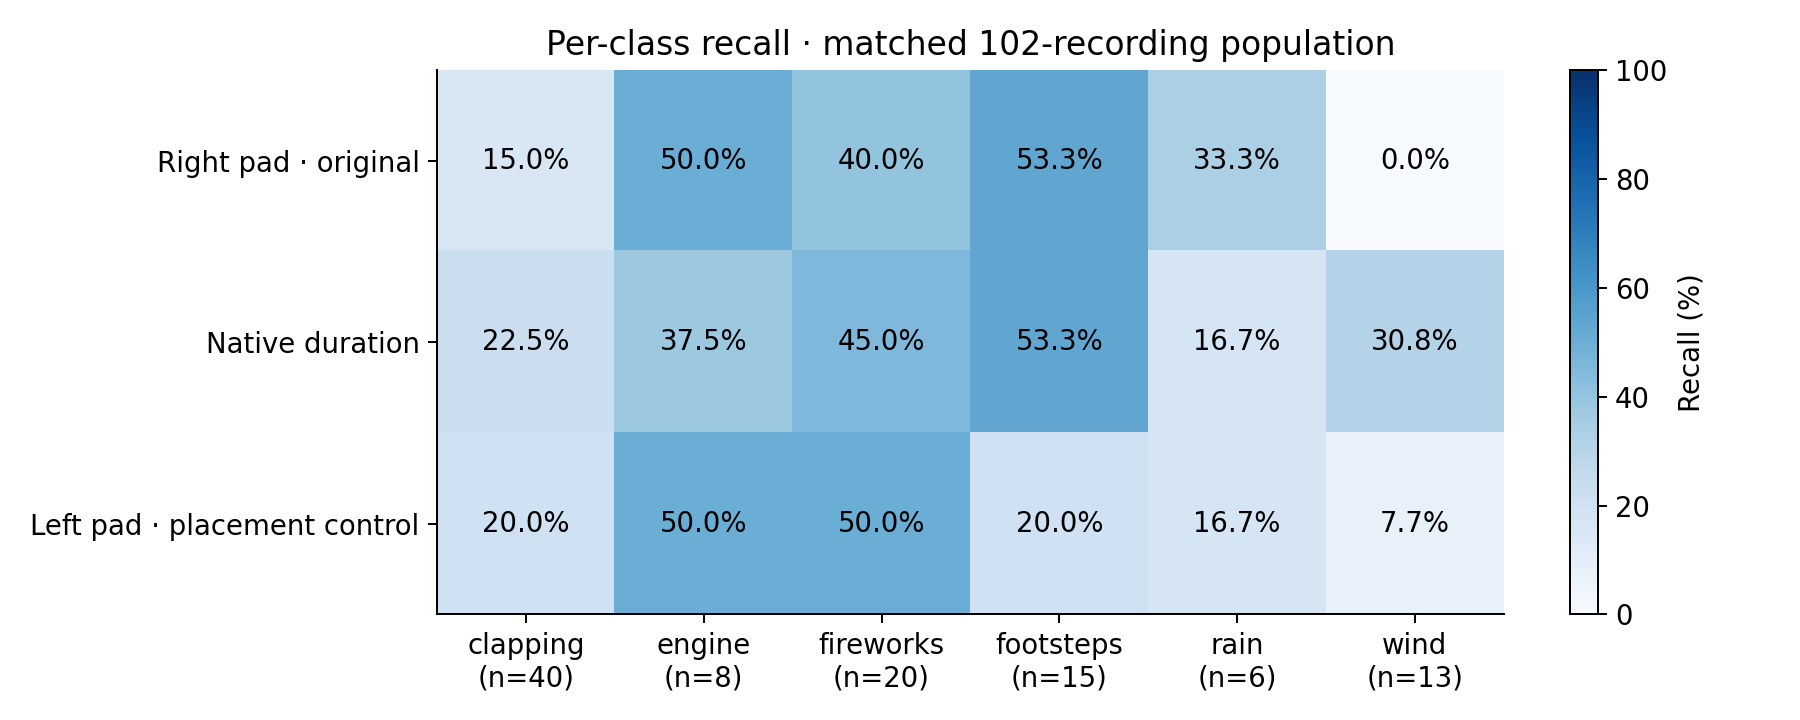

In [60]:
display(Image(filename=str(duration_data/"duration_policy_class_recall.png"),width=1100))

Global temporal pooling is invariant to reordering the same encoded tokens. Moving raw waveform padding can change the encoder outputs through STFT boundaries, strided downsampling and convolutional context. These are different interventions; the earlier encoded-token invariance result does not imply raw waveform shift invariance. The present probe measures input-policy sensitivity and does not identify a single internal mechanism.

## 12. Gaussian-to-recorded-noise transfer

Two matched PANNs linear heads test transfer from Gaussian training exposure to six fixed recorded-background conditions. The primary difference is **+1.05 pp [-0.54, +2.59]**, conditional 95% source-bootstrap interval. Clean change is **+0.75 pp**. See the [executed experiment](ESC50_Noise_Transfer.ipynb) for the frozen protocol and computations. This is conditional noise transfer on exposed targets, not new-target generalization or field deployment.

In [ ]:
noise_transfer_data = ROOT/"reports/noise_transfer_20261106"
noise_transfer_metrics = pd.read_csv(noise_transfer_data/"metrics.csv")
display(noise_transfer_metrics.assign(accuracy=lambda d:100*d.accuracy,macro_f1=lambda d:100*d.macro_f1).round(2))
display(pd.read_csv(noise_transfer_data/"paired_effects.csv").round(2))

,model,condition,accuracy,macro_f1,correct,clips
0,clean_refit,clean,91.21,91.10,363,398
1,gaussian_adapted,clean,91.96,91.96,366,398
2,historical_lr,clean,91.21,91.10,363,398
3,clean_refit,historical_shared_gaussian10,69.85,71.53,278,398
4,gaussian_adapted,historical_shared_gaussian10,83.92,83.93,334,398
5,historical_lr,historical_shared_gaussian10,69.85,71.53,278,398
6,clean_refit,NRIVER_30s,85.43,85.95,340,398
7,gaussian_adapted,NRIVER_30s,89.45,89.55,356,398
8,historical_lr,NRIVER_30s,85.43,85.95,340,398
9,clean_refit,NRIVER_150s,86.93,87.06,346,398


,condition,delta_pp,low_pp,high_pp
0,clean,0.75,-0.51,2.06
1,historical_shared_gaussian10,14.07,10.20,18.32
2,NRIVER_30s,4.02,1.25,6.79
3,NRIVER_150s,2.26,0.00,4.55
4,OHALLWAY_30s,1.51,-0.26,3.51
5,OHALLWAY_150s,-1.76,-3.87,0.49
6,TCAR_30s,0.00,-2.05,2.01
7,TCAR_150s,0.25,-1.79,2.22
8,recorded_mean_primary,1.05,-0.54,2.59
9,NRIVER_mean,3.14,0.76,5.50


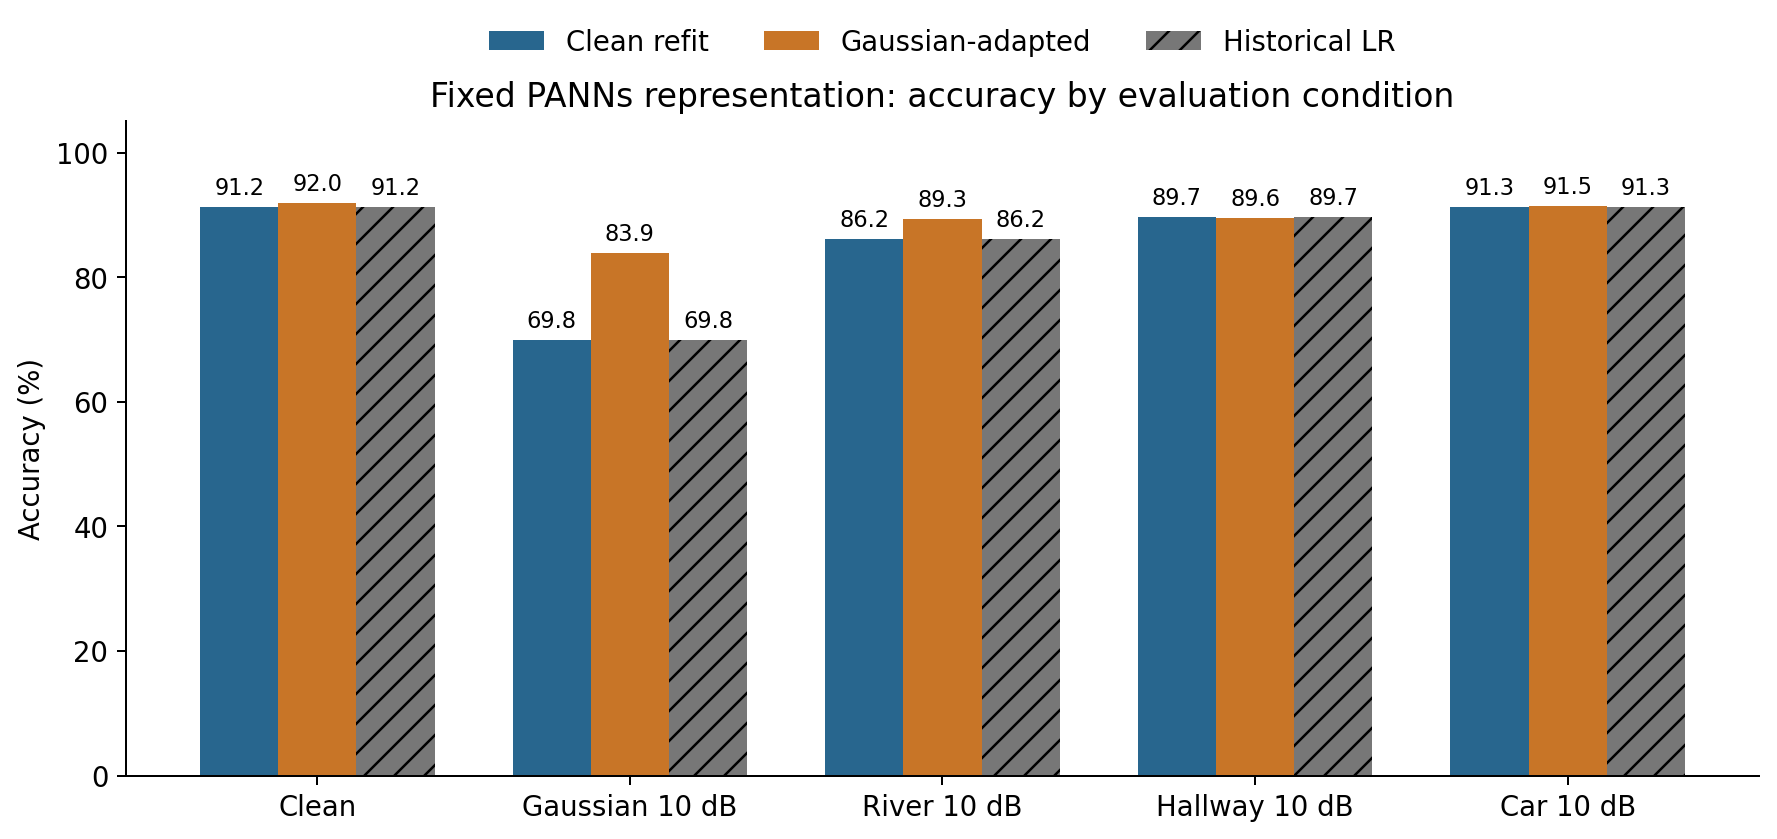

In [ ]:
display(Image(filename=str(noise_transfer_data/"accuracy_by_environment.png"),width=1100))

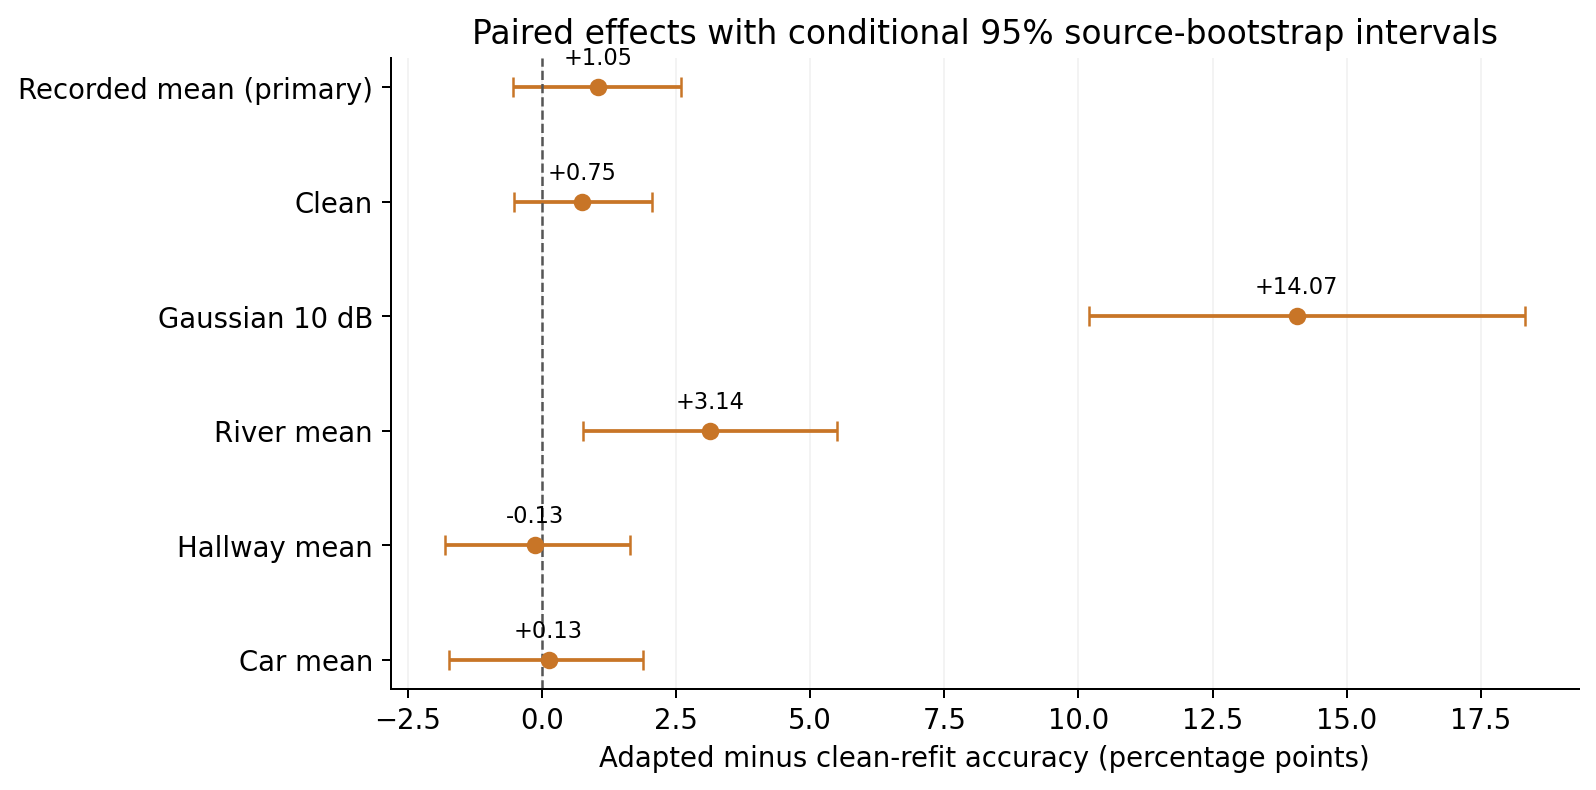

In [ ]:
display(Image(filename=str(noise_transfer_data/"paired_accuracy_effects.png"),width=1100))

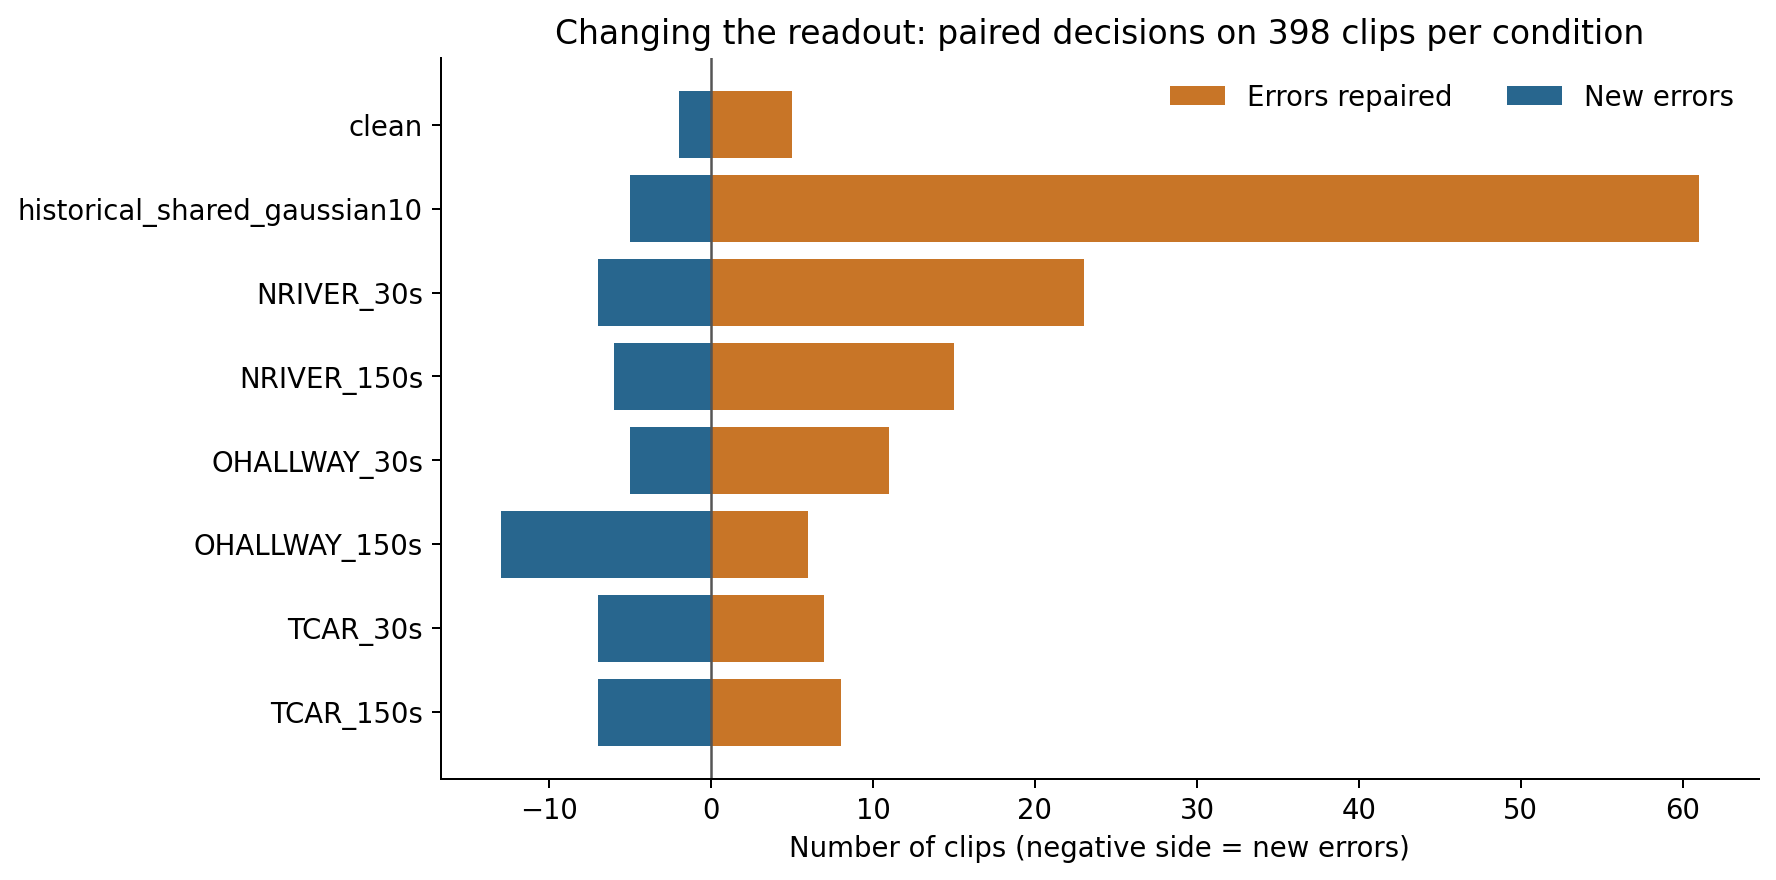

In [ ]:
display(Image(filename=str(noise_transfer_data/"paired_error_transitions.png"),width=1100))

All backgrounds were absent from head training. The adapted head sees the same 1,200 labelled target recordings as the clean head; waveform noise exposure changes, while the encoder, scaler and effective regularization stay fixed. Recorded means average six fixed conditions. Backgrounds can contain competing events, and the label denotes the designated foreground. Source intervals condition on the fixed environments and fits. No further model or augmentation was selected from these outcomes.

## 13. Findings and next steps

1. **The alternative pretrained system gives the largest observed clean-accuracy gain.** Compare its full-system performance with the smaller scratch models while retaining the differences in data, capacity, frontend and classifier.
2. **Attention adds a small uncertain gain.** The existing three-seed study does not support more attention training merely to obtain a higher selected score.
3. **Noise augmentation gives a substantial matched-noise benefit.** It does not establish robustness to environmental noise, microphones or rooms, and its advantage under gain changes is limited.
4. **Temporal modelling changes which recordings are classified correctly.** Encoder-token reversals provide a sensitivity diagnostic, not a causal explanation of raw-audio temporal mechanisms.
5. **The matched clean/10 dB comparison is now complete.** PANNs has higher absolute noisy accuracy, while noise-trained CNN loses fewer points. The fixed ReLU head did not improve performance. The external mapped-recording evaluation is now complete: PANNs remains comparatively stronger, but its 45.17% accuracy and 50.97% outside-six prediction rate limit any claim of reliable external recognition.
6. **Gaussian-adapted linear readouts improve matched Gaussian performance, with uncertain transfer to recorded backgrounds.** Gaussian accuracy rises from 69.85% to 83.92%; the six-condition recorded mean changes from 89.07% to 90.12%, +1.05 pp with conditional interval [−0.54, +2.59]. Clean change is +0.75 pp with interval [−0.51, +2.06]. Neither general recorded-noise superiority nor clean noninferiority is established.

The checkpoint implements and evaluates several established improvements, including negative results. No new architecture, state-of-the-art claim, or independent generalisation result is asserted.

In [61]:
receipt = {"completed_utc": datetime.now(timezone.utc).isoformat(),
           "original_panns_fit_repeated_in_this_execution": RUN_TRANSFER,
           "validation_clips": len(targets), "validation_sources": len(set(source_ids)),
           "new_accuracy": float(panns_accuracy), "new_macro_f1": float(panns_f1),
           "correct": int(new_correct.sum()), "converged": transfer_summary["converged"],
           "saved_figure_count": len(json.loads((ROOT/"reports/scientific_figures.json").read_text())),
           "existing_matrix_tasks": len(all_runs), "existing_robustness_conditions": len(robust_runs),
           "existing_temporal_conditions": len(temporal), "runtime": runtime}
print(json.dumps(receipt, indent=2))
if RUN_TRANSFER:
    (RUN_DIR/"notebook_execution.json").write_text(json.dumps(receipt, indent=2))

{
  "completed_utc": "2026-11-05T23:15:18.161148+00:00",
  "original_panns_fit_repeated_in_this_execution": false,
  "validation_clips": 398,
  "validation_sources": 295,
  "new_accuracy": 0.9120603015075377,
  "new_macro_f1": 0.9110258659469186,
  "correct": 363,
  "converged": true,
  "saved_figure_count": 36,
  "existing_matrix_tasks": 65,
  "existing_robustness_conditions": 54,
  "existing_temporal_conditions": 30,
  "runtime": {
    "python": "3.13.16",
    "torch": "2.11.0+cu130",
    "numpy": "2.4.6",
    "gpu": "Tesla T4",
    "platform": "Linux-6.6.159+-x86_64-with-glibc2.39"
  }
}
